Loaded existing split.csv (2185 rows). Not regenerating.

Split sizes:
 label  cancer  non_cancer   All
split                          
test      178         151   329
train     828         700  1528
val       178         150   328
All      1184        1001  2185

Split proportions: {'train': 0.699, 'test': 0.151, 'val': 0.15}
train/val: zero overlap OK (min pHash distance across splits = 6)
train/test: zero overlap OK (min pHash distance across splits = 8)
val/test: zero overlap OK (min pHash distance across splits = 14)


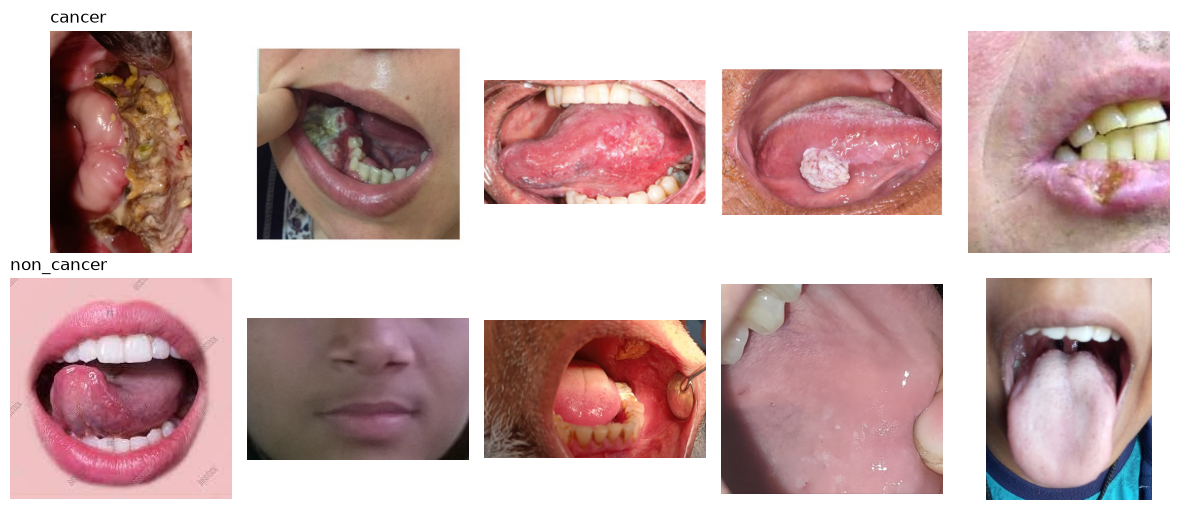


Step 02 done.


In [7]:
# %% Step 02: exploration + leakage-controlled group split
import hashlib
from collections import Counter
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import imagehash
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
PHASH_MAX_DIST = 4          # Hamming distance (of 64 bits) counted as near-duplicate
ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")
DATA = ROOT / "dataset"
SPLIT_CSV = ROOT / "split.csv"
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
for d in ["results", "figures", "checkpoints"]:
    (ROOT / d).mkdir(exist_ok=True)

if SPLIT_CSV.exists():
    # ---- split is frozen: load, never regenerate ----
    df = pd.read_csv(SPLIT_CSV)
    print(f"Loaded existing {SPLIT_CSV.name} ({len(df)} rows). Not regenerating.")
else:
    # ---- 1. scan + hash ----
    files = sorted(p for p in DATA.rglob("*") if p.suffix.lower() in EXTS)
    print(f"Image files found: {len(files)}")
    rows, bad = [], []
    for p in files:
        rel = p.relative_to(DATA)
        if len(rel.parts) < 2:
            raise SystemExit(f"{rel} is not inside a class subfolder. Paste your folder layout.")
        try:
            with Image.open(p) as im:
                im.load()
                w, h = im.size
                ph = str(imagehash.phash(im.convert("RGB")))
            rows.append(dict(path=rel.as_posix(), label=rel.parts[0], w=w, h=h,
                             md5=hashlib.md5(p.read_bytes()).hexdigest(), phash=ph))
        except Exception as e:
            bad.append((rel.as_posix(), repr(e)))
    df = pd.DataFrame(rows)
    print(f"Unreadable files: {len(bad)}", bad[:5])

    top = set(df.label.unique())
    if top & {"train", "val", "valid", "validation", "test"}:
        raise SystemExit(f"Top-level folders look like pre-made splits: {top}. Paste your layout.")

    # ---- 2. exploration ----
    print("\nClass counts:\n", df.label.value_counts().to_string())
    print("\nTop image sizes (w, h):", Counter(zip(df.w, df.h)).most_common(5))

    # ---- 3. duplicate groups: exact (MD5) + near (pHash) via union-find ----
    n = len(df)
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    for _, idx in df.groupby("md5").indices.items():
        for j in idx[1:]:
            union(idx[0], j)
    n_exact_groups = int((df.md5.value_counts() > 1).sum())

    bits = np.array([np.unpackbits(np.frombuffer(bytes.fromhex(h), dtype=np.uint8))
                     for h in df.phash], dtype=np.float32)
    D = 64 - (bits @ bits.T + (1 - bits) @ (1 - bits).T)       # pairwise Hamming
    near_pairs = np.argwhere(np.triu(D <= PHASH_MAX_DIST, k=1))
    for a, b in near_pairs:
        union(int(a), int(b))
    df["group"] = pd.factorize(np.array([find(i) for i in range(n)]))[0]   # FIXED

    gsize = df.group.value_counts()
    print(f"\nExact-duplicate MD5 groups: {n_exact_groups}")
    print(f"Near-duplicate pairs (pHash <= {PHASH_MAX_DIST}): {len(near_pairs)}")
    print(f"Unique groups: {df.group.nunique()} of {n} images | "
          f"groups with >1 image: {(gsize > 1).sum()} | largest group: {gsize.max()}")
    conflict = df.groupby("group").label.nunique()
    print(f"Groups containing conflicting labels: {(conflict > 1).sum()}")

    # ---- 4. stratified group split 70/15/15 (20 buckets: 14 / 3 / 3) ----
    group_label = df.groupby("group").label.agg(lambda s: s.mode().iloc[0])
    y = df.group.map(group_label)
    bucket = np.zeros(n, dtype=int)
    sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
    for i, (_, idx) in enumerate(sgkf.split(df, y, df.group)):
        bucket[idx] = i
    df["split"] = np.where(bucket < 14, "train", np.where(bucket < 17, "val", "test"))
    classes = sorted(df.label.unique())
    df["label_id"] = df.label.map({c: i for i, c in enumerate(classes)})
    df.to_csv(SPLIT_CSV, index=False)
    print(f"\nSaved {SPLIT_CSV}. Label map: { {c: i for i, c in enumerate(classes)} }")

# ---- 5. verification (runs on every load) ----
bits = np.array([np.unpackbits(np.frombuffer(bytes.fromhex(h), dtype=np.uint8))
                 for h in df.phash], dtype=np.float32)
D = 64 - (bits @ bits.T + (1 - bits) @ (1 - bits).T)
print("\nSplit sizes:\n", pd.crosstab(df.split, df.label, margins=True).to_string())
print("\nSplit proportions:", (df.split.value_counts(normalize=True).round(3)).to_dict())
for a, b in combinations(["train", "val", "test"], 2):
    ia, ib = np.where(df.split == a)[0], np.where(df.split == b)[0]
    A, B = df.iloc[ia], df.iloc[ib]
    assert not set(A.path) & set(B.path), f"path overlap {a}/{b}"
    assert not set(A.group) & set(B.group), f"group overlap {a}/{b}"
    assert not set(A.md5) & set(B.md5), f"MD5 overlap {a}/{b}"
    mind = D[np.ix_(ia, ib)].min()
    assert mind > PHASH_MAX_DIST, f"near-duplicate leak {a}/{b} (min dist {mind})"
    print(f"{a}/{b}: zero overlap OK (min pHash distance across splits = {int(mind)})")

# ---- 6. sample grid ----
classes = sorted(df.label.unique())
fig, axes = plt.subplots(len(classes), 5, figsize=(12, 2.6 * len(classes)), squeeze=False)
for r, c in enumerate(classes):
    sub = df[df.label == c].sample(5, random_state=SEED)
    for k, (ax, p) in enumerate(zip(axes[r], sub.path)):
        ax.imshow(Image.open(DATA / p).convert("RGB")); ax.axis("off")
        if k == 0: ax.set_title(c, loc="left")
plt.tight_layout(); plt.savefig(ROOT / "figures" / "samples.png", dpi=120); plt.show()
print("\nStep 02 done.")

In [8]:
ia, ib = np.where(df.split=="train")[0], np.where(df.split=="val")[0]
close = np.argwhere(D[np.ix_(ia, ib)] <= 8)
print(len(close), "train/val pairs with distance <= 8")
for i, j in close[:6]:
    print(df.path[ia[i]], "|", df.path[ib[j]], int(D[ia[i], ib[j]]))

5 train/val pairs with distance <= 8
cancer/D2_Cancer_0598.jpg | cancer/D1_Cancer_0076.jpeg 6
cancer/D2_Cancer_0598.jpg | cancer/D2_Cancer_0077.jpeg 6
cancer/D2_Cancer_0598.jpg | cancer/D2_Cancer_0552.jpg 6
cancer/D2_Cancer_0598.jpg | cancer/D2_Cancer_0586.jpg 6
cancer/D2_Cancer_0598.jpg | cancer/D2_Cancer_0675.jpg 6


In [9]:
df = pd.read_csv(SPLIT_CSV)

# 1. exclude the conflicting-label group
nl = df.groupby("group").label.nunique()
df["use"] = ~df.group.isin(nl[nl > 1].index)

# 2. exclude the one train image that is close to val images
df.loc[df.path.str.endswith("D2_Cancer_0598.jpg"), "use"] = False

# 3. cancer = 1 everywhere
df["label_id"] = (df.label == "cancer").astype(int)

df.to_csv(SPLIT_CSV, index=False)
print(df.use.value_counts())
print(df[~df.use][["path", "label", "split"]])
print(pd.crosstab(df[df.use].split, df[df.use].label, margins=True))

use
True     2180
False       5
Name: count, dtype: int64
                                  path       label  split
39          cancer/D1_Cancer_0040.jpeg      cancer   test
540         cancer/D2_Cancer_0041.jpeg      cancer   test
1031         cancer/D2_Cancer_0533.png      cancer   test
1096         cancer/D2_Cancer_0598.jpg      cancer  train
1771  non_cancer/D2_NonCancer_0138.png  non_cancer   test
label  cancer  non_cancer   All
split                          
test      175         150   325
train     827         700  1527
val       178         150   328
All      1180        1000  2180


In [10]:
# %% STEP 03: preprocessing cache (run once, before step 04)
# pip install opencv-python-headless
import json, numpy as np, pandas as pd, cv2
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens"); DATA = ROOT / "dataset"; SIZE = 224
METHODS = ["raw", "clahe", "hist_eq", "blur", "sharpen"]
(ROOT / "results" / "preproc").mkdir(parents=True, exist_ok=True)

def load_rgb(rel):
    im = np.array(Image.open(DATA / rel).convert("RGB"))
    return cv2.resize(im, (SIZE, SIZE), interpolation=cv2.INTER_AREA)

def p_raw(x): return x
def p_clahe(x):
    lab = cv2.cvtColor(x, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(2.0, (8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
def p_hist_eq(x):
    y = cv2.cvtColor(x, cv2.COLOR_RGB2YCrCb); y[..., 0] = cv2.equalizeHist(y[..., 0])
    return cv2.cvtColor(y, cv2.COLOR_YCrCb2RGB)
def p_blur(x): return cv2.GaussianBlur(x, (5, 5), 1.0)
def p_sharpen(x): return cv2.addWeighted(x, 1.5, cv2.GaussianBlur(x, (0, 0), 1.0), -0.5, 0)
FN = dict(raw=p_raw, clahe=p_clahe, hist_eq=p_hist_eq, blur=p_blur, sharpen=p_sharpen)

_K = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)
def features(x):
    g = cv2.cvtColor(x, cv2.COLOR_RGB2GRAY).astype(np.float32)
    noise = np.sqrt(np.pi / 2) / (6 * (SIZE - 2) ** 2) * np.abs(cv2.filter2D(g, -1, _K)[1:-1, 1:-1]).sum()
    return dict(contrast=float(g.std()), brightness=float(g.mean()),
                sharpness=float(cv2.Laplacian(g, cv2.CV_32F).var()), noise=float(noise))

def fit_thresholds(f):                      # TRAIN rows only
    q = lambda c, p: float(np.percentile(f[c], p))
    return dict(noise_hi=q("noise", 80), sharp_lo=q("sharpness", 20), contrast_vlo=q("contrast", 10),
                contrast_lo=q("contrast", 25), bright_lo=q("brightness", 10), bright_hi=q("brightness", 90))

def select(f, t):
    if f["noise"] > t["noise_hi"]: return "blur"
    if f["sharpness"] < t["sharp_lo"]: return "sharpen"
    if f["contrast"] < t["contrast_vlo"]: return "hist_eq"
    if f["contrast"] < t["contrast_lo"] or not (t["bright_lo"] <= f["brightness"] <= t["bright_hi"]): return "clahe"
    return "raw"

def apply(x, method, t=None):
    return FN[select(features(x), t) if method == "adaptive" else method](x)

# ---- load split, keep usable rows ----
df = pd.read_csv(ROOT / "split.csv")
if "use" in df: df = df[df.use].reset_index(drop=True)
df["y"] = (df.label == "cancer").astype(int)          # cancer = 1
print("rows:", len(df), df.split.value_counts().to_dict())

imgs = np.stack([load_rgb(p) for p in df.path])
F = pd.DataFrame([features(x) for x in imgs]); df = pd.concat([df, F], axis=1)

T = fit_thresholds(df[df.split == "train"])           # never fit on val/test
json.dump(T, open(ROOT / "results" / "adaptive_thresholds.json", "w"), indent=2)
df["adaptive_choice"] = [select(r, T) for r in F.to_dict("records")]

print("\nThresholds:\n", json.dumps(T, indent=2))
print("\nadaptive_choice by class:\n", pd.crosstab(df.adaptive_choice, df.label, normalize="columns").round(3))
print("\nadaptive_choice by split:\n", pd.crosstab(df.adaptive_choice, df.split, normalize="columns").round(3))

# ---- write cache, one method at a time ----
cache = ROOT / "results" / "preproc"
for m in METHODS + ["adaptive"]:
    np.save(cache / f"{m}.npy", np.stack([apply(x, m, T) for x in imgs]))
    print("saved", m)
df[["path", "split", "y", "adaptive_choice"] + list(F.columns)].to_csv(cache / "index.csv", index=False)

# ---- visual check ----
i = int(df[df.split == "train"].index[0])
fig, ax = plt.subplots(1, 6, figsize=(16, 3))
for a, m in zip(ax, METHODS + ["adaptive"]):
    a.imshow(apply(imgs[i], m, T)); a.set_title(m); a.axis("off")
plt.savefig(ROOT / "figures" / "preproc_examples.png", dpi=120); plt.close()
print("\nStep 03 done. index.csv rows:", len(df))

rows: 2180 {'train': 1527, 'val': 328, 'test': 325}


c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\PIL\Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Thresholds:
 {
  "noise_hi": 1.9515011188923137,
  "sharp_lo": 93.56067810058592,
  "contrast_vlo": 33.2250244140625,
  "contrast_lo": 40.07668113708496,
  "bright_lo": 98.20967864990234,
  "bright_hi": 155.7677642822266
}

adaptive_choice by class:
 label            cancer  non_cancer
adaptive_choice                    
blur              0.233       0.150
clahe             0.202       0.171
hist_eq           0.072       0.040
raw               0.305       0.444
sharpen           0.188       0.195

adaptive_choice by split:
 split             test  train    val
adaptive_choice                     
blur             0.163  0.200  0.201
clahe            0.154  0.189  0.216
hist_eq          0.080  0.058  0.034
raw              0.428  0.353  0.384
sharpen          0.175  0.200  0.165
saved raw
saved clahe
saved hist_eq
saved blur


OSError: [Errno 22] Invalid argument: 'C:\\Users\\Bhavana BV\\Downloads\\OncoLens\\results\\preproc\\sharpen.npy'

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
ix = pd.read_csv(ROOT / "results" / "preproc" / "index.csv"); cols = ["contrast", "brightness", "sharpness", "noise"]
tr, va = ix[ix.split == "train"], ix[ix.split == "val"]
g = GradientBoostingClassifier(random_state=42).fit(tr[cols], tr.y)
print("feature-only val AUC:", round(roc_auc_score(va.y, g.predict_proba(va[cols])[:, 1]), 3))

feature-only val AUC: 0.697


In [ ]:
# %% STEP 04: recipe + MobileNetV2 raw baseline (one cell, run after step 03)
import json, numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens"); RES = ROOT / "results"; CK = ROOT / "checkpoints"
CK.mkdir(exist_ok=True)
SEED, BATCH = 42, 32
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
L = tf.keras.layers

BACKBONES = {   # name: (constructor, (scale, offset) applied to 0-255 pixels)
    "mobilenetv2":    (tf.keras.applications.MobileNetV2,    (1 / 127.5, -1.0)),   # maps to [-1, 1]
    "efficientnetb0": (tf.keras.applications.EfficientNetB0, (1.0, 0.0)),          # rescales internally
}

def load_arm(method):
    idx = pd.read_csv(RES / "preproc" / "index.csv")
    X = np.load(RES / "preproc" / f"{method}.npy")
    grp = pd.read_csv(ROOT / "split.csv")[["path", "group"]]
    idx = idx.merge(grp, on="path", how="left")
    assert len(idx) == len(X) and idx.group.notna().all()
    return X, idx

def build(backbone):
    ctor, (sc, off) = BACKBONES[backbone]
    base = ctor(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    base.trainable = False
    inp = tf.keras.Input((224, 224, 3), dtype="uint8")
    x = L.Rescaling(1.0, name="to_float")(inp)                  # uint8 -> float32, still 0-255
    x = L.RandomFlip("horizontal", seed=SEED)(x)                # augmentation layers: train-time only
    x = L.RandomRotation(0.05, seed=SEED)(x)
    x = L.RandomZoom(0.1, seed=SEED)(x)
    x = L.RandomBrightness(0.1, seed=SEED)(x)
    x = L.Rescaling(sc, offset=off, name="scale")(x)
    x = base(x, training=False)                                 # BatchNorm stays in inference mode
    x = L.GlobalAveragePooling2D()(x)
    x = L.Dense(128, activation="relu")(x)
    x = L.Dropout(0.3, name="head_dropout")(x)
    out = L.Dense(2, activation="softmax")(x)
    return tf.keras.Model(inp, out), base

def compile_(m, lr):
    m.compile(tf.keras.optimizers.Adam(lr), "sparse_categorical_crossentropy", metrics=["accuracy"])

def metrics_at(y, p, thr=0.5):                                  # p = P(cancer); cancer = positive class
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return dict(accuracy=float(accuracy_score(y, yh)), precision=float(precision_score(y, yh, zero_division=0)),
                recall=float(recall_score(y, yh)), specificity=float(tn / (tn + fp)), f1=float(f1_score(y, yh)),
                roc_auc=float(roc_auc_score(y, p)), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp), thr=thr)

def group_bootstrap(y, p, groups, n=1000, thr=0.5, seed=SEED):  # resample groups, not images
    rng = np.random.default_rng(seed); ug = np.unique(groups)
    by = {g: np.where(groups == g)[0] for g in ug}; acc, auc = [], []
    for _ in range(n):
        ii = np.concatenate([by[g] for g in rng.choice(ug, len(ug))])
        if len(np.unique(y[ii])) < 2: continue
        acc.append(accuracy_score(y[ii], p[ii] >= thr)); auc.append(roc_auc_score(y[ii], p[ii]))
    pc = lambda v: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]
    return dict(accuracy=pc(acc), roc_auc=pc(auc))

def run_arm(method, backbone="mobilenetv2"):
    X, idx = load_arm(method)
    tr, va = (idx.split == "train").values, (idx.split == "val").values   # test is never loaded here
    Xtr, ytr, Xva, yva = X[tr], idx.y.values[tr], X[va], idx.y.values[va]
    cw = dict(enumerate(compute_class_weight("balanced", classes=np.array([0, 1]), y=ytr)))
    dtr = tf.data.Dataset.from_tensor_slices((Xtr, ytr)).shuffle(len(Xtr), seed=SEED).batch(BATCH).prefetch(2)
    dva = tf.data.Dataset.from_tensor_slices((Xva, yva)).batch(BATCH).prefetch(2)

    m, base = build(backbone); tag = f"{backbone}_{method}"
    es = lambda: tf.keras.callbacks.EarlyStopping("val_loss", patience=5, restore_best_weights=True)

    compile_(m, 1e-3)                                                      # stage 1: head only
    h1 = m.fit(dtr, validation_data=dva, epochs=25, class_weight=cw, callbacks=[es()], verbose=2)

    base.trainable = True                                                  # stage 2: last ~30 layers
    for l in base.layers[:-30]: l.trainable = False
    for l in base.layers:
        if isinstance(l, L.BatchNormalization): l.trainable = False
    compile_(m, 1e-5)
    h2 = m.fit(dtr, validation_data=dva, epochs=30, class_weight=cw, callbacks=[es()], verbose=2)

    p = m.predict(dva, verbose=0)[:, 1]
    r = metrics_at(yva, p); r["ci95"] = group_bootstrap(yva, p, idx.group.values[va])
    r.update(arm=tag, n_val=int(va.sum()), n_val_groups=int(idx.group[va].nunique()),
             epochs_stage1=len(h1.history["loss"]), epochs_stage2=len(h2.history["loss"]))
    m.save(CK / f"{tag}.keras")
    json.dump(r, open(RES / f"val_{tag}.json", "w"), indent=2)
    pd.DataFrame(dict(path=idx.path[va].values, y=yva, p_cancer=p)).to_csv(RES / f"valpred_{tag}.csv", index=False)
    return r

r = run_arm("raw", "mobilenetv2")
print(json.dumps(r, indent=2))

Epoch 1/25


c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 - 19s - 391ms/step - accuracy: 0.8369 - loss: 0.3902 - val_accuracy: 0.8963 - val_loss: 0.2275
Epoch 2/25
48/48 - 16s - 333ms/step - accuracy: 0.9122 - loss: 0.2228 - val_accuracy: 0.8628 - val_loss: 0.2832
Epoch 3/25
48/48 - 20s - 426ms/step - accuracy: 0.9358 - loss: 0.1783 - val_accuracy: 0.8933 - val_loss: 0.2318
Epoch 4/25
48/48 - 16s - 342ms/step - accuracy: 0.9456 - loss: 0.1460 - val_accuracy: 0.9390 - val_loss: 0.2201
Epoch 5/25
48/48 - 16s - 336ms/step - accuracy: 0.9463 - loss: 0.1422 - val_accuracy: 0.9238 - val_loss: 0.2271
Epoch 6/25
48/48 - 16s - 333ms/step - accuracy: 0.9679 - loss: 0.0986 - val_accuracy: 0.9360 - val_loss: 0.2223
Epoch 7/25
48/48 - 16s - 332ms/step - accuracy: 0.9692 - loss: 0.0897 - val_accuracy: 0.9207 - val_loss: 0.2465
Epoch 8/25
48/48 - 16s - 326ms/step - accuracy: 0.9738 - loss: 0.0670 - val_accuracy: 0.9207 - val_loss: 0.2414
Epoch 9/25
48/48 - 16s - 336ms/step - accuracy: 0.9830 - loss: 0.0641 - val_accuracy: 0.9299 - val_loss: 0.2643
Epo


Epoch 1/25


c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 - 18s - 373ms/step - accuracy: 0.8179 - loss: 0.4186 - val_accuracy: 0.8720 - val_loss: 0.2829
Epoch 2/25
48/48 - 15s - 316ms/step - accuracy: 0.9031 - loss: 0.2476 - val_accuracy: 0.8354 - val_loss: 0.3531
Epoch 3/25
48/48 - 15s - 319ms/step - accuracy: 0.9194 - loss: 0.1905 - val_accuracy: 0.8232 - val_loss: 0.3769
Epoch 4/25
48/48 - 16s - 329ms/step - accuracy: 0.9378 - loss: 0.1590 - val_accuracy: 0.8902 - val_loss: 0.2823
Epoch 5/25
48/48 - 16s - 327ms/step - accuracy: 0.9345 - loss: 0.1563 - val_accuracy: 0.8415 - val_loss: 0.3650
Epoch 6/25
48/48 - 18s - 370ms/step - accuracy: 0.9640 - loss: 0.0997 - val_accuracy: 0.8780 - val_loss: 0.2909
Epoch 7/25
48/48 - 18s - 376ms/step - accuracy: 0.9633 - loss: 0.0955 - val_accuracy: 0.8598 - val_loss: 0.3464
Epoch 8/25
48/48 - 17s - 355ms/step - accuracy: 0.9627 - loss: 0.0989 - val_accuracy: 0.8659 - val_loss: 0.3705
Epoch 9/25
48/48 - 16s - 327ms/step - accuracy: 0.9790 - loss: 0.0643 - val_accuracy: 0.8567 - val_loss: 0.4289
Epo

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 - 19s - 388ms/step - accuracy: 0.8029 - loss: 0.4674 - val_accuracy: 0.9085 - val_loss: 0.2801
Epoch 2/25
48/48 - 16s - 332ms/step - accuracy: 0.8913 - loss: 0.2675 - val_accuracy: 0.8171 - val_loss: 0.4007
Epoch 3/25
48/48 - 16s - 325ms/step - accuracy: 0.9122 - loss: 0.2276 - val_accuracy: 0.8750 - val_loss: 0.3067
Epoch 4/25
48/48 - 16s - 335ms/step - accuracy: 0.9404 - loss: 0.1655 - val_accuracy: 0.9024 - val_loss: 0.2856
Epoch 5/25
48/48 - 15s - 321ms/step - accuracy: 0.9404 - loss: 0.1573 - val_accuracy: 0.8902 - val_loss: 0.3408
Epoch 6/25
48/48 - 15s - 322ms/step - accuracy: 0.9548 - loss: 0.1240 - val_accuracy: 0.8811 - val_loss: 0.3038
Epoch 1/30
48/48 - 20s - 415ms/step - accuracy: 0.8880 - loss: 0.2648 - val_accuracy: 0.8872 - val_loss: 0.2790
Epoch 2/30
48/48 - 16s - 342ms/step - accuracy: 0.9083 - loss: 0.2207 - val_accuracy: 0.8659 - val_loss: 0.3176
Epoch 3/30
48/48 - 18s - 369ms/step - accuracy: 0.9299 - loss: 0.1851 - val_accuracy: 0.8841 - val_loss: 0.2849
Epo

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (3 outputs left out)

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 - 19s - 403ms/step - accuracy: 0.8120 - loss: 0.4588 - val_accuracy: 0.8994 - val_loss: 0.2819
Epoch 2/25
48/48 - 16s - 335ms/step - accuracy: 0.9031 - loss: 0.2511 - val_accuracy: 0.8323 - val_loss: 0.3980
Epoch 3/25
48/48 - 16s - 338ms/step - accuracy: 0.9168 - loss: 0.2040 - val_accuracy: 0.8201 - val_loss: 0.4111
Epoch 4/25
48/48 - 16s - 325ms/step - accuracy: 0.9417 - loss: 0.1561 - val_accuracy: 0.9116 - val_loss: 0.3114
Epoch 5/25
48/48 - 16s - 327ms/step - accuracy: 0.9581 - loss: 0.1338 - val_accuracy: 0.8476 - val_loss: 0.3912
Epoch 6/25
48/48 - 16s - 324ms/step - accuracy: 0.9705 - loss: 0.0962 - val_accuracy: 0.8963 - val_loss: 0.3604
Epoch 1/30
48/48 - 21s - 432ms/step - accuracy: 0.8919 - loss: 0.2687 - val_accuracy: 0.8567 - val_loss: 0.3059
Epoch 2/30
48/48 - 17s - 355ms/step - accuracy: 0.9267 - loss: 0.1951 - val_accuracy: 0.8323 - val_loss: 0.3605
Epoch 3/30
48/48 - 17s - 358ms/step - accuracy: 0.9352 - loss: 0.1723 - val_accuracy: 0.8262 - val_loss: 0.3886
Epo

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 - 19s - 397ms/step - accuracy: 0.8206 - loss: 0.4134 - val_accuracy: 0.8811 - val_loss: 0.2509
Epoch 2/25
48/48 - 16s - 332ms/step - accuracy: 0.8991 - loss: 0.2444 - val_accuracy: 0.8323 - val_loss: 0.3343
Epoch 3/25
48/48 - 16s - 340ms/step - accuracy: 0.9214 - loss: 0.1967 - val_accuracy: 0.8537 - val_loss: 0.2808
Epoch 4/25
48/48 - 16s - 335ms/step - accuracy: 0.9319 - loss: 0.1799 - val_accuracy: 0.9360 - val_loss: 0.2302
Epoch 5/25
48/48 - 16s - 334ms/step - accuracy: 0.9260 - loss: 0.1848 - val_accuracy: 0.8567 - val_loss: 0.3279
Epoch 6/25
48/48 - 16s - 329ms/step - accuracy: 0.9496 - loss: 0.1254 - val_accuracy: 0.9177 - val_loss: 0.2514
Epoch 7/25
48/48 - 16s - 331ms/step - accuracy: 0.9614 - loss: 0.1127 - val_accuracy: 0.8994 - val_loss: 0.2783
Epoch 8/25
48/48 - 16s - 333ms/step - accuracy: 0.9587 - loss: 0.1028 - val_accuracy: 0.9238 - val_loss: 0.2542
Epoch 9/25
48/48 - 16s - 337ms/step - accuracy: 0.9699 - loss: 0.0771 - val_accuracy: 0.9116 - val_loss: 0.2858
Epo

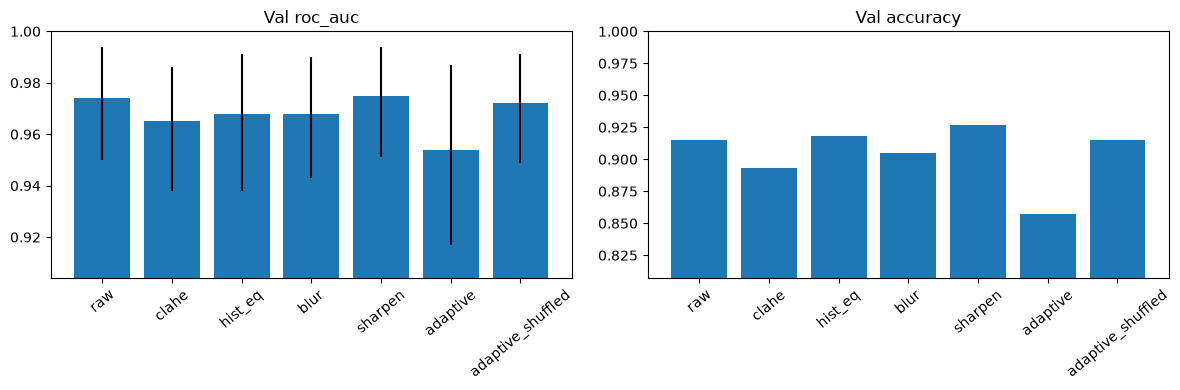

clahe              dAUC vs raw -0.010  95% CI [-0.026, +0.004]
hist_eq            dAUC vs raw -0.007  95% CI [-0.024, +0.008]
blur               dAUC vs raw -0.006  95% CI [-0.021, +0.008]
sharpen            dAUC vs raw +0.001  95% CI [-0.003, +0.005]
adaptive           dAUC vs raw -0.020  95% CI [-0.043, -0.003]
adaptive_shuffled  dAUC vs raw -0.002  95% CI [-0.014, +0.011]


In [ ]:
# %% STEP 05: preprocessing experiments (run after step 04; same recipe, same seed per arm)
import matplotlib.pyplot as plt
REAL = ["raw", "clahe", "hist_eq", "blur", "sharpen", "adaptive"]
ARMS = REAL + ["adaptive_shuffled"]
cache = RES / "preproc"

# control: same method proportions as adaptive, but assigned at random (no labels used)
if not (cache / "adaptive_shuffled.npy").exists():
    ix = pd.read_csv(cache / "index.csv")
    Xs = {m: np.load(cache / f"{m}.npy", mmap_mode="r") for m in REAL[:5]}
    ch = np.random.default_rng(SEED).permutation(ix.adaptive_choice.values)
    out = np.empty(Xs["raw"].shape, np.uint8)
    for i, c in enumerate(ch): out[i] = Xs[c][i]
    np.save(cache / "adaptive_shuffled.npy", out)

results = {}
for a in ARMS:
    f = RES / f"val_mobilenetv2_{a}.json"
    if f.exists():
        results[a] = json.load(open(f))                    # skips arms already finished
    else:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)               # identical seed for every arm
        results[a] = run_arm(a, "mobilenetv2")

tab = pd.DataFrame([{**dict(arm=a), **{k: r[k] for k in ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc"]},
                     "auc_lo": r["ci95"]["roc_auc"][0], "auc_hi": r["ci95"]["roc_auc"][1]}
                    for a, r in results.items()]).round(3)
tab.to_csv(RES / "step05_val_comparison.csv", index=False)
print(tab.to_string(index=False))

# chart
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, col in zip(ax, ["roc_auc", "accuracy"]):
    a_.bar(tab.arm, tab[col]); a_.set_title(f"Val {col}"); a_.set_ylim(max(0, tab[col].min() - .05), 1)
    a_.tick_params(axis="x", rotation=40)
ax[0].errorbar(range(len(tab)), tab.roc_auc, yerr=[tab.roc_auc - tab.auc_lo, tab.auc_hi - tab.roc_auc], fmt="none", c="k")
plt.tight_layout(); plt.savefig(ROOT / "figures" / "step05_comparison.png", dpi=120); plt.show()

# paired group-bootstrap difference vs raw (AUC)
sp = pd.read_csv(ROOT / "split.csv")[["path", "group"]]
vp = lambda a: pd.read_csv(RES / f"valpred_mobilenetv2_{a}.csv").merge(sp, on="path")
b = vp("raw"); ug = b.group.unique(); by = {g: np.where(b.group.values == g)[0] for g in ug}
rng = np.random.default_rng(SEED)
for a in ARMS[1:]:
    o = vp(a); assert (o.path.values == b.path.values).all()
    d = []
    for _ in range(1000):
        ii = np.concatenate([by[g] for g in rng.choice(ug, len(ug))])
        if len(np.unique(b.y.values[ii])) < 2: continue
        d.append(roc_auc_score(o.y.values[ii], o.p_cancer.values[ii]) - roc_auc_score(b.y.values[ii], b.p_cancer.values[ii]))
    print(f"{a:18s} dAUC vs raw {np.mean(d):+.3f}  95% CI [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]")

In [ ]:
# %% STEP 06: EfficientNetB0 with Sharpening Preprocessing

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

MODEL_NAME = "efficientnetb0"
PREPROCESSING = "sharpen"

tf.keras.utils.set_random_seed(SEED)

print("=" * 65)
print("ONCOLENS - STEP 06: EFFICIENTNETB0")
print("=" * 65)

print(f"Model: {MODEL_NAME}")
print(f"Preprocessing: {PREPROCESSING}")
print(f"Random seed: {SEED}")

# --------------------------------------------------
# 2. Verify the existing split
# --------------------------------------------------

split_file = ROOT / "split.csv"

assert split_file.exists(), (
    f"Missing split file: {split_file}"
)

split_df = pd.read_csv(split_file)

required_columns = {"path", "group"}

assert required_columns.issubset(split_df.columns), (
    "split.csv must contain path and group columns."
)

assert split_df["path"].is_unique, (
    "Duplicate image paths detected in split.csv."
)

print("\nDataset split loaded successfully.")
print(f"Total image paths: {len(split_df)}")

if "split" in split_df.columns:
    print("\nSplit distribution:")
    print(split_df["split"].value_counts())

# --------------------------------------------------
# 3. Verify sharpening preprocessing cache
# --------------------------------------------------

cache_dir = RES / "preproc"

required_files = [
    cache_dir / "index.csv",
    cache_dir / "sharpen.npy"
]

for file in required_files:
    assert file.exists(), (
        f"Required preprocessing file not found: {file}"
    )

preproc_index = pd.read_csv(cache_dir / "index.csv")

sharpen_images = np.load(
    cache_dir / "sharpen.npy",
    mmap_mode="r"
)

assert len(preproc_index) == len(sharpen_images), (
    "Preprocessing index and image cache have different lengths."
)

print("\nSharpening preprocessing cache verified.")
print(f"Cached images: {len(sharpen_images)}")
print(f"Image shape: {sharpen_images.shape}")

# --------------------------------------------------
# 4. Train EfficientNetB0
# --------------------------------------------------

# Reuse the same training pipeline and recipe.
# This function must support EfficientNetB0.

result_file = RES / "val_efficientnetb0_sharpen.json"

if result_file.exists():
    print("\nExisting validation results found.")
    print("Loading saved results instead of retraining.")

    with open(result_file, "r", encoding="utf-8") as f:
        efficientnet_results = json.load(f)

else:
    print("\nStarting EfficientNetB0 training...")
    print("Stage 1: Training classification head")
    print("Stage 2: Fine-tuning the backbone")
    print("Evaluation: Validation set only")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    efficientnet_results = run_arm(
        PREPROCESSING,
        MODEL_NAME
    )

    # Preserve the results returned by the training pipeline.
    with open(result_file, "w", encoding="utf-8") as f:
        json.dump(
            efficientnet_results,
            f,
            indent=4,
            default=lambda x: (
                x.tolist() if isinstance(x, np.ndarray)
                else float(x) if isinstance(x, np.generic)
                else str(x)
            )
        )

# --------------------------------------------------
# 5. Display validation metrics
# --------------------------------------------------

metrics = [
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "roc_auc"
]

print("\n" + "=" * 65)
print("EFFICIENTNETB0 - VALIDATION RESULTS")
print("=" * 65)

for metric in metrics:
    if metric in efficientnet_results:
        print(
            f"{metric.upper():15s}: "
            f"{efficientnet_results[metric]:.4f}"
        )

if "ci95" in efficientnet_results:
    if "roc_auc" in efficientnet_results["ci95"]:
        lo, hi = efficientnet_results["ci95"]["roc_auc"]

        print(f"ROC-AUC 95% CI: [{lo:.4f}, {hi:.4f}]")

print("\nValidation results saved to:")
print(result_file)

print("\nStep 06 training/evaluation pipeline finished.")

ONCOLENS - STEP 06: EFFICIENTNETB0
Model: efficientnetb0
Preprocessing: sharpen
Random seed: 42

Dataset split loaded successfully.
Total image paths: 2185

Split distribution:
split
train    1528
test      329
val       328
Name: count, dtype: int64

Sharpening preprocessing cache verified.
Cached images: 2180
Image shape: (2180, 224, 224, 3)

Starting EfficientNetB0 training...
Stage 1: Training classification head
Stage 2: Fine-tuning the backbone
Evaluation: Validation set only
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 9s 1us/step
Epoch 1/25


c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 - 25s - 529ms/step - accuracy: 0.8310 - loss: 0.3723 - val_accuracy: 0.8963 - val_loss: 0.2223
Epoch 2/25
48/48 - 20s - 423ms/step - accuracy: 0.9194 - loss: 0.2125 - val_accuracy: 0.9177 - val_loss: 0.2232
Epoch 3/25
48/48 - 20s - 422ms/step - accuracy: 0.9384 - loss: 0.1652 - val_accuracy: 0.9238 - val_loss: 0.1826
Epoch 4/25
48/48 - 20s - 424ms/step - accuracy: 0.9515 - loss: 0.1247 - val_accuracy: 0.9238 - val_loss: 0.1874
Epoch 5/25
48/48 - 20s - 426ms/step - accuracy: 0.9607 - loss: 0.1173 - val_accuracy: 0.9329 - val_loss: 0.2063
Epoch 6/25
48/48 - 21s - 430ms/step - accuracy: 0.9633 - loss: 0.0992 - val_accuracy: 0.9360 - val_loss: 0.1725
Epoch 7/25
48/48 - 21s - 432ms/step - accuracy: 0.9738 - loss: 0.0722 - val_accuracy: 0.9543 - val_loss: 0.1816
Epoch 8/25
48/48 - 21s - 434ms/step - accuracy: 0.9666 - loss: 0.0785 - val_accuracy: 0.9299 - val_loss: 0.2045
Epoch 9/25
48/48 - 21s - 436ms/step - accuracy: 0.9777 - loss: 0.0673 - val_accuracy: 0.9360 - val_loss: 0.2040
Epo


VALIDATION COMPARISON
     Metric  MobileNetV2  EfficientNetB0  Difference
   accuracy       0.9268          0.9665      0.0396
  precision       0.9425          0.9665      0.0240
     recall       0.9213          0.9719      0.0506
specificity       0.9333          0.9600      0.0267
         f1       0.9318          0.9692      0.0374
    roc_auc       0.9751          0.9840      0.0089

Comparison saved to: C:\Users\Bhavana BV\Downloads\OncoLens\results\step06_model_comparison.csv


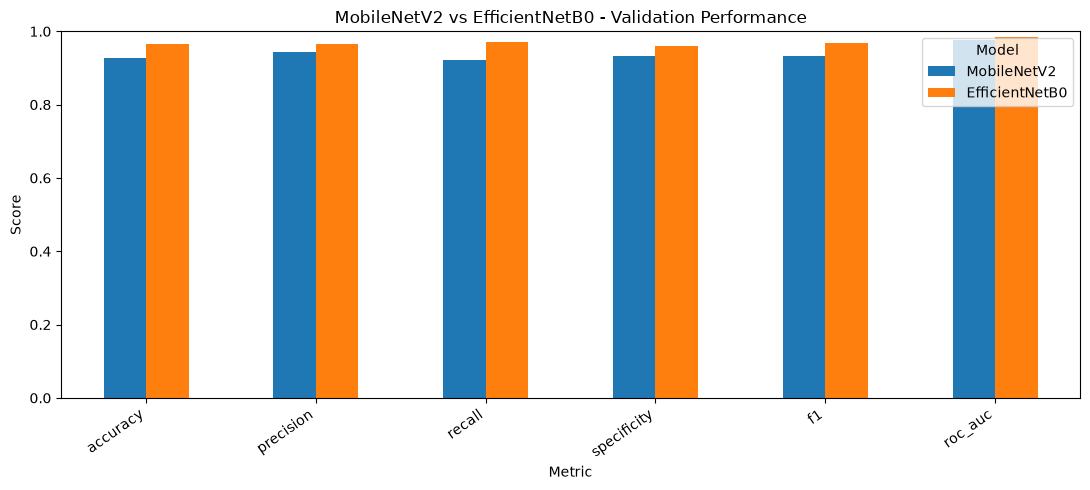

Comparison chart saved to: C:\Users\Bhavana BV\Downloads\OncoLens\figures\step06_model_comparison.png


In [ ]:
# %% STEP 06: MobileNetV2 vs EfficientNetB0

import json
import pandas as pd
import matplotlib.pyplot as plt

mobile_file = RES / "val_mobilenetv2_sharpen.json"
efficient_file = RES / "val_efficientnetb0_sharpen.json"

assert mobile_file.exists(), (
    "MobileNetV2 sharpening validation results are missing."
)

assert efficient_file.exists(), (
    "EfficientNetB0 sharpening validation results are missing."
)

with open(mobile_file, "r", encoding="utf-8") as f:
    mobile_results = json.load(f)

with open(efficient_file, "r", encoding="utf-8") as f:
    efficient_results = json.load(f)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "roc_auc"
]

comparison = pd.DataFrame({
    "Metric": metrics,
    "MobileNetV2": [
        mobile_results[m] for m in metrics
    ],
    "EfficientNetB0": [
        efficient_results[m] for m in metrics
    ]
})

comparison["Difference"] = (
    comparison["EfficientNetB0"]
    - comparison["MobileNetV2"]
)

print("\nVALIDATION COMPARISON")
print("=" * 75)
print(comparison.round(4).to_string(index=False))

comparison_file = RES / "step06_model_comparison.csv"

comparison.to_csv(
    comparison_file,
    index=False
)

print(f"\nComparison saved to: {comparison_file}")

# Plot comparison

ax = comparison.set_index("Metric")[
    ["MobileNetV2", "EfficientNetB0"]
].plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title(
    "MobileNetV2 vs EfficientNetB0 - Validation Performance"
)

ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xlabel("Metric")
ax.legend(title="Model")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

figure_file = ROOT / "figures" / "step06_model_comparison.png"

figure_file.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    figure_file,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(f"Comparison chart saved to: {figure_file}")

In [ ]:
# %% STEP 06: FINAL DATA AND MODEL CHECK

import pandas as pd
import numpy as np
from pathlib import Path

split_file = ROOT / "split.csv"
cache_dir = RES / "preproc"
index_file = cache_dir / "index.csv"

split_df = pd.read_csv(split_file)
index_df = pd.read_csv(index_file)

print("=" * 60)
print("ONCOLENS: STEP 06 VERIFICATION")
print("=" * 60)

print("\n1. SPLIT SUMMARY")
print(split_df["split"].value_counts())

print("\nTotal split rows:", len(split_df))
print("Unique split paths:", split_df["path"].nunique())

print("\n2. PREPROCESSING CACHE")

print("Cache index rows:", len(index_df))
print("Unique cache paths:", index_df["path"].nunique())

sharpen_file = cache_dir / "sharpen.npy"
sharpen = np.load(sharpen_file, mmap_mode="r")

print("Sharpening image count:", len(sharpen))
print("Sharpening image shape:", sharpen.shape)

print("\n3. MISSING IMAGE PATHS")

split_paths = set(split_df["path"].astype(str))
cache_paths = set(index_df["path"].astype(str))

missing = split_paths - cache_paths
extra = cache_paths - split_paths

print("Paths missing from cache:", len(missing))
print("Extra cache paths:", len(extra))

if missing:
    print("\nFirst missing paths:")
    for p in sorted(missing)[:10]:
        print(p)

print("\n4. SAVED MODEL FILES")

for folder in [
    ROOT / "checkpoints",
    RES
]:
    print(f"\n{folder}")

    if folder.exists():
        files = [
            p for p in folder.rglob("*")
            if p.is_file()
            and p.suffix.lower() in {
                ".keras", ".h5", ".weights", ".index"
            }
        ]

        if files:
            for p in files:
                print(" ", p)
        else:
            print("  No matching model files found.")
    else:
        print("  Folder does not exist.")

print("\nVerification finished.")

ONCOLENS: STEP 06 VERIFICATION

1. SPLIT SUMMARY
split
train    1528
test      329
val       328
Name: count, dtype: int64

Total split rows: 2185
Unique split paths: 2185

2. PREPROCESSING CACHE
Cache index rows: 2180
Unique cache paths: 2180
Sharpening image count: 2180
Sharpening image shape: (2180, 224, 224, 3)

3. MISSING IMAGE PATHS
Paths missing from cache: 5
Extra cache paths: 0

First missing paths:
cancer/D1_Cancer_0040.jpeg
cancer/D2_Cancer_0041.jpeg
cancer/D2_Cancer_0533.png
cancer/D2_Cancer_0598.jpg
non_cancer/D2_NonCancer_0138.png

4. SAVED MODEL FILES

C:\Users\Bhavana BV\Downloads\OncoLens\checkpoints
  C:\Users\Bhavana BV\Downloads\OncoLens\checkpoints\efficientnetb0_sharpen.keras
  C:\Users\Bhavana BV\Downloads\OncoLens\checkpoints\mobilenetv2_adaptive.keras
  C:\Users\Bhavana BV\Downloads\OncoLens\checkpoints\mobilenetv2_adaptive_shuffled.keras
  C:\Users\Bhavana BV\Downloads\OncoLens\checkpoints\mobilenetv2_blur.keras
  C:\Users\Bhavana BV\Downloads\OncoLens\checkpo

Development images: 1855
Development groups: 930

Original development split:
split
train    1527
val       328
Name: count, dtype: int64

========== FIVE-FOLD SUMMARY ==========
Fold 1: images=371, groups=186, cancer=201, non_cancer=170
Fold 2: images=371, groups=185, cancer=201, non_cancer=170
Fold 3: images=371, groups=187, cancer=201, non_cancer=170
Fold 4: images=371, groups=186, cancer=201, non_cancer=170
Fold 5: images=371, groups=186, cancer=201, non_cancer=170

Fold assignments saved to:
C:\Users\Bhavana BV\Downloads\OncoLens\results\cv5_group_fold_assignments.csv

SUCCESS: Fold assignments generated.
Original split.csv was not modified.
Test images were not included.


In [ ]:
# ============================================================
# REPAIR ONCOLENS BACKBONES CONFIGURATION
# ============================================================

import tensorflow as tf

# Restore the model configuration expected by build().
BACKBONES = {
    "mobilenetv2": (
        tf.keras.applications.MobileNetV2,
        (1.0 / 127.5, -1.0)
    ),
    "efficientnetb0": (
        tf.keras.applications.EfficientNetB0,
        (1.0, 0.0)
    )
}

print("BACKBONES restored successfully.")

for name, (constructor, (scale, offset)) in BACKBONES.items():
    print(
        f"{name}: "
        f"constructor={constructor.__name__}, "
        f"scale={scale}, "
        f"offset={offset}"
    )

# Verify that build() can construct both architectures.
for name in BACKBONES:
    model, base = build(name)
    print(
        f"{name}: model created successfully; "
        f"output shape={model.output_shape}"
    )
    del model, base
    tf.keras.backend.clear_session()

print("\nRepair verification passed.")

BACKBONES restored successfully.
mobilenetv2: constructor=MobileNetV2, scale=0.00784313725490196, offset=-1.0
efficientnetb0: constructor=EfficientNetB0, scale=1.0, offset=0.0
mobilenetv2: model created successfully; output shape=(None, 2)
efficientnetb0: model created successfully; output shape=(None, 2)

Repair verification passed.


In [ ]:
# ================================================================
# ONCOLENS — STEP 07
# CORRECTED, RESUMABLE, GROUP-AWARE 5-FOLD CROSS-VALIDATION
#
# Models:
#   1. MobileNetV2
#   2. EfficientNetB0
#
# Preprocessing:
#   sharpen.npy
#
# IMPORTANT:
#   - Uses development data only: train + val
#   - Never loads test images into CV training/validation
#   - Uses a NEW output folder to avoid reusing old fold results
#   - Does not modify split.csv or existing final models
# ================================================================

import os
import gc
import json
import random
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    log_loss,
)

warnings.filterwarnings("ignore", category=FutureWarning)

# ================================================================
# 1. CONFIGURATION
# ================================================================

N_SPLITS = 5

CV_BACKBONES = [
    "mobilenetv2",
    "efficientnetb0",
]

PREPROCESSING_METHOD = "sharpen"

# A NEW directory is essential because earlier fold results may
# have used incorrect fold numbering.
OUT_DIR = RES / "cv5_results_corrected"

CHECKPOINT_DIR = OUT_DIR / "checkpoints"
PREDICTION_DIR = OUT_DIR / "fold_predictions"
METRIC_DIR = OUT_DIR / "fold_metrics"
LOG_DIR = OUT_DIR / "logs"

for folder in [
    OUT_DIR,
    CHECKPOINT_DIR,
    PREDICTION_DIR,
    METRIC_DIR,
    LOG_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

# Set True to save each trained fold model.
SAVE_FOLD_MODELS = True

# Resume only when prediction, metrics, and the model checkpoint
# are all present and valid.
RESUME_COMPLETED_FOLDS = True

# Keep memory usage modest.
PREFETCH_BUFFER = 1

IMAGE_SHAPE = (224, 224, 3)

# Training configuration
HEAD_EPOCHS = 25
FINE_TUNE_EPOCHS = 30

HEAD_PATIENCE = 5
FINE_TUNE_PATIENCE = 5

HEAD_LR = 1e-3
FINE_TUNE_LR = 1e-5

FINE_TUNE_LAST_LAYERS = 30

# ================================================================
# 2. VALIDATE EXISTING NOTEBOOK OBJECTS
# ================================================================

required_objects = [
    "ROOT",
    "RES",
    "SEED",
    "BATCH",
    "BACKBONES",
    "build",
    "compile_",
    "metrics_at",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Required notebook objects are missing: "
        + ", ".join(missing_objects)
        + ". Run the earlier setup/model-definition cells first."
    )

if not isinstance(BACKBONES, dict):
    raise TypeError(
        "BACKBONES must be a dictionary, not a list. "
        "Restore the original BACKBONES dictionary before running CV."
    )

for backbone_name in CV_BACKBONES:
    if backbone_name not in BACKBONES:
        raise KeyError(
            f"{backbone_name} is missing from BACKBONES."
        )

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 72)
print("ONCOLENS — OPTIMIZED STEP 07")
print("CORRECTED GROUP-AWARE 5-FOLD CROSS-VALIDATION")
print("=" * 72)

print("Output directory:", OUT_DIR)
print("Preprocessing:", PREPROCESSING_METHOD)
print("TensorFlow:", tf.__version__)

# ================================================================
# 3. LOAD AND VALIDATE THE DATA MANIFEST
# ================================================================

manifest_path = ROOT / "split.csv"

if not manifest_path.exists():
    raise FileNotFoundError(
        f"Manifest not found: {manifest_path}"
    )

manifest = pd.read_csv(manifest_path)

required_manifest_columns = {
    "path",
    "split",
    "group",
    "label_id",
    "use",
}

missing_columns = required_manifest_columns - set(manifest.columns)

if missing_columns:
    raise ValueError(
        f"split.csv is missing columns: {sorted(missing_columns)}"
    )

# Interpret use safely, including CSV boolean/string representations.
if manifest["use"].dtype == object:
    use_mask = (
        manifest["use"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes"])
    )
else:
    use_mask = manifest["use"].fillna(False).astype(bool)

manifest = manifest.copy()
manifest["_use"] = use_mask

# Development set only. TEST IS EXCLUDED.
dev_manifest = manifest[
    manifest["_use"]
    & manifest["split"].astype(str).str.lower().isin(["train", "val"])
].copy()

if dev_manifest.empty:
    raise ValueError("No eligible development images were found.")

# Normalize paths so joins are consistent across Windows separators.
def normalize_path(value):
    return str(value).replace("\\", "/").strip().lower()

dev_manifest["_path_key"] = dev_manifest["path"].map(normalize_path)

if dev_manifest["_path_key"].duplicated().any():
    duplicate_paths = dev_manifest.loc[
        dev_manifest["_path_key"].duplicated(keep=False),
        "path"
    ].tolist()

    raise ValueError(
        "Duplicate paths found in the development manifest. "
        f"Examples: {duplicate_paths[:5]}"
    )

dev_manifest["label_id"] = pd.to_numeric(
    dev_manifest["label_id"],
    errors="raise"
).astype(int)

if not set(dev_manifest["label_id"].unique()).issubset({0, 1}):
    raise ValueError("Expected binary labels encoded as 0 and 1.")

if dev_manifest["group"].isna().any():
    raise ValueError(
        "Missing group IDs detected. Group-aware CV cannot proceed safely."
    )

print("\nDevelopment images:", len(dev_manifest))
print("Development groups:", dev_manifest["group"].nunique())
print("\nDevelopment labels:")
print(dev_manifest["label_id"].value_counts().sort_index())

print("\nDevelopment original split:")
print(dev_manifest["split"].value_counts())

# ================================================================
# 4. LOAD FOLD ASSIGNMENTS AND NORMALIZE FOLD IDS
# ================================================================

fold_assignment_path = RES / "cv5_group_fold_assignments.csv"

if not fold_assignment_path.exists():
    raise FileNotFoundError(
        f"Fold assignment file not found: {fold_assignment_path}"
    )

fold_assignments = pd.read_csv(fold_assignment_path)

if "path" not in fold_assignments.columns or "fold" not in fold_assignments.columns:
    raise ValueError(
        "Fold assignment CSV must contain 'path' and 'fold' columns."
    )

fold_assignments = fold_assignments.copy()
fold_assignments["_path_key"] = fold_assignments["path"].map(normalize_path)

if fold_assignments["_path_key"].duplicated().any():
    raise ValueError(
        "Duplicate image paths found in the fold assignment file."
    )

fold_assignments["fold"] = pd.to_numeric(
    fold_assignments["fold"],
    errors="raise"
).astype(int)

observed_fold_ids = sorted(fold_assignments["fold"].unique().tolist())

if observed_fold_ids == [0, 1, 2, 3, 4]:
    fold_assignments["fold_internal"] = fold_assignments["fold"]

elif observed_fold_ids == [1, 2, 3, 4, 5]:
    fold_assignments["fold_internal"] = fold_assignments["fold"] - 1

else:
    raise ValueError(
        "Unexpected fold IDs. Expected 0–4 or 1–5, but found: "
        f"{observed_fold_ids}"
    )

# Join assignments to eligible development rows only.
fold_table = dev_manifest.merge(
    fold_assignments[["_path_key", "fold_internal"]],
    on="_path_key",
    how="left",
    validate="one_to_one",
)

if fold_table["fold_internal"].isna().any():
    missing = fold_table.loc[
        fold_table["fold_internal"].isna(),
        "path"
    ].tolist()

    raise ValueError(
        "Some development images have no fold assignment. "
        f"Examples: {missing[:10]}"
    )

fold_table["fold_internal"] = fold_table["fold_internal"].astype(int)

# Check that the assignment file does not include extra development paths
# missing from the manifest. Extra test rows are not allowed either.
dev_path_keys = set(dev_manifest["_path_key"])
assigned_path_keys = set(fold_assignments["_path_key"])

missing_assignments = dev_path_keys - assigned_path_keys
extra_assignments = assigned_path_keys - dev_path_keys

if missing_assignments:
    raise ValueError(
        f"{len(missing_assignments)} development images lack assignments."
    )

if extra_assignments:
    raise ValueError(
        f"The fold assignment file contains {len(extra_assignments)} "
        "paths not belonging to the eligible development set. "
        "Regenerate the development-only fold assignment file."
    )

# Check that one group never spans multiple folds.
group_fold_counts = (
    fold_table.groupby("group")["fold_internal"]
    .nunique()
)

if (group_fold_counts > 1).any():
    bad_groups = group_fold_counts[group_fold_counts > 1].index.tolist()

    raise ValueError(
        "Group leakage detected: some groups appear in multiple folds. "
        f"Examples: {bad_groups[:10]}"
    )

# Validate exactly five nonempty folds.
expected_folds = list(range(N_SPLITS))
actual_folds = sorted(fold_table["fold_internal"].unique().tolist())

if actual_folds != expected_folds:
    raise ValueError(
        f"Expected folds {expected_folds}, found {actual_folds}."
    )

fold_sizes = fold_table["fold_internal"].value_counts().sort_index()

if len(fold_sizes) != N_SPLITS or (fold_sizes == 0).any():
    raise ValueError(
        f"At least one fold is empty. Fold sizes: {fold_sizes.to_dict()}"
    )

# Verify each image is assigned to exactly one validation fold.
assert len(fold_table) == len(dev_manifest)
assert fold_table["_path_key"].nunique() == len(dev_manifest)

print("\nFold sizes:")
print(fold_sizes.to_dict())

print("\nFold label distribution:")
print(
    pd.crosstab(
        fold_table["fold_internal"],
        fold_table["label_id"]
    )
)

print("\nGroup leakage check: PASSED")
print("Development assignment check: PASSED")
print("Test set excluded: PASSED")

# Save the normalized fold assignments used by this run.
fold_table[
    ["path", "label_id", "group", "split", "fold_internal"]
].rename(
    columns={
        "label_id": "y",
        "fold_internal": "fold"
    }
).to_csv(
    OUT_DIR / "validated_fold_assignments.csv",
    index=False
)

# ================================================================
# 5. LOAD EXISTING PREPROCESSING CACHE
# ================================================================

cache_dir = RES / "preproc"

cache_path = cache_dir / f"{PREPROCESSING_METHOD}.npy"
cache_index_path = cache_dir / "index.csv"

if not cache_path.exists():
    raise FileNotFoundError(
        f"Preprocessing cache not found: {cache_path}"
    )

if not cache_index_path.exists():
    raise FileNotFoundError(
        f"Cache index not found: {cache_index_path}"
    )

cache_index = pd.read_csv(cache_index_path)

if "path" not in cache_index.columns:
    raise ValueError("Cache index must contain a 'path' column.")

cache_index = cache_index.copy()
cache_index["_path_key"] = cache_index["path"].map(normalize_path)

if cache_index["_path_key"].duplicated().any():
    raise ValueError("Duplicate paths found in the cache index.")

# Map each development image to its row in the existing array.
cache_position = {
    path_key: i
    for i, path_key in enumerate(cache_index["_path_key"])
}

missing_cache_paths = [
    path
    for path in dev_manifest["_path_key"]
    if path not in cache_position
]

if missing_cache_paths:
    raise ValueError(
        f"{len(missing_cache_paths)} development images are absent "
        f"from the preprocessing cache. Examples: {missing_cache_paths[:5]}"
    )

cache = np.load(cache_path, mmap_mode="r")

if cache.ndim != 4 or tuple(cache.shape[1:]) != IMAGE_SHAPE:
    raise ValueError(
        f"Unexpected cache shape: {cache.shape}; "
        f"expected (N, 224, 224, 3)."
    )

if len(cache_index) != len(cache):
    raise ValueError(
        "Cache index row count does not match the preprocessing array."
    )

# Reorder by manifest path, never by assumptions about cache row order.
cache_rows = np.array(
    [
        cache_position[path_key]
        for path_key in dev_manifest["_path_key"]
    ],
    dtype=np.int64,
)

# Only development images are copied into RAM.
X_dev = np.asarray(cache[cache_rows], dtype=np.uint8).copy()

y_dev = dev_manifest["label_id"].to_numpy(dtype=np.int32)

fold_ids = fold_table["fold_internal"].to_numpy(dtype=np.int32)

group_ids = dev_manifest["group"].to_numpy()

if len(X_dev) != len(y_dev) or len(y_dev) != len(fold_ids):
    raise ValueError("Image, label, and fold arrays have mismatched lengths.")

if not np.isfinite(X_dev).all():
    raise ValueError("Non-finite values found in the image cache.")

print("\nInput shape:", X_dev.shape)
print("Input dtype:", X_dev.dtype)
print("Labels shape:", y_dev.shape)
print("Fold IDs:", np.unique(fold_ids).tolist())

# ================================================================
# 6. HELPER FUNCTIONS
# ================================================================

def make_tf_dataset(X, y=None, training=False):
    """
    Create a memory-efficient tf.data pipeline.
    Training images are shuffled; validation images are not.
    """
    if y is None:
        ds = tf.data.Dataset.from_tensor_slices(X)
    else:
        ds = tf.data.Dataset.from_tensor_slices((X, y))

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(X), 1024),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    ds = ds.batch(BATCH)

    options = tf.data.Options()
    options.experimental_deterministic = True
    ds = ds.with_options(options)

    ds = ds.prefetch(PREFETCH_BUFFER)

    return ds


def safe_json_value(value):
    """Convert NumPy values and non-finite floats to JSON-safe values."""
    if isinstance(value, dict):
        return {
            str(k): safe_json_value(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [safe_json_value(v) for v in value]

    if isinstance(value, (np.integer,)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        value = float(value)
        return value if np.isfinite(value) else None

    if isinstance(value, np.ndarray):
        return safe_json_value(value.tolist())

    if isinstance(value, (np.bool_, bool)):
        return bool(value)

    return value


def compute_cv_metrics(y_true, probabilities):
    """
    Compute binary classification metrics.
    Positive class is label 1.
    """
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities)

    if probabilities.ndim == 2:
        if probabilities.shape[1] == 2:
            positive_prob = probabilities[:, 1]
        elif probabilities.shape[1] == 1:
            positive_prob = probabilities[:, 0]
        else:
            raise ValueError(
                f"Unexpected prediction shape: {probabilities.shape}"
            )
    else:
        positive_prob = probabilities.reshape(-1)

    if len(y_true) != len(positive_prob):
        raise ValueError("Prediction and label lengths differ.")

    predictions = (positive_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1],
    ).ravel()

    specificity = (
        float(tn / (tn + fp))
        if (tn + fp) > 0
        else float("nan")
    )

    try:
        auc = float(roc_auc_score(y_true, positive_prob))
    except ValueError:
        auc = float("nan")

    return {
        "n": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, predictions)),
        "precision": float(
            precision_score(y_true, predictions, zero_division=0)
        ),
        "recall": float(
            recall_score(y_true, predictions, zero_division=0)
        ),
        "specificity": specificity,
        "f1": float(
            f1_score(y_true, predictions, zero_division=0)
        ),
        "auc": auc,
        "log_loss": float(
            log_loss(
                y_true,
                np.clip(positive_prob, 1e-7, 1 - 1e-7),
                labels=[0, 1],
            )
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "threshold": 0.5,
    }


def model_output_path(backbone, fold_number):
    return CHECKPOINT_DIR / (
        f"{backbone}_fold{fold_number}.keras"
    )


def prediction_output_path(backbone, fold_number):
    return PREDICTION_DIR / (
        f"{backbone}_fold{fold_number}.csv"
    )


def metric_output_path(backbone, fold_number):
    return METRIC_DIR / (
        f"{backbone}_fold{fold_number}.json"
    )


def completed_fold_exists(backbone, fold_number):
    """
    Resume only when all expected artifacts exist and can be read.
    """
    pred_path = prediction_output_path(backbone, fold_number)
    metric_path = metric_output_path(backbone, fold_number)
    model_path = model_output_path(backbone, fold_number)

    if not pred_path.exists() or not metric_path.exists():
        return False

    if SAVE_FOLD_MODELS and not model_path.exists():
        return False

    try:
        pred_df = pd.read_csv(pred_path)
        with open(metric_path, "r", encoding="utf-8") as f:
            metrics = json.load(f)

        required_pred_cols = {
            "path",
            "y_true",
            "probability_cancer",
            "y_pred",
            "fold",
            "backbone",
        }

        if not required_pred_cols.issubset(pred_df.columns):
            return False

        expected_count = int((fold_ids == fold_number).sum())

        if len(pred_df) != expected_count:
            return False

        if not isinstance(metrics, dict):
            return False

        if metrics.get("fold") != fold_number:
            return False

        if metrics.get("backbone") != backbone:
            return False

        return True

    except Exception:
        return False


# ================================================================
# 7. RUN FIVE-FOLD CROSS-VALIDATION
# ================================================================

all_fold_metrics = []

for backbone in CV_BACKBONES:

    print("\n" + "=" * 72)
    print("BACKBONE:", backbone.upper())
    print("=" * 72)

    for fold_number in range(N_SPLITS):

        print("\n" + "-" * 68)
        print(f"{backbone.upper()} — FOLD {fold_number + 1}/{N_SPLITS}")
        print("-" * 68)

        train_mask = fold_ids != fold_number
        val_mask = fold_ids == fold_number

        train_indices = np.flatnonzero(train_mask)
        val_indices = np.flatnonzero(val_mask)

        if len(train_indices) == 0 or len(val_indices) == 0:
            raise ValueError(
                f"Empty train/validation split for fold {fold_number}. "
                f"Training={len(train_indices)}, validation={len(val_indices)}"
            )

        # Group-level leakage verification.
        train_groups = set(group_ids[train_indices])
        val_groups = set(group_ids[val_indices])

        overlap = train_groups.intersection(val_groups)

        if overlap:
            raise RuntimeError(
                f"Group leakage in fold {fold_number}: "
                f"{len(overlap)} groups overlap."
            )

        y_train = y_dev[train_indices]
        y_val = y_dev[val_indices]

        print("Training images:", len(train_indices))
        print("Validation images:", len(val_indices))
        print("Training groups:", len(train_groups))
        print("Validation groups:", len(val_groups))
        print("Training label counts:", np.bincount(y_train, minlength=2))
        print("Validation label counts:", np.bincount(y_val, minlength=2))

        # --------------------------------------------------------
        # RESUME VALID COMPLETED FOLDS ONLY
        # --------------------------------------------------------

        if (
            RESUME_COMPLETED_FOLDS
            and completed_fold_exists(backbone, fold_number)
        ):
            print(
                f"Skipping verified completed fold "
                f"{fold_number + 1}."
            )

            with open(
                metric_output_path(backbone, fold_number),
                "r",
                encoding="utf-8",
            ) as f:
                saved_metrics = json.load(f)

            all_fold_metrics.append(saved_metrics)
            continue

        print("Training this fold from scratch.")

        # --------------------------------------------------------
        # RESET RANDOM STATE FOR REPRODUCIBILITY
        # --------------------------------------------------------

        fold_seed = int(SEED) + (fold_number * 100) + (
            0 if backbone == "mobilenetv2" else 10000
        )

        random.seed(fold_seed)
        np.random.seed(fold_seed)
        tf.random.set_seed(fold_seed)

        tf.keras.backend.clear_session()
        gc.collect()

        # --------------------------------------------------------
        # BUILD MODEL
        # --------------------------------------------------------

        model, base_model = build(backbone)

        # Stage 1: train classification head.
        compile_(model, HEAD_LR)

        train_ds = make_tf_dataset(
            X_dev[train_indices],
            y_train,
            training=True,
        )

        val_ds = make_tf_dataset(
            X_dev[val_indices],
            y_val,
            training=False,
        )

        fold_log_path = LOG_DIR / (
            f"{backbone}_fold{fold_number}_training.csv"
        )

        callbacks_stage1 = [
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=HEAD_PATIENCE,
                restore_best_weights=True,
                verbose=1,
            ),
            tf.keras.callbacks.CSVLogger(
                str(fold_log_path),
                append=False,
            ),
        ]

        print("\nStage 1: frozen backbone / classification head")

        history1 = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=HEAD_EPOCHS,
            callbacks=callbacks_stage1,
            verbose=1,
        )

        # --------------------------------------------------------
        # STAGE 2: FINE-TUNE LAST BACKBONE LAYERS
        # --------------------------------------------------------

        print("\nStage 2: fine-tuning")

        base_model.trainable = True

        # Freeze all but the final selected layers.
        fine_tune_start = max(
            0,
            len(base_model.layers) - FINE_TUNE_LAST_LAYERS,
        )

        for layer in base_model.layers[:fine_tune_start]:
            layer.trainable = False

        # BatchNormalization layers remain frozen to reduce
        # instability with relatively small fold sizes.
        for layer in base_model.layers:
            if isinstance(
                layer,
                tf.keras.layers.BatchNormalization
            ):
                layer.trainable = False

        compile_(model, FINE_TUNE_LR)

        callbacks_stage2 = [
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=FINE_TUNE_PATIENCE,
                restore_best_weights=True,
                verbose=1,
            ),
            tf.keras.callbacks.CSVLogger(
                str(fold_log_path),
                append=True,
            ),
        ]

        history2 = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=FINE_TUNE_EPOCHS,
            callbacks=callbacks_stage2,
            verbose=1,
        )

        # --------------------------------------------------------
        # VALIDATION PREDICTIONS
        # --------------------------------------------------------

        print("\nGenerating validation predictions...")

        val_probabilities = model.predict(
            val_ds,
            verbose=0,
        )

        if val_probabilities.ndim != 2 or val_probabilities.shape[1] != 2:
            raise ValueError(
                f"Expected two-class softmax output; got "
                f"{val_probabilities.shape}"
            )

        positive_probabilities = val_probabilities[:, 1]
        predicted_labels = (
            positive_probabilities >= 0.5
        ).astype(int)

        metrics = compute_cv_metrics(
            y_val,
            positive_probabilities,
        )

        metrics["backbone"] = backbone
        metrics["fold"] = int(fold_number)
        metrics["fold_display"] = int(fold_number + 1)
        metrics["preprocessing"] = PREPROCESSING_METHOD
        metrics["training_images"] = int(len(train_indices))
        metrics["validation_images"] = int(len(val_indices))
        metrics["training_groups"] = int(len(train_groups))
        metrics["validation_groups"] = int(len(val_groups))
        metrics["fold_seed"] = int(fold_seed)
        metrics["head_epochs_run"] = int(len(history1.history["loss"]))
        metrics["fine_tune_epochs_run"] = int(len(history2.history["loss"]))

        print("\nFold metrics:")
        for key in [
            "accuracy",
            "precision",
            "recall",
            "specificity",
            "f1",
            "auc",
            "log_loss",
        ]:
            print(f"{key:>12}: {metrics[key]:.4f}")

        # --------------------------------------------------------
        # SAVE FOLD ARTIFACTS
        # --------------------------------------------------------

        prediction_df = pd.DataFrame({
            "path": dev_manifest.iloc[val_indices]["path"].to_numpy(),
            "y_true": y_val,
            "probability_cancer": positive_probabilities,
            "y_pred": predicted_labels,
            "fold": fold_number,
            "backbone": backbone,
            "preprocessing": PREPROCESSING_METHOD,
        })

        pred_path = prediction_output_path(
            backbone,
            fold_number,
        )

        metric_path = metric_output_path(
            backbone,
            fold_number,
        )

        # Save the model before writing the metric/prediction pair.
        # This makes a completed fold easier to resume safely.
        if SAVE_FOLD_MODELS:
            model_path = model_output_path(
                backbone,
                fold_number,
            )

            print("\nSaving fold model:", model_path)
            model.save(model_path)

        # Save each output to a temporary file and then replace it.
        pred_tmp = pred_path.with_suffix(".tmp.csv")
        prediction_df.to_csv(pred_tmp, index=False)
        os.replace(pred_tmp, pred_path)

        metric_tmp = metric_path.with_suffix(".tmp.json")

        with open(metric_tmp, "w", encoding="utf-8") as f:
            json.dump(
                safe_json_value(metrics),
                f,
                indent=2,
            )

        os.replace(metric_tmp, metric_path)

        all_fold_metrics.append(metrics)

        print("\nSaved predictions:", pred_path)
        print("Saved metrics:", metric_path)
        print(f"Completed {backbone} fold {fold_number + 1}.")

        # Release fold-specific resources.
        del model, base_model
        del train_ds, val_ds
        del history1, history2
        del val_probabilities, positive_probabilities
        del predicted_labels, prediction_df

        tf.keras.backend.clear_session()
        gc.collect()

# ================================================================
# 8. COMBINE FOLD METRICS
# ================================================================

print("\n" + "=" * 72)
print("BUILDING FINAL CROSS-VALIDATION TABLES")
print("=" * 72)

# Reload metrics from disk so the output remains complete after resume.
metric_records = []

for backbone in CV_BACKBONES:
    for fold_number in range(N_SPLITS):

        metric_path = metric_output_path(
            backbone,
            fold_number,
        )

        if not metric_path.exists():
            raise FileNotFoundError(
                f"Missing fold metrics: {metric_path}"
            )

        with open(metric_path, "r", encoding="utf-8") as f:
            metric_record = json.load(f)

        metric_records.append(metric_record)

fold_metrics_df = pd.DataFrame(metric_records)

# Ensure every backbone has exactly five completed folds.
fold_counts = fold_metrics_df.groupby("backbone")["fold"].nunique()

for backbone in CV_BACKBONES:
    if fold_counts.get(backbone, 0) != N_SPLITS:
        raise RuntimeError(
            f"{backbone} does not have five completed folds."
        )

fold_metrics_path = OUT_DIR / "cv5_fold_metrics.csv"

fold_metrics_df.to_csv(
    fold_metrics_path,
    index=False,
)

print("\nSaved fold metrics:", fold_metrics_path)

# ================================================================
# 9. COMBINE OUT-OF-FOLD PREDICTIONS
# ================================================================

prediction_frames = []

for backbone in CV_BACKBONES:
    for fold_number in range(N_SPLITS):

        pred_path = prediction_output_path(
            backbone,
            fold_number,
        )

        if not pred_path.exists():
            raise FileNotFoundError(
                f"Missing fold predictions: {pred_path}"
            )

        frame = pd.read_csv(pred_path)

        # Validate fold membership against the canonical assignment.
        expected_paths = set(
            fold_table.loc[
                fold_table["fold_internal"] == fold_number,
                "_path_key",
            ]
        )

        observed_paths = set(
            frame["path"].map(normalize_path)
        )

        if expected_paths != observed_paths:
            raise RuntimeError(
                f"Saved predictions do not match the expected "
                f"validation images for {backbone}, fold {fold_number}."
            )

        if frame["fold"].nunique() != 1:
            raise RuntimeError("Inconsistent fold labels in predictions.")

        if int(frame["fold"].iloc[0]) != fold_number:
            raise RuntimeError(
                f"Incorrect fold label in {pred_path}."
            )

        prediction_frames.append(frame)

oof_df = pd.concat(
    prediction_frames,
    ignore_index=True,
)

oof_path = OUT_DIR / "cv5_oof_predictions.csv"

oof_df.to_csv(
    oof_path,
    index=False,
)

print("Saved OOF predictions:", oof_path)

# Verify every development image appears once per backbone.
for backbone in CV_BACKBONES:

    model_oof = oof_df[
        oof_df["backbone"] == backbone
    ].copy()

    counts = model_oof["path"].map(normalize_path).value_counts()

    if len(model_oof) != len(dev_manifest):
        raise RuntimeError(
            f"{backbone}: expected {len(dev_manifest)} OOF predictions, "
            f"found {len(model_oof)}."
        )

    if not (counts == 1).all():
        raise RuntimeError(
            f"{backbone}: some development images appear more than once "
            "or are missing from the OOF predictions."
        )

    # Ensure the OOF labels agree with the manifest.
    expected_label_map = dict(
        zip(dev_manifest["_path_key"], y_dev)
    )

    for _, row in model_oof.iterrows():
        key = normalize_path(row["path"])

        if int(row["y_true"]) != int(expected_label_map[key]):
            raise RuntimeError(
                f"Label mismatch found in OOF predictions: {row['path']}"
            )

print("\nOOF validation checks: PASSED")
print("Each development image is predicted exactly once per backbone.")

# ================================================================
# 10. SUMMARIZE FOLD MEANS AND STANDARD DEVIATIONS
# ================================================================

metric_columns = [
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "auc",
    "log_loss",
]

summary_records = []

for backbone in CV_BACKBONES:

    backbone_rows = fold_metrics_df[
        fold_metrics_df["backbone"] == backbone
    ]

    summary = {
        "backbone": backbone,
        "preprocessing": PREPROCESSING_METHOD,
        "completed_folds": int(backbone_rows["fold"].nunique()),
    }

    for metric_name in metric_columns:
        values = pd.to_numeric(
            backbone_rows[metric_name],
            errors="coerce",
        ).dropna()

        summary[f"{metric_name}_mean"] = (
            float(values.mean()) if len(values) else np.nan
        )

        summary[f"{metric_name}_std"] = (
            float(values.std(ddof=1))
            if len(values) > 1
            else np.nan
        )

    summary_records.append(summary)

summary_df = pd.DataFrame(summary_records)

summary_path = OUT_DIR / "cv5_summary_mean_std.csv"

summary_df.to_csv(
    summary_path,
    index=False,
)

print("\n" + "=" * 72)
print("FIVE-FOLD CROSS-VALIDATION SUMMARY")
print("=" * 72)

display(summary_df)

print("\nSaved summary:", summary_path)
print("\nSaved detailed fold metrics:", fold_metrics_path)
print("Saved out-of-fold predictions:", oof_path)

print("\nSTEP 07 FINISHED SUCCESSFULLY.")
print("Test set has not been used.")
print("No changes were made to split.csv or the existing final models.")
print("Output folder:", OUT_DIR)

ONCOLENS — OPTIMIZED STEP 07
CORRECTED GROUP-AWARE 5-FOLD CROSS-VALIDATION
Output directory: C:\Users\Bhavana BV\Downloads\OncoLens\results\cv5_results_corrected
Preprocessing: sharpen
TensorFlow: 2.21.0

Development images: 1855
Development groups: 930

Development labels:
label_id
0     850
1    1005
Name: count, dtype: int64

Development original split:
split
train    1527
val       328
Name: count, dtype: int64

Fold sizes:
{0: 371, 1: 371, 2: 371, 3: 371, 4: 371}

Fold label distribution:
label_id         0    1
fold_internal          
0              170  201
1              170  201
2              170  201
3              170  201
4              170  201

Group leakage check: PASSED
Development assignment check: PASSED
Test set excluded: PASSED

Input shape: (1855, 224, 224, 3)
Input dtype: uint8
Labels shape: (1855,)
Fold IDs: [0, 1, 2, 3, 4]

BACKBONE: MOBILENETV2

--------------------------------------------------------------------
MOBILENETV2 — FOLD 1/5
------------------------

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


47/47 ━━━━━━━━━━━━━━━━━━━━ 23s 417ms/step - accuracy: 0.8295 - loss: 0.4141 - val_accuracy: 0.9245 - val_loss: 0.2584
Epoch 2/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 19s 399ms/step - accuracy: 0.9131 - loss: 0.2199 - val_accuracy: 0.8571 - val_loss: 0.2967
Epoch 3/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 390ms/step - accuracy: 0.9313 - loss: 0.1871 - val_accuracy: 0.9030 - val_loss: 0.2715
Epoch 4/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 391ms/step - accuracy: 0.9367 - loss: 0.1650 - val_accuracy: 0.8437 - val_loss: 0.3429
Epoch 5/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 19s 403ms/step - accuracy: 0.9427 - loss: 0.1343 - val_accuracy: 0.8302 - val_loss: 0.4776
Epoch 6/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 19s 398ms/step - accuracy: 0.9575 - loss: 0.1182 - val_accuracy: 0.8625 - val_loss: 0.3414
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 1.

Stage 2: fine-tuning
Epoch 1/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 26s 453ms/step - accuracy: 0.9124 - loss: 0.2157 - val_accuracy: 0.9191 - val_loss: 0.2375
Epo

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


47/47 ━━━━━━━━━━━━━━━━━━━━ 24s 412ms/step - accuracy: 0.7594 - loss: 0.5778 - val_accuracy: 0.7844 - val_loss: 0.4785
Epoch 2/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 381ms/step - accuracy: 0.8875 - loss: 0.2989 - val_accuracy: 0.8895 - val_loss: 0.3304
Epoch 3/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 380ms/step - accuracy: 0.9205 - loss: 0.2077 - val_accuracy: 0.8895 - val_loss: 0.3311
Epoch 4/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 380ms/step - accuracy: 0.9367 - loss: 0.1662 - val_accuracy: 0.8221 - val_loss: 0.4566
Epoch 5/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 380ms/step - accuracy: 0.9380 - loss: 0.1440 - val_accuracy: 0.8814 - val_loss: 0.3361
Epoch 6/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 380ms/step - accuracy: 0.9650 - loss: 0.1083 - val_accuracy: 0.8625 - val_loss: 0.4067
Epoch 7/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 381ms/step - accuracy: 0.9650 - loss: 0.1043 - val_accuracy: 0.8760 - val_loss: 0.3964
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 2.

Stage 2: fine-tuning
Epo

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (13 outputs left out)

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


47/47 ━━━━━━━━━━━━━━━━━━━━ 27s 487ms/step - accuracy: 0.8336 - loss: 0.3832 - val_accuracy: 0.9084 - val_loss: 0.2392
Epoch 2/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 460ms/step - accuracy: 0.9084 - loss: 0.2171 - val_accuracy: 0.9326 - val_loss: 0.1811
Epoch 3/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 459ms/step - accuracy: 0.9380 - loss: 0.1707 - val_accuracy: 0.9326 - val_loss: 0.1969
Epoch 4/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 455ms/step - accuracy: 0.9481 - loss: 0.1460 - val_accuracy: 0.9164 - val_loss: 0.2327
Epoch 5/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 455ms/step - accuracy: 0.9555 - loss: 0.1252 - val_accuracy: 0.9245 - val_loss: 0.1999
Epoch 6/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 457ms/step - accuracy: 0.9569 - loss: 0.1216 - val_accuracy: 0.9003 - val_loss: 0.2432
Epoch 7/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 455ms/step - accuracy: 0.9650 - loss: 0.1011 - val_accuracy: 0.9111 - val_loss: 0.2375
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 2.

Stage 2: fine-tuning
Epo

,backbone,preprocessing,completed_folds,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,specificity_mean,specificity_std,f1_mean,f1_std,auc_mean,auc_std,log_loss_mean,log_loss_std
0,mobilenetv2,sharpen,5,0.899191,0.027790,0.905709,0.023217,0.908458,0.032357,0.888235,0.026956,0.906991,0.026156,0.964396,0.015785,0.247989,0.058545
1,efficientnetb0,sharpen,5,0.912129,0.045006,0.937101,0.014791,0.897512,0.077841,0.929412,0.014409,0.915734,0.047633,0.967451,0.023047,0.239211,0.102200



Saved summary: C:\Users\Bhavana BV\Downloads\OncoLens\results\cv5_results_corrected\cv5_summary_mean_std.csv

Saved detailed fold metrics: C:\Users\Bhavana BV\Downloads\OncoLens\results\cv5_results_corrected\cv5_fold_metrics.csv
Saved out-of-fold predictions: C:\Users\Bhavana BV\Downloads\OncoLens\results\cv5_results_corrected\cv5_oof_predictions.csv

STEP 07 FINISHED SUCCESSFULLY.
Test set has not been used.
No changes were made to split.csv or the existing final models.
Output folder: C:\Users\Bhavana BV\Downloads\OncoLens\results\cv5_results_corrected


ONCOLENS — STEP 08: FINAL TEST EVALUATION

Test images: 325
Non-cancer: 150
Cancer: 175
Threshold: 0.5
Image array: (325, 224, 224, 3)
Image dtype: uint8

EVALUATING: MobileNetV2
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 311ms/step

Evaluation metrics:
model                                 : MobileNetV2
test_images                           : 325
threshold                             : 0.5000
accuracy                              : 0.9046
precision                             : 0.9045
sensitivity_recall                    : 0.9200
specificity                           : 0.8867
f1_score                              : 0.9122
roc_auc                               : 0.9596
pr_auc_average_precision              : 0.9629
balanced_accuracy                     : 0.9033
matthews_correlation_coefficient      : 0.8080
negative_predictive_value             : 0.9048
false_negative_rate                   : 0.0800
false_positive_rate                   : 0.1133
brier_score                           : 0.0744
log_l

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\sklearn\metrics\_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


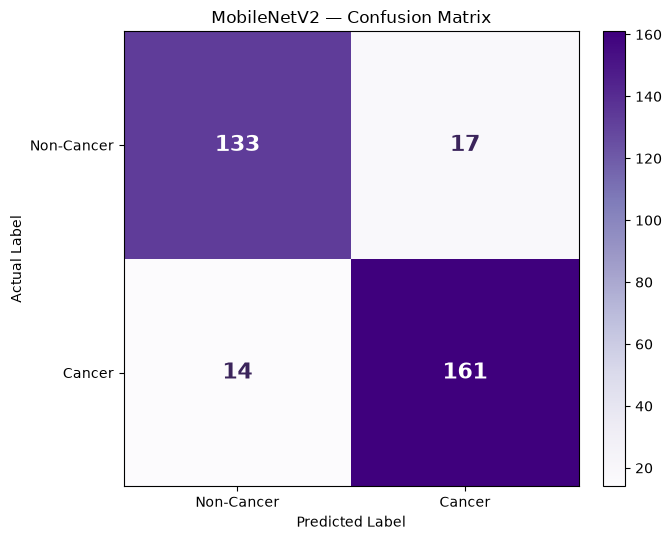


EVALUATING: EfficientNetB0
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 452ms/step

Evaluation metrics:
model                                 : EfficientNetB0
test_images                           : 325
threshold                             : 0.5000
accuracy                              : 0.8769
precision                             : 0.8771
sensitivity_recall                    : 0.8971
specificity                           : 0.8533
f1_score                              : 0.8870
roc_auc                               : 0.9665
pr_auc_average_precision              : 0.9707
balanced_accuracy                     : 0.8752
matthews_correlation_coefficient      : 0.7521
negative_predictive_value             : 0.8767
false_negative_rate                   : 0.1029
false_positive_rate                   : 0.1467
brier_score                           : 0.0803
log_loss                              : 0.2572
true_negative                         : 128
false_positive                        : 22
false_negative     

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\sklearn\metrics\_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


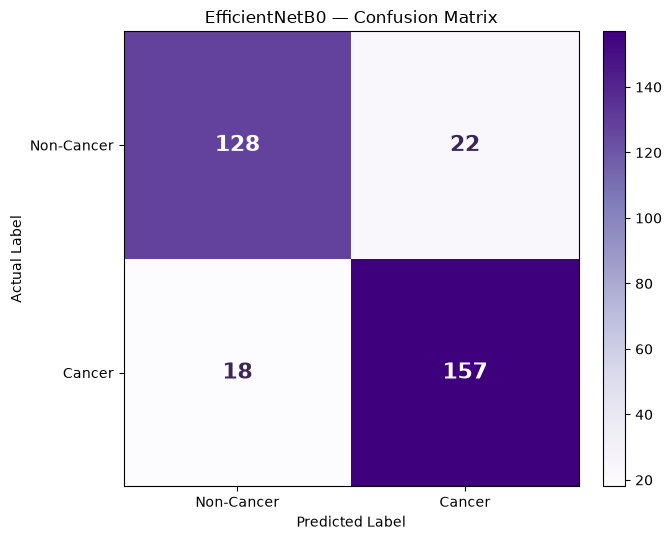


FINAL TEST METRICS COMPARISON
         model  accuracy  precision  sensitivity_recall  specificity  f1_score  roc_auc  pr_auc_average_precision  balanced_accuracy  matthews_correlation_coefficient  negative_predictive_value  false_negative_rate  false_positive_rate  brier_score  log_loss
   MobileNetV2    0.9046     0.9045              0.9200       0.8867    0.9122   0.9596                    0.9629             0.9033                            0.8080                     0.9048               0.0800               0.1133       0.0744    0.2587
EfficientNetB0    0.8769     0.8771              0.8971       0.8533    0.8870   0.9665                    0.9707             0.8752                            0.7521                     0.8767               0.1029               0.1467       0.0803    0.2572


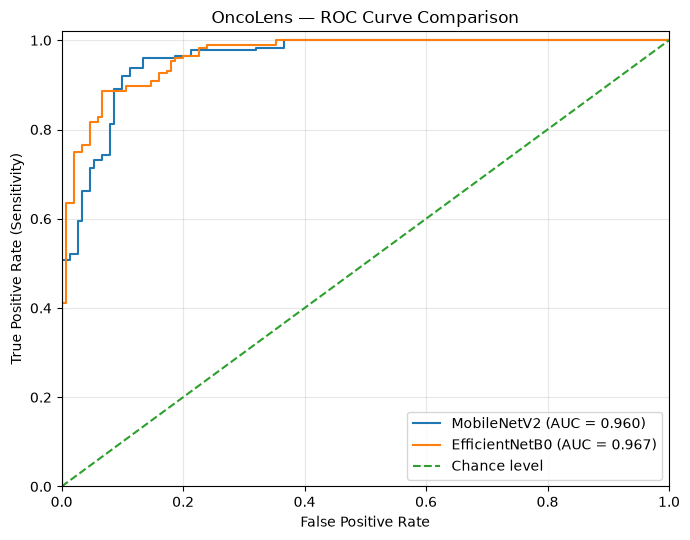

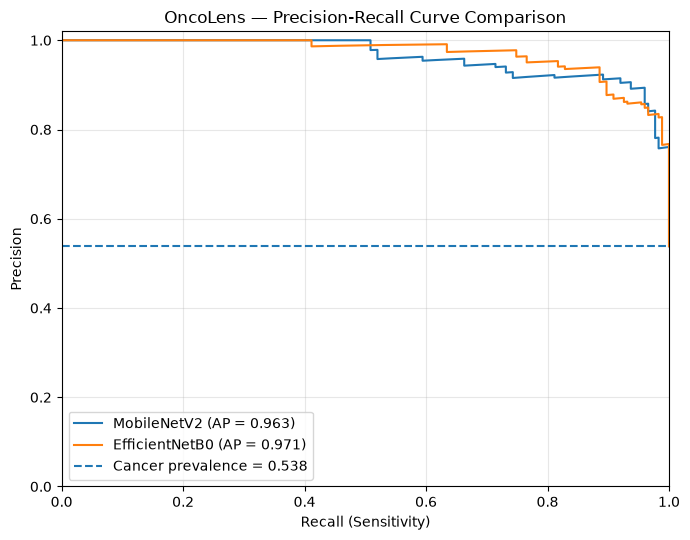

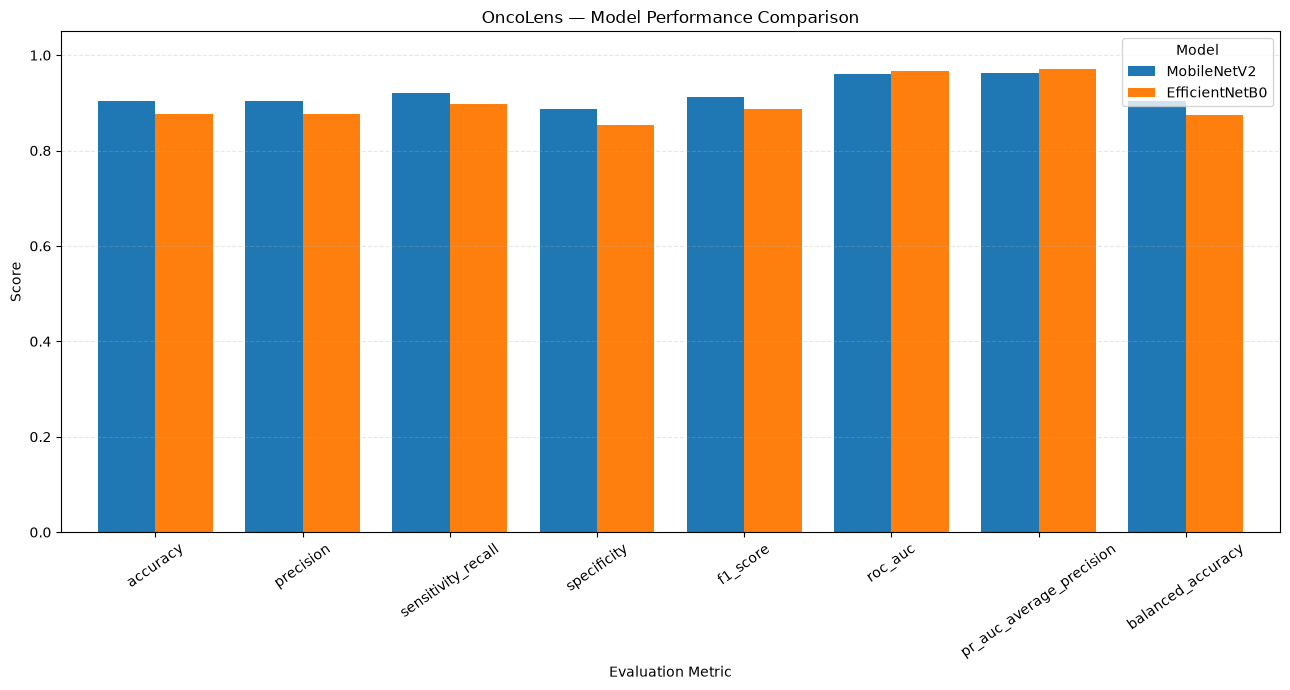

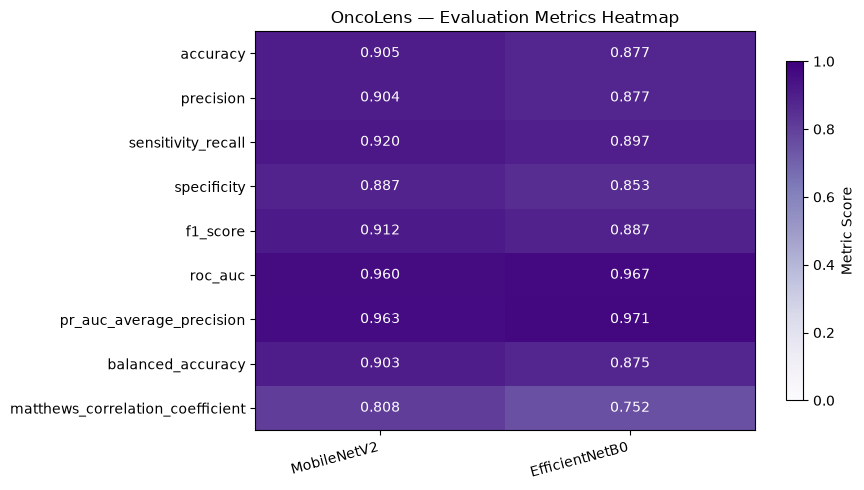

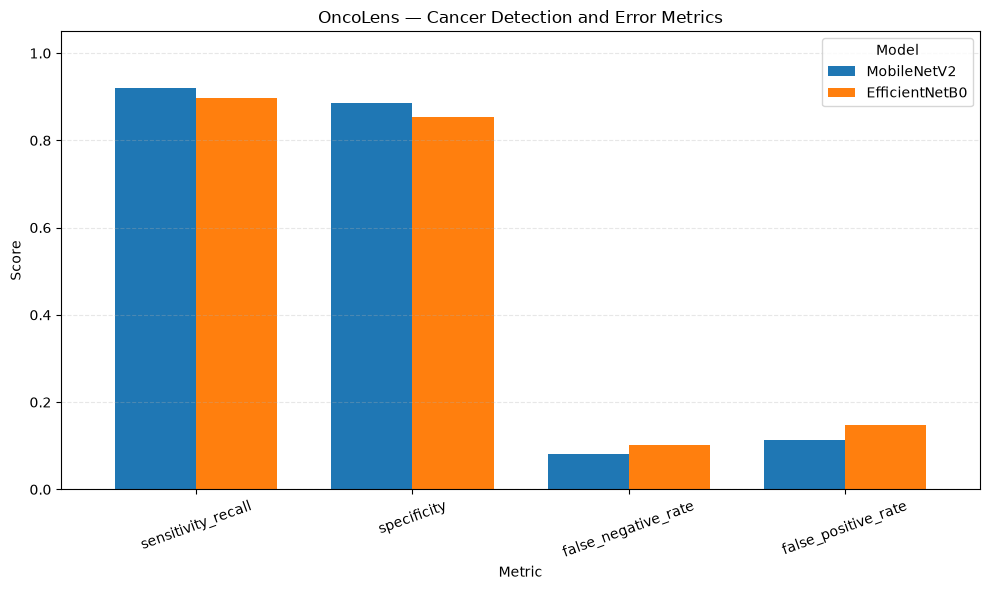


STEP 08 COMPLETED SUCCESSFULLY
Eligible test images: 325
Models evaluated: MobileNetV2, EfficientNetB0
Preprocessing: sharpen
Fixed threshold: 0.5

Results directory:
C:\Users\Bhavana BV\Downloads\OncoLens\results\step08_final_test

Generated files:
 - all_test_metrics.json
 - cancer_detection_error_metrics.png
 - classification_report.csv
 - confusion_matrix.png
 - efficientnetb0_classification_report.csv
 - efficientnetb0_confusion_matrix.png
 - efficientnetb0_predictions.csv
 - evaluation_metrics_heatmap.png
 - evaluation_summary.json
 - mobilenetv2_classification_report.csv
 - mobilenetv2_confusion_matrix.png
 - mobilenetv2_predictions.csv
 - model_comparison.csv
 - model_performance_comparison.png
 - precision_recall_curve_comparison.png
 - roc_curve.png
 - roc_curve_comparison.png
 - test_metrics.csv
 - test_metrics.json
 - test_predictions.csv

Research note: This evaluates existing checkpoints. It does not retrain them on all 1,855 development images. Do not use test results t

In [ ]:

# =====================================================================
# ONCOLENS — STEP 08: OPTIMIZED FINAL TEST EVALUATION
# =====================================================================
# Models       : MobileNetV2 vs EfficientNetB0
# Preprocessing: Sharpen
# Test set     : 325 eligible held-out images
# Threshold    : 0.50 (fixed)
#
# METRICS:
# Accuracy, Precision, Sensitivity, Specificity, F1,
# ROC-AUC, PR-AUC, Balanced Accuracy, MCC, NPV,
# FNR, FPR, Brier Score, Log Loss.
#
# PLOTS:
# 1. MobileNetV2 confusion matrix
# 2. EfficientNetB0 confusion matrix
# 3. Combined ROC curve
# 4. Combined Precision-Recall curve
# 5. Model performance comparison
# 6. Metrics heatmap
# 7. Cancer detection/error metrics
#
# OUTPUT:
# results/step08_final_test/
# =====================================================================

from pathlib import Path
import gc
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    brier_score_loss,
    log_loss,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore", category=FutureWarning)

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")

SPLIT_FILE = ROOT / "split.csv"

CACHE_DIR = ROOT / "results" / "preproc"
INDEX_FILE = CACHE_DIR / "index.csv"
IMAGE_CACHE = CACHE_DIR / "sharpen.npy"

CHECKPOINT_DIR = ROOT / "checkpoints"

MODELS = {
    "MobileNetV2": CHECKPOINT_DIR / "mobilenetv2_sharpen.keras",
    "EfficientNetB0": CHECKPOINT_DIR / "efficientnetb0_sharpen.keras",
}

OUTPUT_DIR = ROOT / "results" / "step08_final_test"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD = 0.50
BATCH_SIZE = 32
EXPECTED_TEST_IMAGES = 325
IMAGE_SIZE = (224, 224, 3)
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 75)
print("ONCOLENS — STEP 08: FINAL TEST EVALUATION")
print("=" * 75)

# =====================================================================
# 2. VERIFY FILES
# =====================================================================

required_files = [
    SPLIT_FILE,
    INDEX_FILE,
    IMAGE_CACHE,
    *MODELS.values(),
]

missing_files = [
    str(file_path)
    for file_path in required_files
    if not file_path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "The following files are missing:\n\n"
        + "\n".join(missing_files)
        + "\n\nVerify ROOT and the checkpoint filenames."
    )

# =====================================================================
# 3. LOAD MANIFEST AND CACHE INDEX
# =====================================================================

split_df = pd.read_csv(SPLIT_FILE)
index_df = pd.read_csv(INDEX_FILE)

required_split_columns = {
    "path", "split", "label_id", "use", "group"
}

required_index_columns = {
    "path", "split", "y"
}

if not required_split_columns.issubset(split_df.columns):
    raise ValueError(
        f"Missing split.csv columns: "
        f"{required_split_columns - set(split_df.columns)}"
    )

if not required_index_columns.issubset(index_df.columns):
    raise ValueError(
        f"Missing index.csv columns: "
        f"{required_index_columns - set(index_df.columns)}"
    )


def normalize_path(value):
    return str(value).replace("\\", "/").strip().lower()


def parse_use(series):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)

    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes", "y"])
    )


split_df["path_key"] = split_df["path"].map(normalize_path)
index_df["path_key"] = index_df["path"].map(normalize_path)

if split_df["path_key"].duplicated().any():
    raise ValueError("Duplicate image paths found in split.csv.")

if index_df["path_key"].duplicated().any():
    raise ValueError("Duplicate image paths found in index.csv.")

# =====================================================================
# 4. SELECT ELIGIBLE TEST IMAGES
# =====================================================================

eligible_df = split_df.loc[
    parse_use(split_df["use"])
].copy()

eligible_df["split"] = (
    eligible_df["split"].astype(str).str.strip().str.lower()
)

test_manifest = eligible_df.loc[
    eligible_df["split"] == "test"
].copy()

if len(test_manifest) != EXPECTED_TEST_IMAGES:
    raise ValueError(
        f"Expected {EXPECTED_TEST_IMAGES} eligible test images, "
        f"but found {len(test_manifest)}. "
        "Check split.csv before evaluation."
    )

test_df = test_manifest.merge(
    index_df,
    on="path_key",
    how="left",
    suffixes=("_manifest", "_cache"),
    validate="one_to_one",
    indicator=True,
)

missing_cache = test_df["_merge"] != "both"

if missing_cache.any():
    missing_paths = test_df.loc[
        missing_cache, "path_manifest"
    ].astype(str).tolist()

    raise ValueError(
        "Eligible test images missing from the cache:\n"
        + "\n".join(missing_paths[:10])
    )

y_test = pd.to_numeric(
    test_df["label_id"], errors="raise"
).astype(np.int32).to_numpy()

cache_y = pd.to_numeric(
    test_df["y"], errors="raise"
).astype(np.int32).to_numpy()

if not np.array_equal(y_test, cache_y):
    raise ValueError(
        "Manifest labels and cache labels do not match."
    )

if not set(np.unique(y_test)).issubset({0, 1}):
    raise ValueError("Expected binary class labels 0 and 1.")

if len(np.unique(y_test)) != 2:
    raise ValueError(
        "The test set must contain both cancer and non-cancer classes."
    )

print("\nTest images:", len(test_df))
print("Non-cancer:", int(np.sum(y_test == 0)))
print("Cancer:", int(np.sum(y_test == 1)))
print("Threshold:", THRESHOLD)

# =====================================================================
# 5. LOAD AND ALIGN IMAGE CACHE
# =====================================================================

X_all = np.load(IMAGE_CACHE, mmap_mode="r")

if X_all.ndim != 4 or tuple(X_all.shape[1:]) != IMAGE_SIZE:
    raise ValueError(
        f"Invalid cache shape: {X_all.shape}; "
        f"expected (N, {IMAGE_SIZE})."
    )

index_positions = {
    path: position
    for position, path in enumerate(index_df["path_key"].tolist())
}

positions = np.asarray(
    [
        index_positions[path]
        for path in test_df["path_key"].tolist()
    ],
    dtype=np.int64,
)

# Load only the selected test images into memory.
X_test = np.asarray(X_all[positions], dtype=np.uint8)

if X_test.shape != (EXPECTED_TEST_IMAGES, *IMAGE_SIZE):
    raise ValueError(f"Unexpected test array shape: {X_test.shape}")

print("Image array:", X_test.shape)
print("Image dtype:", X_test.dtype)

# Release the memory-map reference before inference.
del X_all

# =====================================================================
# 6. METRIC CALCULATION
# =====================================================================

def calculate_metrics(y_true, y_pred, probabilities, model_name):

    p_cancer = probabilities[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    sensitivity = recall_score(
        y_true, y_pred, zero_division=0
    )

    specificity = (
        tn / (tn + fp) if (tn + fp) > 0 else np.nan
    )

    npv = (
        tn / (tn + fn) if (tn + fn) > 0 else np.nan
    )

    fnr = (
        fn / (fn + tp) if (fn + tp) > 0 else np.nan
    )

    fpr = (
        fp / (fp + tn) if (fp + tn) > 0 else np.nan
    )

    return {
        "model": model_name,
        "test_images": int(len(y_true)),
        "threshold": float(THRESHOLD),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(
            precision_score(y_true, y_pred, zero_division=0)
        ),
        "sensitivity_recall": float(sensitivity),
        "specificity": float(specificity),
        "f1_score": float(
            f1_score(y_true, y_pred, zero_division=0)
        ),
        "roc_auc": float(roc_auc_score(y_true, p_cancer)),
        "pr_auc_average_precision": float(
            average_precision_score(y_true, p_cancer)
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "matthews_correlation_coefficient": float(
            matthews_corrcoef(y_true, y_pred)
        ),
        "negative_predictive_value": float(npv),
        "false_negative_rate": float(fnr),
        "false_positive_rate": float(fpr),
        "brier_score": float(
            brier_score_loss(y_true, p_cancer)
        ),
        "log_loss": float(
            log_loss(y_true, probabilities, labels=[0, 1])
        ),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }


# =====================================================================
# 7. EVALUATE ONE MODEL
# =====================================================================

def evaluate_model(model_name, model_path):

    print("\n" + "=" * 70)
    print(f"EVALUATING: {model_name}")
    print("=" * 70)

    model = tf.keras.models.load_model(
        model_path,
        compile=False,
    )

    if len(model.output_shape) != 2 or model.output_shape[-1] != 2:
        raise ValueError(
            f"{model_name} must produce two-class probabilities; "
            f"got {model.output_shape}."
        )

    probabilities = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=1,
    )

    probabilities = np.asarray(
        probabilities, dtype=np.float64
    )

    if probabilities.shape != (len(y_test), 2):
        raise ValueError(
            f"Unexpected predictions shape: {probabilities.shape}"
        )

    if not np.isfinite(probabilities).all():
        raise ValueError("Non-finite predictions detected.")

    if np.any(probabilities < -1e-6) or np.any(
        probabilities > 1.0 + 1e-6
    ):
        raise ValueError("Predictions fall outside [0, 1].")

    if not np.allclose(
        probabilities.sum(axis=1), 1.0, atol=1e-3
    ):
        raise ValueError(
            "Model outputs do not sum to 1. "
            "Verify the two-class softmax output."
        )

    p_cancer = probabilities[:, 1]
    y_pred = (p_cancer >= THRESHOLD).astype(np.int32)

    metrics = calculate_metrics(
        y_test,
        y_pred,
        probabilities,
        model_name,
    )

    print("\nEvaluation metrics:")

    for key, value in metrics.items():
        if isinstance(value, (float, np.floating)):
            print(f"{key:38s}: {value:.4f}")
        else:
            print(f"{key:38s}: {value}")

    # -------------------------------------------------------------
    # Classification report
    # -------------------------------------------------------------

    report = classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["non_cancer", "cancer"],
        zero_division=0,
        output_dict=True,
    )

    pd.DataFrame(report).transpose().to_csv(
        OUTPUT_DIR / f"{model_name.lower()}_classification_report.csv"
    )

    # -------------------------------------------------------------
    # Save individual predictions
    # -------------------------------------------------------------

    predictions_df = pd.DataFrame({
        "path": test_df["path_manifest"].astype(str).to_numpy(),
        "group": test_df["group"].astype(str).to_numpy(),
        "y_true": y_test,
        "y_pred": y_pred,
        "probability_non_cancer": probabilities[:, 0],
        "probability_cancer": p_cancer,
        "threshold": THRESHOLD,
    })

    predictions_df.to_csv(
        OUTPUT_DIR / f"{model_name.lower()}_predictions.csv",
        index=False,
    )

    # -------------------------------------------------------------
    # Confusion matrix
    # -------------------------------------------------------------

    cm = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(7, 5.5))

    image = ax.imshow(cm, cmap="Purples", interpolation="nearest")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

    ax.set(
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=["Non-Cancer", "Cancer"],
        yticklabels=["Non-Cancer", "Cancer"],
        xlabel="Predicted Label",
        ylabel="Actual Label",
        title=f"{model_name} — Confusion Matrix",
    )

    midpoint = cm.max() / 2.0

    for row in range(2):
        for col in range(2):
            ax.text(
                col,
                row,
                f"{cm[row, col]}",
                ha="center",
                va="center",
                fontsize=16,
                fontweight="bold",
                color=(
                    "white"
                    if cm[row, col] > midpoint
                    else "#3B245B"
                ),
            )

    plt.tight_layout()
    fig.savefig(
        OUTPUT_DIR / f"{model_name.lower()}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    # -------------------------------------------------------------
    # Curves
    # -------------------------------------------------------------

    roc_fpr, roc_tpr, _ = roc_curve(y_test, p_cancer)

    pr_precision, pr_recall, _ = precision_recall_curve(
        y_test, p_cancer
    )

    result = {
        "metrics": metrics,
        "probabilities": probabilities,
        "predictions": y_pred,
        "roc_fpr": roc_fpr,
        "roc_tpr": roc_tpr,
        "pr_precision": pr_precision,
        "pr_recall": pr_recall,
    }

    del model
    tf.keras.backend.clear_session()
    gc.collect()

    return result


# =====================================================================
# 8. RUN BOTH MODELS
# =====================================================================

results = {}

for name, model_path in MODELS.items():
    results[name] = evaluate_model(name, model_path)

# =====================================================================
# 9. SAVE MODEL COMPARISON
# =====================================================================

comparison_df = pd.DataFrame(
    [results[name]["metrics"] for name in MODELS]
)

comparison_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False,
)

with open(
    OUTPUT_DIR / "all_test_metrics.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        {
            name: result["metrics"]
            for name, result in results.items()
        },
        file,
        indent=4,
        allow_nan=True,
    )

print("\n" + "=" * 100)
print("FINAL TEST METRICS COMPARISON")
print("=" * 100)

display_columns = [
    "model",
    "accuracy",
    "precision",
    "sensitivity_recall",
    "specificity",
    "f1_score",
    "roc_auc",
    "pr_auc_average_precision",
    "balanced_accuracy",
    "matthews_correlation_coefficient",
    "negative_predictive_value",
    "false_negative_rate",
    "false_positive_rate",
    "brier_score",
    "log_loss",
]

print(
    comparison_df[display_columns]
    .round(4)
    .to_string(index=False)
)

# =====================================================================
# 10. COMBINED ROC CURVE
# =====================================================================

fig, ax = plt.subplots(figsize=(7, 5.5))

for name in MODELS:
    result = results[name]
    auc_value = result["metrics"]["roc_auc"]

    ax.plot(
        result["roc_fpr"],
        result["roc_tpr"],
        label=f"{name} (AUC = {auc_value:.3f})",
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Chance level",
)

ax.set(
    xlabel="False Positive Rate",
    ylabel="True Positive Rate (Sensitivity)",
    title="OncoLens — ROC Curve Comparison",
    xlim=(0, 1),
    ylim=(0, 1.02),
)

ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# =====================================================================
# 11. COMBINED PRECISION-RECALL CURVE
# =====================================================================

fig, ax = plt.subplots(figsize=(7, 5.5))

for name in MODELS:
    result = results[name]
    ap = result["metrics"]["pr_auc_average_precision"]

    ax.plot(
        result["pr_recall"],
        result["pr_precision"],
        label=f"{name} (AP = {ap:.3f})",
    )

# Prevalence is the baseline precision for a no-skill classifier.
prevalence = float(np.mean(y_test))

ax.axhline(
    prevalence,
    linestyle="--",
    label=f"Cancer prevalence = {prevalence:.3f}",
)

ax.set(
    xlabel="Recall (Sensitivity)",
    ylabel="Precision",
    title="OncoLens — Precision-Recall Curve Comparison",
    xlim=(0, 1),
    ylim=(0, 1.02),
)

ax.legend(loc="lower left")
ax.grid(True, alpha=0.3)
plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "precision_recall_curve_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# =====================================================================
# 12. MODEL PERFORMANCE COMPARISON CHART
# =====================================================================

performance_metrics = [
    "accuracy",
    "precision",
    "sensitivity_recall",
    "specificity",
    "f1_score",
    "roc_auc",
    "pr_auc_average_precision",
    "balanced_accuracy",
]

performance_df = comparison_df.set_index("model")[
    performance_metrics
].T

ax = performance_df.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.78,
)

ax.set(
    title="OncoLens — Model Performance Comparison",
    xlabel="Evaluation Metric",
    ylabel="Score",
    ylim=(0, 1.05),
)

ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="Model")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()

# =====================================================================
# 13. METRICS HEATMAP
# =====================================================================

heatmap_metrics = [
    "accuracy",
    "precision",
    "sensitivity_recall",
    "specificity",
    "f1_score",
    "roc_auc",
    "pr_auc_average_precision",
    "balanced_accuracy",
    "matthews_correlation_coefficient",
]

heatmap_df = comparison_df.set_index("model")[
    heatmap_metrics
].T

values = heatmap_df.to_numpy(dtype=float)

fig, ax = plt.subplots(
    figsize=(9, max(5, len(heatmap_metrics) * 0.55))
)

image = ax.imshow(
    values,
    cmap="Purples",
    aspect="auto",
    vmin=-1 if np.nanmin(values) < 0 else 0,
    vmax=1,
)

fig.colorbar(image, ax=ax, label="Metric Score", shrink=0.85)

ax.set_xticks(range(len(heatmap_df.columns)))
ax.set_xticklabels(heatmap_df.columns, rotation=15, ha="right")
ax.set_yticks(range(len(heatmap_df.index)))
ax.set_yticklabels(heatmap_df.index)

ax.set_title("OncoLens — Evaluation Metrics Heatmap")

for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        if np.isfinite(values[i, j]):
            ax.text(
                j,
                i,
                f"{values[i, j]:.3f}",
                ha="center",
                va="center",
                fontsize=10,
                color=(
                    "white"
                    if values[i, j] > 0.60
                    else "#3B245B"
                ),
            )

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "evaluation_metrics_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# =====================================================================
# 14. CANCER DETECTION AND ERROR METRICS
# =====================================================================

error_metrics = [
    "sensitivity_recall",
    "specificity",
    "false_negative_rate",
    "false_positive_rate",
]

error_df = comparison_df.set_index("model")[
    error_metrics
].T

ax = error_df.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75,
)

ax.set(
    title="OncoLens — Cancer Detection and Error Metrics",
    xlabel="Metric",
    ylabel="Score",
    ylim=(0, 1.05),
)

ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="Model")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "cancer_detection_error_metrics.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()

# =====================================================================
# 15. SAVE A COMPACT RESULTS SUMMARY
# =====================================================================

summary = {
    "test_images": int(len(y_test)),
    "cancer_images": int(np.sum(y_test == 1)),
    "non_cancer_images": int(np.sum(y_test == 0)),
    "threshold": THRESHOLD,
    "preprocessing": "sharpen",
    "models_evaluated": list(MODELS.keys()),
}

with open(
    OUTPUT_DIR / "evaluation_summary.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(summary, file, indent=4)

assert len(y_test) == EXPECTED_TEST_IMAGES

for name in MODELS:
    assert len(results[name]["predictions"]) == EXPECTED_TEST_IMAGES

print("\n" + "=" * 75)
print("STEP 08 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Eligible test images:", len(y_test))
print("Models evaluated:", ", ".join(MODELS.keys()))
print("Preprocessing: sharpen")
print("Fixed threshold:", THRESHOLD)
print("\nResults directory:")
print(OUTPUT_DIR)

print("\nGenerated files:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print(" -", file.name)

print(
    "\nResearch note: This evaluates existing checkpoints. "
    "It does not retrain them on all 1,855 development images. "
    "Do not use test results to tune the models or classification threshold."
)

In [ ]:
# ================================================================
# ONCOLENS — STEP 09
# GRAD-CAM EXPLAINABLE AI
# MobileNetV2 vs EfficientNetB0
# ================================================================

from pathlib import Path
import warnings
import json

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# ================================================================
# 1. CONFIGURATION
# ================================================================

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")

SPLIT_FILE = ROOT / "split.csv"
INDEX_FILE = ROOT / "results" / "preproc" / "index.csv"
SHARPEN_CACHE = ROOT / "results" / "preproc" / "sharpen.npy"

MODEL_PATHS = {
    "MobileNetV2": ROOT / "checkpoints" / "mobilenetv2_sharpen.keras",
    "EfficientNetB0": ROOT / "checkpoints" / "efficientnetb0_sharpen.keras",
}

OUTPUT_DIR = ROOT / "results" / "step09_gradcam"
HEATMAP_DIR = OUTPUT_DIR / "heatmaps"
OVERLAY_DIR = OUTPUT_DIR / "overlays"
COMPARISON_DIR = OUTPUT_DIR / "comparisons"

for directory in [
    OUTPUT_DIR,
    HEATMAP_DIR,
    OVERLAY_DIR,
    COMPARISON_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# 0 = non-cancer, 1 = cancer
CANCER_CLASS_INDEX = 1

# Number of test images to explain.
# Set to None to process every eligible test image.
MAX_IMAGES = 30

# True: prioritize correctly and incorrectly classified cancer cases.
# False: select the first MAX_IMAGES test images.
PRIORITIZE_CANCER_CASES = True

# ================================================================
# 2. CHECK REQUIRED FILES
# ================================================================

required_files = [
    SPLIT_FILE,
    INDEX_FILE,
    SHARPEN_CACHE,
    *MODEL_PATHS.values(),
]

missing_files = [str(p) for p in required_files if not p.exists()]

if missing_files:
    raise FileNotFoundError(
        "The following required files are missing:\n"
        + "\n".join(missing_files)
    )

print("=" * 72)
print("ONCOLENS — STEP 09: GRAD-CAM EXPLAINABILITY")
print("=" * 72)

# ================================================================
# 3. LOAD MANIFEST AND PREPROCESSING INDEX
# ================================================================

split_df = pd.read_csv(SPLIT_FILE)
index_df = pd.read_csv(INDEX_FILE)

def normalize_path(value):
    return str(value).replace("\\", "/").strip().lower()

def find_column(df, candidates, required=True):
    normalized = {
        str(col).strip().lower().replace(" ", "_"): col
        for col in df.columns
    }

    for candidate in candidates:
        key = candidate.strip().lower().replace(" ", "_")
        if key in normalized:
            return normalized[key]

    if required:
        raise ValueError(
            f"Could not find any of {candidates}.\n"
            f"Available columns: {df.columns.tolist()}"
        )

    return None

split_path_col = find_column(
    split_df,
    ["path", "image_path", "filepath", "file_path", "filename"]
)

index_path_col = find_column(
    index_df,
    ["path", "image_path", "filepath", "file_path", "filename"]
)

split_label_col = find_column(
    split_df,
    ["label_id", "label", "class_id", "target"]
)

index_label_col = find_column(
    index_df,
    ["label_id", "label", "class_id", "target", "y"]
)

split_name_col = find_column(
    split_df,
    ["split", "subset", "partition"]
)

use_col = find_column(
    split_df,
    ["use", "eligible", "include"],
    required=False
)

# Filter the existing test split.
test_manifest = split_df[
    split_df[split_name_col].astype(str).str.lower().eq("test")
].copy()

# Preserve the existing eligibility decision.
if use_col is not None:
    use_values = test_manifest[use_col]

    if use_values.dtype == bool:
        eligible_mask = use_values
    else:
        eligible_mask = (
            use_values.astype(str)
            .str.strip()
            .str.lower()
            .isin(["true", "1", "yes"])
        )

    test_manifest = test_manifest[eligible_mask].copy()

test_manifest["path_key"] = (
    test_manifest[split_path_col].map(normalize_path)
)

index_df["path_key"] = index_df[index_path_col].map(normalize_path)

# Retain only paths present in the validated preprocessing cache.
test_df = test_manifest.merge(
    index_df,
    on="path_key",
    how="inner",
    suffixes=("_manifest", "_index"),
)

manifest_label_name = f"{split_label_col}_manifest"
index_label_name = f"{index_label_col}_index"

# When the label columns have different names, suffixes may not be added.
if manifest_label_name not in test_df.columns:
    manifest_label_name = split_label_col

if index_label_name not in test_df.columns:
    index_label_name = index_label_col

if manifest_label_name != index_label_name:
    manifest_labels = pd.to_numeric(
        test_df[manifest_label_name], errors="raise"
    ).to_numpy()

    index_labels = pd.to_numeric(
        test_df[index_label_name], errors="raise"
    ).to_numpy()

    if not np.array_equal(manifest_labels, index_labels):
        raise ValueError(
            "The manifest and preprocessing index labels do not match."
        )

test_df["label_id"] = pd.to_numeric(
    test_df[manifest_label_name],
    errors="raise"
).astype(int)

test_df["path"] = test_df[f"{split_path_col}_manifest"] \
    if f"{split_path_col}_manifest" in test_df.columns \
    else test_df[split_path_col]

test_df = test_df.reset_index(drop=True)

if len(test_df) == 0:
    raise ValueError(
        "No eligible test images matched the preprocessing index. "
        "Inspect the paths in split.csv and index.csv."
    )

print(f"\nEligible test images found: {len(test_df)}")

# ================================================================
# 4. LOAD THE SHARPEN-PREPROCESSED IMAGE CACHE
# ================================================================

cache = np.load(SHARPEN_CACHE, mmap_mode="r")

if len(cache) != len(index_df):
    raise ValueError(
        f"Cache/index length mismatch: {len(cache)} vs {len(index_df)}"
    )

# Map normalized cache paths to cache row indices.
cache_position = {
    path: i
    for i, path in enumerate(index_df["path_key"].tolist())
}

test_df["cache_index"] = test_df["path_key"].map(cache_position)

if test_df["cache_index"].isna().any():
    raise ValueError(
        "Some test images do not have a valid cache index."
    )

test_df["cache_index"] = test_df["cache_index"].astype(int)

# ================================================================
# 5. SELECT TEST IMAGES
# ================================================================

if PRIORITIZE_CANCER_CASES:
    # Explain cancer images and include a mixture of correct and
    # incorrect predictions when predictions can be calculated.
    # If model predictions are unavailable at selection time, use
    # the test order and include cancer cases first.
    cancer_df = test_df[test_df["label_id"] == CANCER_CLASS_INDEX]
    noncancer_df = test_df[test_df["label_id"] != CANCER_CLASS_INDEX]

    if MAX_IMAGES is None:
        selected_df = test_df.copy()
    else:
        n_cancer = min(
            int(np.ceil(MAX_IMAGES * 0.7)),
            len(cancer_df)
        )

        selected_df = pd.concat(
            [
                cancer_df.head(n_cancer),
                noncancer_df.head(MAX_IMAGES - n_cancer),
            ],
            axis=0,
        ).drop_duplicates(subset=["path_key"])

        if len(selected_df) < min(MAX_IMAGES, len(test_df)):
            remaining = test_df[
                ~test_df["path_key"].isin(selected_df["path_key"])
            ]

            selected_df = pd.concat(
                [
                    selected_df,
                    remaining.head(
                        min(MAX_IMAGES, len(test_df)) - len(selected_df)
                    ),
                ],
                axis=0,
            )

        selected_df = selected_df.head(MAX_IMAGES).copy()

else:
    selected_df = (
        test_df.copy()
        if MAX_IMAGES is None
        else test_df.head(MAX_IMAGES).copy()
    )

selected_df = selected_df.reset_index(drop=True)

print(f"Images selected for Grad-CAM: {len(selected_df)}")

# ================================================================
# 6. LOAD MODELS
# ================================================================

models = {}

for model_name, model_path in MODEL_PATHS.items():
    print(f"\nLoading {model_name}...")

    models[model_name] = tf.keras.models.load_model(
        model_path,
        compile=False,
    )

    print(f"{model_name} loaded successfully.")

# ================================================================
# 7. FIND BACKBONE AND LAST CONVOLUTIONAL LAYER
# Keras 3-compatible implementation
# ================================================================

def find_last_conv_layer(model):
    """
    Find the last Conv2D layer by traversing the model backwards.
    """
    for layer in reversed(model.layers):

        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer

        if isinstance(layer, tf.keras.Model):
            conv = find_last_conv_layer(layer)

            if conv is not None:
                return conv

    return None


def find_backbone_and_conv(model):
    """
    Find the nested pretrained backbone and its last convolution.
    """
    candidates = []

    for layer in model.layers:

        if isinstance(layer, tf.keras.Model):
            conv = find_last_conv_layer(layer)

            if conv is not None:
                candidates.append((layer, conv))

    if not candidates:
        raise ValueError(
            "No nested convolutional backbone was found. "
            "Inspect the model architecture."
        )

    backbone, conv_layer = candidates[-1]

    print(f"Backbone: {backbone.name}")
    print(f"Last convolutional layer: {conv_layer.name}")

    return backbone, conv_layer


# ================================================================
# 8. BUILD CONNECTED GRAD-CAM GRAPH
# Fix for Keras 3 nested-model disconnection
# ================================================================

def make_gradcam_function(model, model_name):

    backbone, conv_layer = find_backbone_and_conv(model)

    # Create a probe INSIDE the backbone.
    # Both outputs must be connected to the backbone's own input.
    try:
        backbone_probe = tf.keras.Model(
            inputs=backbone.inputs,
            outputs=[
                conv_layer.output,
                backbone.output,
            ],
            name=f"{model_name.lower()}_backbone_probe",
        )

    except Exception as exc:
        raise RuntimeError(
            f"Could not create the backbone probe for {model_name}. "
            f"Layer: {conv_layer.name}. Error: {exc}"
        ) from exc

    # Reconstruct the original top-level model graph.
    #
    # Layers before the backbone perform preprocessing.
    # The backbone probe returns both convolutional maps and the
    # backbone's final features.
    # Layers after the backbone perform classification.

    model_input = model.inputs[0]
    x = model_input
    conv_maps = None
    backbone_found = False

    try:
        for layer in model.layers:

            if isinstance(layer, tf.keras.layers.InputLayer):
                continue

            if layer is backbone:

                conv_maps, x = backbone_probe(
                    x,
                    training=False,
                )

                backbone_found = True

            else:

                x = layer(
                    x,
                    training=False,
                )

        if not backbone_found:
            raise ValueError(
                f"Could not reconnect backbone {backbone.name} "
                "to the top-level classification model."
            )

        grad_model = tf.keras.Model(
            inputs=model_input,
            outputs=[conv_maps, x],
            name=f"{model_name.lower()}_gradcam_model",
        )

    except Exception as exc:
        raise RuntimeError(
            f"Could not reconstruct the Grad-CAM graph for "
            f"{model_name}. Error: {exc}"
        ) from exc

    print(f"Grad-CAM graph built successfully: {model_name}")

    # ------------------------------------------------------------
    # Grad-CAM calculation
    # ------------------------------------------------------------

    def gradcam(images, target_class=CANCER_CLASS_INDEX):

        images = tf.convert_to_tensor(
            images,
            dtype=tf.float32,
        )

        with tf.GradientTape() as tape:

            conv_outputs, predictions = grad_model(
                images,
                training=False,
            )

            # Binary classifier with two softmax outputs:
            # index 0 = non-cancer
            # index 1 = cancer
            if predictions.shape[-1] == 1:
                class_scores = predictions[:, 0]
            else:
                class_scores = predictions[:, target_class]

        gradients = tape.gradient(
            class_scores,
            conv_outputs,
        )

        if gradients is None:
            raise RuntimeError(
                f"Gradients are disconnected for {model_name}. "
                "Check the backbone probe and model architecture."
            )

        # Global-average-pool gradients to obtain channel weights.
        weights = tf.reduce_mean(
            gradients,
            axis=(1, 2),
            keepdims=True,
        )

        # Weighted combination of convolutional feature maps.
        heatmaps = tf.reduce_sum(
            weights * conv_outputs,
            axis=-1,
        )

        # Retain positive contributions.
        heatmaps = tf.nn.relu(heatmaps)

        # Normalize each heatmap independently to [0, 1].
        minimum = tf.reduce_min(
            heatmaps,
            axis=(1, 2),
            keepdims=True,
        )

        maximum = tf.reduce_max(
            heatmaps,
            axis=(1, 2),
            keepdims=True,
        )

        heatmaps = tf.math.divide_no_nan(
            heatmaps - minimum,
            maximum - minimum,
        )

        return heatmaps.numpy(), predictions.numpy()

    return gradcam


# ================================================================
# INITIALIZE GRAD-CAM FOR BOTH MODELS
# ================================================================

gradcam_functions = {}

for model_name, model in models.items():

    print(f"\nInitializing Grad-CAM for {model_name}...")

    gradcam_functions[model_name] = make_gradcam_function(
        model,
        model_name,
    )

print("\nBoth Grad-CAM functions initialized successfully.")
# ================================================================
# 9. LOAD RGB IMAGE FOR DISPLAY
# ================================================================

def load_original_rgb(path):
    path = Path(str(path))

    if not path.is_absolute():
        path = ROOT / path

    with Image.open(path) as image:
        return image.convert("RGB").resize(IMAGE_SIZE)


def cache_to_rgb(array):
    """
    Convert the cached sharpen image to RGB for display.

    The original cache is uint8 RGB, so no model normalization is
    applied here.
    """
    arr = np.asarray(array)

    if arr.ndim != 3 or arr.shape[-1] != 3:
        raise ValueError(
            f"Expected image shape (H, W, 3), got {arr.shape}"
        )

    if arr.dtype != np.uint8:
        arr = np.clip(arr, 0, 255).astype(np.uint8)

    return arr


def get_model_input(cache_image):
    """
    Models have preprocessing layers inside their architecture.
    Pass the uint8 sharpen image as float32 without external
    MobileNetV2/EfficientNetB0 normalization.
    """
    return np.asarray(cache_image, dtype=np.float32)


# ================================================================
# 10. GENERATE AND SAVE GRAD-CAM RESULTS
# ================================================================

def predictions_to_probability(predictions):
    predictions = np.asarray(predictions)

    if predictions.ndim == 1:
        p_cancer = predictions
    elif predictions.shape[-1] == 1:
        p_cancer = predictions[:, 0]
    elif predictions.shape[-1] == 2:
        p_cancer = predictions[:, CANCER_CLASS_INDEX]
    else:
        raise ValueError(
            f"Unexpected prediction shape: {predictions.shape}"
        )

    return np.asarray(p_cancer, dtype=float)


def overlay_heatmap(rgb_image, cam, alpha=0.40):
    """
    Apply a Matplotlib heatmap to an RGB image.
    """
    rgb_image = np.asarray(rgb_image).astype(np.uint8)

    cam_image = Image.fromarray(
        np.uint8(np.clip(cam, 0, 1) * 255)
    ).resize(
        (rgb_image.shape[1], rgb_image.shape[0]),
        Image.Resampling.BILINEAR,
    )

    cam_resized = np.asarray(cam_image, dtype=np.float32) / 255.0

    heatmap_rgb = plt.get_cmap("jet")(cam_resized)[..., :3]
    heatmap_rgb = np.uint8(np.clip(heatmap_rgb * 255, 0, 255))

    overlay = (
        (1 - alpha) * rgb_image.astype(np.float32)
        + alpha * heatmap_rgb.astype(np.float32)
    )

    return np.uint8(np.clip(overlay, 0, 255)), heatmap_rgb


records = []

for start in range(0, len(selected_df), BATCH_SIZE):
    batch_df = selected_df.iloc[start:start + BATCH_SIZE]

    batch_images = np.stack([
        get_model_input(cache[int(row.cache_index)])
        for row in batch_df.itertuples()
    ]).astype(np.float32)

    batch_labels = batch_df["label_id"].to_numpy(dtype=int)

    batch_cams = {}
    batch_probabilities = {}
    batch_predictions = {}

    # Generate explanations for each model.
    for model_name, gradcam_fn in gradcam_functions.items():
        cams, model_outputs = gradcam_fn(
            batch_images,
            target_class=CANCER_CLASS_INDEX,
        )

        probs = predictions_to_probability(model_outputs)

        batch_cams[model_name] = cams
        batch_probabilities[model_name] = probs
        batch_predictions[model_name] = (
            probs >= 0.5
        ).astype(int)

    # Save per-image results.
    for i, row in enumerate(batch_df.itertuples()):
        image_id = start + i
        relative_path = str(row.path)
        true_label = int(row.label_id)

        cache_rgb = cache_to_rgb(cache[int(row.cache_index)])

        # The cache image is the sharpen-preprocessed input.
        # Also load the source image for display when available.
        try:
            original_rgb = np.asarray(
                load_original_rgb(relative_path)
            )
        except Exception:
            original_rgb = cache_rgb

        record = {
            "image_id": image_id,
            "path": relative_path,
            "true_label": true_label,
            "true_class": (
                "Cancer" if true_label == 1 else "Non-cancer"
            ),
        }

        comparison_panels = [
            ("Original image", original_rgb)
        ]

        for model_name in MODEL_PATHS:
            cam = batch_cams[model_name][i]

            prob = float(batch_probabilities[model_name][i])
            pred = int(batch_predictions[model_name][i])

            overlay, heatmap_rgb = overlay_heatmap(
                original_rgb,
                cam,
            )

            model_key = model_name.lower()

            heatmap_path = HEATMAP_DIR / (
                f"{image_id:04d}_{model_key}_heatmap.png"
            )

            overlay_path = OVERLAY_DIR / (
                f"{image_id:04d}_{model_key}_overlay.png"
            )

            Image.fromarray(heatmap_rgb).save(heatmap_path)
            Image.fromarray(overlay).save(overlay_path)

            record[f"{model_key}_probability_cancer"] = prob
            record[f"{model_key}_predicted_label"] = pred
            record[f"{model_key}_predicted_class"] = (
                "Cancer" if pred == 1 else "Non-cancer"
            )
            record[f"{model_key}_correct"] = bool(
                pred == true_label
            )
            record[f"{model_key}_heatmap_path"] = str(heatmap_path)
            record[f"{model_key}_overlay_path"] = str(overlay_path)

            comparison_panels.append(
                (
                    f"{model_name}\n"
                    f"Pred: {'Cancer' if pred else 'Non-cancer'}\n"
                    f"P(cancer)={prob:.3f}",
                    overlay,
                )
            )

        # Generate a side-by-side comparison figure.
        fig, axes = plt.subplots(
            1,
            len(comparison_panels),
            figsize=(5 * len(comparison_panels), 5),
        )

        if len(comparison_panels) == 1:
            axes = [axes]

        for ax, (title, panel_image) in zip(
            axes,
            comparison_panels
        ):
            ax.imshow(panel_image)
            ax.set_title(title)
            ax.axis("off")

        fig.suptitle(
            f"OncoLens Grad-CAM | Image {image_id} | "
            f"True: {'Cancer' if true_label else 'Non-cancer'}",
            fontsize=13,
        )

        fig.tight_layout()

        comparison_path = COMPARISON_DIR / (
            f"{image_id:04d}_gradcam_comparison.png"
        )

        fig.savefig(
            comparison_path,
            dpi=250,
            bbox_inches="tight",
        )

        plt.close(fig)

        record["comparison_path"] = str(comparison_path)
        records.append(record)

    print(
        f"Processed {min(start + BATCH_SIZE, len(selected_df))}"
        f"/{len(selected_df)} images"
    )

# ================================================================
# ONCOLENS — STEP 09: FIX AND SAVE FINAL SUMMARY
# ================================================================

import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
)

# Reuse the results generated by the completed Grad-CAM run.
OUTPUT_DIR = ROOT / "results" / "step09_gradcam"

results_csv = OUTPUT_DIR / "gradcam_predictions_summary.csv"

# Save again in case the earlier execution stopped before saving.
results_df.to_csv(results_csv, index=False)

summary = {
    "project": "OncoLens",
    "step": "Step 09 — Grad-CAM Explainable AI",
    "images_explained": int(len(results_df)),
    "class_encoding": {
        "0": "Non-cancer",
        "1": "Cancer",
    },
    "models": {},
    "interpretation_warning": (
        "Grad-CAM visualizes image regions contributing to the "
        "selected model score. Highlighted regions do not prove "
        "malignancy or establish clinical validity."
    ),
}

for model_name in MODEL_PATHS:

    key = model_name.lower()

    y_true = results_df["true_label"].to_numpy(dtype=int)

    y_pred = results_df[
        f"{key}_predicted_label"
    ].to_numpy(dtype=int)

    probabilities = results_df[
        f"{key}_probability_cancer"
    ].to_numpy(dtype=float)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    summary["models"][model_name] = {
        "accuracy": float(np.mean(y_true == y_pred)),
        "sensitivity": (
            float(tp / (tp + fn)) if (tp + fn) else None
        ),
        "specificity": (
            float(tn / (tn + fp)) if (tn + fp) else None
        ),
        "roc_auc": (
            float(roc_auc_score(y_true, probabilities))
            if len(np.unique(y_true)) == 2
            else None
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }

summary_path = OUTPUT_DIR / "gradcam_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=4)

print("=" * 65)
print("ONCOLENS — STEP 09 COMPLETED")
print("=" * 65)

print(f"\nImages explained: {len(results_df)}")
print(f"Predictions CSV:  {results_csv}")
print(f"Summary JSON:     {summary_path}")
print(f"Heatmaps:         {OUTPUT_DIR / 'heatmaps'}")
print(f"Overlays:         {OUTPUT_DIR / 'overlays'}")
print(f"Comparisons:      {OUTPUT_DIR / 'comparisons'}")

for model_name, metrics in summary["models"].items():
    print(f"\n{model_name}")

    for metric, value in metrics.items():
        if isinstance(value, float):
            print(f"  {metric}: {value:.4f}")
        else:
            print(f"  {metric}: {value}")

print("\nGrad-CAM comparison examples:")
display(
    results_df[
        [
            "path",
            "true_class",
            "mobilenetv2_predicted_class",
            "mobilenetv2_probability_cancer",
            "efficientnetb0_predicted_class",
            "efficientnetb0_probability_cancer",
            "comparison_path",
        ]
    ].head(10)
)

ONCOLENS — STEP 09: GRAD-CAM EXPLAINABILITY

Eligible test images found: 325
Images selected for Grad-CAM: 30

Loading MobileNetV2...
MobileNetV2 loaded successfully.

Loading EfficientNetB0...
EfficientNetB0 loaded successfully.

Initializing Grad-CAM for MobileNetV2...
Backbone: mobilenetv2_1.00_224
Last convolutional layer: Conv_1
Grad-CAM graph built successfully: MobileNetV2

Initializing Grad-CAM for EfficientNetB0...
Backbone: efficientnetb0
Last convolutional layer: top_conv
Grad-CAM graph built successfully: EfficientNetB0

Both Grad-CAM functions initialized successfully.
Processed 30/30 images
ONCOLENS — STEP 09 COMPLETED

Images explained: 30
Predictions CSV:  C:\Users\Bhavana BV\Downloads\OncoLens\results\step09_gradcam\gradcam_predictions_summary.csv
Summary JSON:     C:\Users\Bhavana BV\Downloads\OncoLens\results\step09_gradcam\gradcam_summary.json
Heatmaps:         C:\Users\Bhavana BV\Downloads\OncoLens\results\step09_gradcam\heatmaps
Overlays:         C:\Users\Bhavana 

,path,true_class,mobilenetv2_predicted_class,mobilenetv2_probability_cancer,efficientnetb0_predicted_class,efficientnetb0_probability_cancer,comparison_path
0,cancer/D1_Cancer_0011.jpeg,Cancer,Cancer,0.970125,Cancer,0.999835,C:\Users\Bhavana BV\Downloads\OncoLens\results...
1,cancer/D1_Cancer_0014.jpeg,Cancer,Cancer,0.998932,Cancer,0.999988,C:\Users\Bhavana BV\Downloads\OncoLens\results...
2,cancer/D1_Cancer_0015.jpeg,Cancer,Cancer,0.724683,Cancer,0.988044,C:\Users\Bhavana BV\Downloads\OncoLens\results...
3,cancer/D1_Cancer_0018.jpeg,Cancer,Cancer,0.998233,Cancer,0.983504,C:\Users\Bhavana BV\Downloads\OncoLens\results...
4,cancer/D1_Cancer_0020.jpeg,Cancer,Cancer,0.990018,Cancer,0.999375,C:\Users\Bhavana BV\Downloads\OncoLens\results...
5,cancer/D1_Cancer_0025.jpeg,Cancer,Cancer,0.999991,Cancer,0.999558,C:\Users\Bhavana BV\Downloads\OncoLens\results...
6,cancer/D1_Cancer_0028.jpeg,Cancer,Cancer,0.999939,Cancer,0.999481,C:\Users\Bhavana BV\Downloads\OncoLens\results...
7,cancer/D1_Cancer_0035.jpeg,Cancer,Cancer,0.782516,Cancer,0.995894,C:\Users\Bhavana BV\Downloads\OncoLens\results...
8,cancer/D1_Cancer_0058.jpeg,Cancer,Cancer,0.817893,Cancer,0.951771,C:\Users\Bhavana BV\Downloads\OncoLens\results...
9,cancer/D1_Cancer_0059.jpeg,Cancer,Cancer,0.996317,Cancer,0.999801,C:\Users\Bhavana BV\Downloads\OncoLens\results...


ONCOLENS — STEP 10: MC DROPOUT AND CALIBRATION

Eligible test images: 325
Test labels: {'non_cancer': 150, 'cancer': 175}
Cache shape: (2180, 224, 224, 3)

Loading MobileNetV2...
Loaded: mobilenetv2_sharpen.keras
Input shape: (None, 224, 224, 3)
Output shape: (None, 2)

Loading EfficientNetB0...
Loaded: efficientnetb0_sharpen.keras
Input shape: (None, 224, 224, 3)
Output shape: (None, 2)

Model: functional
Feature layer: dense
Dropout layer: head_dropout
Dropout rate: 0.3
Output layer: dense_1

Model: functional
Feature layer: dense
Dropout layer: head_dropout
Dropout rate: 0.3
Output layer: dense_1

CHECKING MC DROPOUT STOCHASTICITY

MobileNetV2
Mean variance: 0.004588090814650059
Maximum variance: 0.022464320063591003
Maximum prediction difference: 0.0790134072303772
PASS: stochastic predictions detected.

EfficientNetB0
Mean variance: 3.517334698699415e-05
Maximum variance: 0.00013644082355313003
Maximum prediction difference: 0.003785431385040283
PASS: stochastic predictions detect

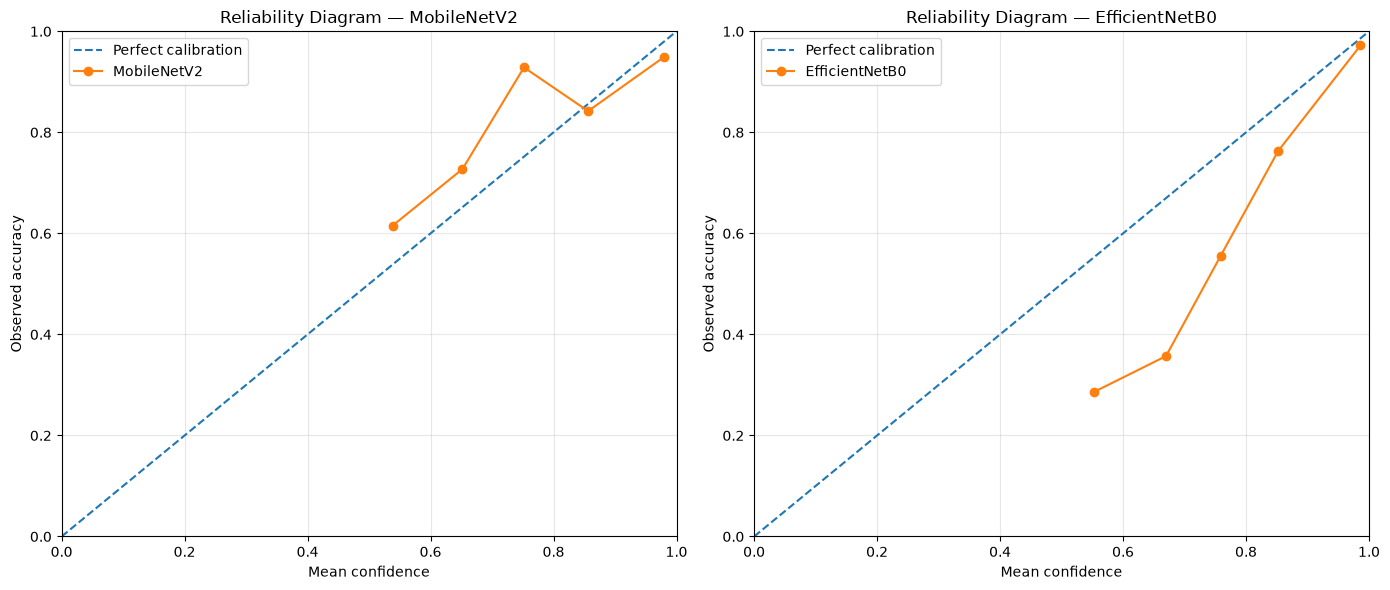

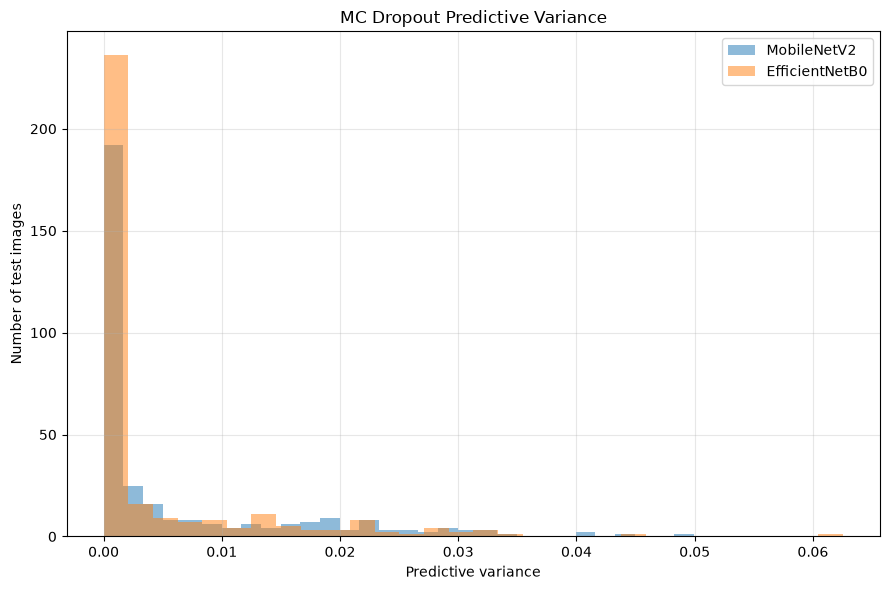


STEP 10 COMPLETED
Output directory: C:\Users\Bhavana BV\Downloads\OncoLens\results\step10_mc_dropout


,model,n_images,mc_passes,accuracy,sensitivity_recall,specificity,roc_auc,ece,brier_score,log_loss,mean_predictive_variance,median_predictive_variance,mean_predictive_std,mean_predictive_entropy_nats
0,MobileNetV2,325,30,0.91385,0.93143,0.89333,0.95882,0.04457,0.07423,0.25188,0.00577,0.00064,0.05054,0.20763
1,EfficientNetB0,325,30,0.88000,0.89714,0.86000,0.96621,0.05184,0.07749,0.24545,0.00405,0.00008,0.03681,0.16718


In [19]:
# =====================================================================
# ONCOLENS — STEP 10
# MONTE CARLO DROPOUT, UNCERTAINTY & CALIBRATION
# MobileNetV2 vs EfficientNetB0
# =====================================================================

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
)

warnings.filterwarnings("ignore", category=FutureWarning)

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")

SPLIT_FILE = ROOT / "split.csv"
INDEX_FILE = ROOT / "results" / "preproc" / "index.csv"
SHARPEN_CACHE_FILE = ROOT / "results" / "preproc" / "sharpen.npy"

MODEL_PATHS = {
    "MobileNetV2": ROOT / "checkpoints" / "mobilenetv2_sharpen.keras",
    "EfficientNetB0": ROOT / "checkpoints" / "efficientnetb0_sharpen.keras",
}

OUTPUT_DIR = ROOT / "results" / "step10_mc_dropout"
PREDICTION_DIR = OUTPUT_DIR / "predictions"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

N_MC_PASSES = 30
BATCH_SIZE = 16
N_CALIBRATION_BINS = 10
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("=" * 75)
print("ONCOLENS — STEP 10: MC DROPOUT AND CALIBRATION")
print("=" * 75)

# =====================================================================
# 2. VALIDATE FILES
# =====================================================================

required_files = [
    SPLIT_FILE,
    INDEX_FILE,
    SHARPEN_CACHE_FILE,
    *MODEL_PATHS.values(),
]

missing_files = [
    str(path) for path in required_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing required files:\n" + "\n".join(missing_files)
    )

# =====================================================================
# 3. LOAD TEST MANIFEST AND PREPROCESSING INDEX
# =====================================================================

split_df = pd.read_csv(SPLIT_FILE)
index_df = pd.read_csv(INDEX_FILE)


def find_column(df, candidates, required=True):
    """Find a column without relying on capitalization."""
    normalized = {
        str(column).strip().lower().replace(" ", "_"): column
        for column in df.columns
    }

    for candidate in candidates:
        key = candidate.strip().lower().replace(" ", "_")

        if key in normalized:
            return normalized[key]

    if required:
        raise ValueError(
            f"Could not find one of {candidates}. "
            f"Available columns: {df.columns.tolist()}"
        )

    return None


def normalize_path(value):
    return str(value).replace("\\", "/").strip().lower()


split_path_col = find_column(
    split_df,
    ["path", "image_path", "filepath", "file_path", "filename"],
)

index_path_col = find_column(
    index_df,
    ["path", "image_path", "filepath", "file_path", "filename"],
)

split_label_col = find_column(
    split_df,
    ["label_id", "label", "class_id", "target", "y"],
)

index_label_col = find_column(
    index_df,
    ["label_id", "label", "class_id", "target", "y"],
)

split_col = find_column(
    split_df,
    ["split", "subset", "partition"],
)

use_col = find_column(
    split_df,
    ["use", "eligible", "include"],
    required=False,
)

# Only the original test split.
test_manifest = split_df[
    split_df[split_col].astype(str).str.strip().str.lower().eq("test")
].copy()

# Exclude the five rows already marked use=False.
if use_col is not None:
    use_values = test_manifest[use_col]

    if use_values.dtype == bool:
        use_mask = use_values
    else:
        use_mask = (
            use_values.astype(str)
            .str.strip()
            .str.lower()
            .isin(["true", "1", "yes"])
        )

    test_manifest = test_manifest[use_mask].copy()

test_manifest["path_key"] = (
    test_manifest[split_path_col].map(normalize_path)
)

index_df = index_df.reset_index(drop=True)
index_df["path_key"] = index_df[index_path_col].map(normalize_path)
index_df["cache_index"] = np.arange(len(index_df))

# Match test images to cache rows.
test_df = test_manifest.merge(
    index_df,
    on="path_key",
    how="inner",
    suffixes=("_manifest", "_index"),
)

if len(test_df) == 0:
    raise ValueError(
        "No test images matched the preprocessing index. "
        "Check the path columns in split.csv and index.csv."
    )

manifest_label_col = f"{split_label_col}_manifest"
index_label_col = f"{index_label_col}_index"

if manifest_label_col not in test_df.columns:
    manifest_label_col = split_label_col

if index_label_col not in test_df.columns:
    index_label_col = index_label_col

test_df["label_id"] = pd.to_numeric(
    test_df[manifest_label_col],
    errors="raise",
).astype(int)

# Check that labels agree between the split manifest and cache index.
if index_label_col in test_df.columns:
    labels_from_index = pd.to_numeric(
        test_df[index_label_col],
        errors="raise",
    ).to_numpy(dtype=int)

    if not np.array_equal(
        test_df["label_id"].to_numpy(dtype=int),
        labels_from_index,
    ):
        raise ValueError(
            "Labels in split.csv and results/preproc/index.csv disagree."
        )

manifest_path_col = f"{split_path_col}_manifest"

if manifest_path_col in test_df.columns:
    test_df["image_path"] = test_df[manifest_path_col].astype(str)
else:
    test_df["image_path"] = test_df[split_path_col].astype(str)

test_df = test_df.reset_index(drop=True)

y_true = test_df["label_id"].to_numpy(dtype=int)

if not np.isin(y_true, [0, 1]).all():
    raise ValueError("Expected labels encoded as 0=non-cancer, 1=cancer.")

if len(test_df) != 325:
    raise ValueError(
        f"Expected 325 eligible test images but matched {len(test_df)}. "
        "Check the manifest/index match before continuing."
    )

print(f"\nEligible test images: {len(test_df)}")
print(
    "Test labels:",
    {
        "non_cancer": int(np.sum(y_true == 0)),
        "cancer": int(np.sum(y_true == 1)),
    },
)

# =====================================================================
# 4. LOAD PREPROCESSED IMAGE CACHE
# =====================================================================

mc_image_cache = np.load(
    SHARPEN_CACHE_FILE,
    mmap_mode="r",
)

if len(mc_image_cache) != len(index_df):
    raise ValueError(
        f"Cache contains {len(mc_image_cache)} images but index contains "
        f"{len(index_df)} rows."
    )

if mc_image_cache.shape[1:] != (224, 224, 3):
    raise ValueError(
        f"Unexpected cache shape: {mc_image_cache.shape}"
    )

print("Cache shape:", mc_image_cache.shape)


def get_image_batch(rows):
    """Load image arrays using their original cache indices."""
    return np.stack([
        np.asarray(
            mc_image_cache[int(row.cache_index)],
            dtype=np.float32,
        )
        for row in rows.itertuples()
    ])


# =====================================================================
# 5. LOAD ORIGINAL TRAINED MODELS
# =====================================================================

models = {}

for model_name, model_path in MODEL_PATHS.items():
    print(f"\nLoading {model_name}...")

    model = tf.keras.models.load_model(
        model_path,
        compile=False,
    )

    models[model_name] = model

    print("Loaded:", model_path.name)
    print("Input shape:", model.input_shape)
    print("Output shape:", model.output_shape)

# =====================================================================
# 6. IDENTIFY DROPOUT AND CLASSIFICATION HEAD
# =====================================================================

def find_top_level_layer(model, layer_name):
    for layer in model.layers:
        if layer.name == layer_name:
            return layer

    raise ValueError(
        f"Layer '{layer_name}' was not found in model '{model.name}'."
    )


def find_head_layers(model):
    """
    Locate the trained Dense -> Dropout -> Dense classification head.
    """
    dropout = find_top_level_layer(model, "head_dropout")

    dropout_index = model.layers.index(dropout)

    if dropout_index == 0 or dropout_index == len(model.layers) - 1:
        raise ValueError(
            f"Unexpected dropout location in {model.name}."
        )

    previous_layers = model.layers[:dropout_index]
    next_layers = model.layers[dropout_index + 1:]

    dense_before = [
        layer for layer in previous_layers
        if isinstance(layer, tf.keras.layers.Dense)
    ]

    dense_after = [
        layer for layer in next_layers
        if isinstance(layer, tf.keras.layers.Dense)
    ]

    if not dense_before or not dense_after:
        raise ValueError(
            f"Could not locate Dense layers around dropout in {model.name}."
        )

    feature_dense = dense_before[-1]
    output_dense = dense_after[0]

    print(f"\n{model.name} classification head:")
    print("Feature Dense:", feature_dense.name)
    print("Dropout:", dropout.name, "rate =", dropout.rate)
    print("Output Dense:", output_dense.name)

    return feature_dense, dropout, output_dense

# =====================================================================
# ONCOLENS — STEP 10 FIX
# MC DROPOUT, UNCERTAINTY AND CALIBRATION
# =====================================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
)

# ---------------------------------------------------------------------
# 7. BUILD FEATURE EXTRACTORS AND DIRECT STOCHASTIC HEADS
# ---------------------------------------------------------------------

N_MC_PASSES = 30
BATCH_SIZE = 16
N_CALIBRATION_BINS = 10

OUTPUT_DIR = ROOT / "results" / "step10_mc_dropout"
PREDICTION_DIR = OUTPUT_DIR / "predictions"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)


def build_mc_components(model):
    """
    Extract features before dropout.

    During MC inference:
      - Feature extractor: inference mode
      - Original Dropout layer: training=True
      - Original output Dense layer: inference mode

    Dropout is invoked directly, not through a wrapper model.
    """

    dropout = model.get_layer("head_dropout")
    feature_dense = model.get_layer("dense")
    output_dense = model.get_layer("dense_1")

    feature_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=feature_dense.output,
        name=f"{model.name}_mc_feature_extractor",
    )

    print(f"\nModel: {model.name}")
    print("Feature layer:", feature_dense.name)
    print("Dropout layer:", dropout.name)
    print("Dropout rate:", dropout.rate)
    print("Output layer:", output_dense.name)

    return feature_model, dropout, output_dense


mc_components = {}

for model_name, model in models.items():
    mc_components[model_name] = build_mc_components(model)


# ---------------------------------------------------------------------
# 8. STOCHASTICITY VALIDATION
# ---------------------------------------------------------------------

print("\n" + "=" * 70)
print("CHECKING MC DROPOUT STOCHASTICITY")
print("=" * 70)

diagnostic_images = get_image_batch(test_df.iloc[:8])

for model_name, model in models.items():

    feature_model, dropout_layer, output_dense = (
        mc_components[model_name]
    )

    # Extract deterministic features once.
    features = feature_model(
        tf.convert_to_tensor(diagnostic_images),
        training=False,
    )

    predictions = []

    # IMPORTANT:
    # Call the original dropout layer directly.
    for _ in range(10):

        dropped_features = dropout_layer(
            features,
            training=True,
        )

        probabilities = output_dense(
            dropped_features,
            training=False,
        )

        predictions.append(
            probabilities[:, 1].numpy()
        )

    predictions = np.stack(predictions, axis=0)

    variance = np.var(predictions, axis=0)

    max_difference = float(
        np.max(
            np.abs(predictions[0] - predictions[-1])
        )
    )

    print(f"\n{model_name}")
    print("Mean variance:", float(variance.mean()))
    print("Maximum variance:", float(variance.max()))
    print("Maximum prediction difference:", max_difference)

    if variance.max() <= 1e-8:
        raise RuntimeError(
            f"{model_name}: MC Dropout is still deterministic. "
            "Do not interpret these predictions as MC uncertainty."
        )

    print("PASS: stochastic predictions detected.")


# ---------------------------------------------------------------------
# 9. CALIBRATION METRICS
# ---------------------------------------------------------------------

def calculate_ece(y_true, cancer_probability, n_bins=10):

    y_true = np.asarray(y_true, dtype=int)
    p = np.asarray(cancer_probability, dtype=float)

    predicted = (p >= 0.5).astype(int)
    confidence = np.maximum(p, 1.0 - p)
    correct = (predicted == y_true).astype(float)

    edges = np.linspace(0.0, 1.0, n_bins + 1)

    ece = 0.0
    rows = []

    for i in range(n_bins):

        lower = edges[i]
        upper = edges[i + 1]

        if i == n_bins - 1:
            mask = (
                (confidence >= lower)
                & (confidence <= upper)
            )
        else:
            mask = (
                (confidence >= lower)
                & (confidence < upper)
            )

        count = int(mask.sum())

        if count == 0:
            rows.append({
                "bin": i + 1,
                "lower": lower,
                "upper": upper,
                "count": 0,
                "mean_confidence": np.nan,
                "observed_accuracy": np.nan,
            })
            continue

        mean_confidence = float(confidence[mask].mean())
        observed_accuracy = float(correct[mask].mean())

        ece += (
            count / len(y_true)
        ) * abs(mean_confidence - observed_accuracy)

        rows.append({
            "bin": i + 1,
            "lower": lower,
            "upper": upper,
            "count": count,
            "mean_confidence": mean_confidence,
            "observed_accuracy": observed_accuracy,
        })

    return float(ece), pd.DataFrame(rows)


def predictive_entropy(probability):

    p = np.clip(
        np.asarray(probability, dtype=float),
        1e-7,
        1.0 - 1e-7,
    )

    return -(
        p * np.log(p)
        + (1.0 - p) * np.log(1.0 - p)
    )


# ---------------------------------------------------------------------
# 10. RUN MONTE CARLO PREDICTIONS
# ---------------------------------------------------------------------

metric_rows = []
reliability_results = {}

for model_name, model in models.items():

    print("\n" + "=" * 70)
    print("MC DROPOUT:", model_name)
    print("=" * 70)

    feature_model, dropout_layer, output_dense = (
        mc_components[model_name]
    )

    # Compute deterministic features for all test images.
    feature_batches = []

    for start in range(0, len(test_df), BATCH_SIZE):

        batch_df = test_df.iloc[
            start:start + BATCH_SIZE
        ]

        images = get_image_batch(batch_df)

        features = feature_model(
            tf.convert_to_tensor(images),
            training=False,
        )

        feature_batches.append(features)

    # Repeat stochastic classification 30 times.
    mc_passes = []

    for pass_number in range(N_MC_PASSES):

        pass_predictions = []

        for features in feature_batches:

            # Direct call guarantees explicit dropout activation.
            dropped_features = dropout_layer(
                features,
                training=True,
            )

            outputs = output_dense(
                dropped_features,
                training=False,
            )

            pass_predictions.append(
                outputs[:, 1].numpy()
            )

        pass_predictions = np.concatenate(
            pass_predictions
        )

        mc_passes.append(pass_predictions)

        if (pass_number + 1) % 5 == 0:
            print(
                f"Completed {pass_number + 1}/"
                f"{N_MC_PASSES} passes"
            )

    # Shape: (30 passes, 325 images)
    mc_probabilities = np.stack(
        mc_passes,
        axis=0,
    )

    # Predictive statistics.
    mean_probability = mc_probabilities.mean(axis=0)

    predictive_variance = mc_probabilities.var(axis=0)

    predictive_std = np.sqrt(
        predictive_variance
    )

    predicted_label = (
        mean_probability >= 0.5
    ).astype(int)

    confidence = np.maximum(
        mean_probability,
        1.0 - mean_probability,
    )

    entropy = predictive_entropy(
        mean_probability
    )

    # Verify full evaluation remains stochastic.
    if np.max(predictive_variance) <= 1e-8:
        raise RuntimeError(
            f"{model_name}: predictive variance is effectively zero. "
            "Results will not be saved as MC Dropout estimates."
        )

    # Calibration.
    ece, reliability_df = calculate_ece(
        y_true,
        mean_probability,
        N_CALIBRATION_BINS,
    )

    # Evaluation metrics.
    accuracy = accuracy_score(
        y_true,
        predicted_label,
    )

    roc_auc = roc_auc_score(
        y_true,
        mean_probability,
    )

    brier = brier_score_loss(
        y_true,
        mean_probability,
    )

    clipped_probability = np.clip(
        mean_probability,
        1e-7,
        1.0 - 1e-7,
    )

    binary_log_loss = log_loss(
        y_true,
        clipped_probability,
        labels=[0, 1],
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predicted_label,
        labels=[0, 1],
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if tp + fn else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if tn + fp else np.nan
    )

    # Consistent output filenames.
    model_key = (
        model_name.lower()
        .replace(" ", "")
        .replace("-", "")
    )

    # Save per-image predictions.
    prediction_df = pd.DataFrame({
        "path": test_df["image_path"].to_numpy(),
        "true_label": y_true,
        "mean_probability_cancer": mean_probability,
        "predictive_variance": predictive_variance,
        "predictive_std": predictive_std,
        "predictive_entropy_nats": entropy,
        "confidence": confidence,
        "predicted_label": predicted_label,
        "correct": predicted_label == y_true,
    })

    prediction_df.to_csv(
        PREDICTION_DIR
        / f"{model_key}_mc_predictions.csv",
        index=False,
    )

    np.save(
        PREDICTION_DIR
        / f"{model_key}_mc_cancer_probabilities.npy",
        mc_probabilities,
    )

    reliability_df.to_csv(
        PREDICTION_DIR
        / f"{model_key}_reliability_bins.csv",
        index=False,
    )

    reliability_results[model_name] = reliability_df

    metric_rows.append({
        "model": model_name,
        "n_images": len(y_true),
        "mc_passes": N_MC_PASSES,
        "accuracy": accuracy,
        "sensitivity_recall": sensitivity,
        "specificity": specificity,
        "roc_auc": roc_auc,
        "ece": ece,
        "brier_score": brier,
        "log_loss": binary_log_loss,
        "mean_predictive_variance": float(
            predictive_variance.mean()
        ),
        "median_predictive_variance": float(
            np.median(predictive_variance)
        ),
        "mean_predictive_std": float(
            predictive_std.mean()
        ),
        "mean_predictive_entropy_nats": float(
            entropy.mean()
        ),
    })

    print(f"\nAccuracy: {accuracy:.4f}")
    print(f"Sensitivity: {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}")
    print(f"ECE: {ece:.4f}")
    print(f"Brier score: {brier:.4f}")
    print(f"Log loss: {binary_log_loss:.4f}")
    print(
        "Mean predictive variance:",
        f"{predictive_variance.mean():.8f}",
    )


# ---------------------------------------------------------------------
# 11. SAVE METRICS
# ---------------------------------------------------------------------

metrics_df = pd.DataFrame(metric_rows)

metrics_df.to_csv(
    OUTPUT_DIR / "mc_dropout_calibration_metrics.csv",
    index=False,
)

print("\n" + "=" * 70)
print("STEP 10 METRICS")
print("=" * 70)

print(metrics_df.round(5).to_string(index=False))


# ---------------------------------------------------------------------
# 12. RELIABILITY DIAGRAM
# ---------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    len(reliability_results),
    figsize=(7 * len(reliability_results), 6),
)

if len(reliability_results) == 1:
    axes = [axes]

for ax, (model_name, rel_df) in zip(
    axes,
    reliability_results.items(),
):

    valid = rel_df[rel_df["count"] > 0]

    ax.plot(
        [0, 1],
        [0, 1],
        "--",
        label="Perfect calibration",
    )

    ax.plot(
        valid["mean_confidence"],
        valid["observed_accuracy"],
        marker="o",
        label=model_name,
    )

    ax.set_title(f"Reliability Diagram — {model_name}")
    ax.set_xlabel("Mean confidence")
    ax.set_ylabel("Observed accuracy")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "reliability_diagrams.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# ---------------------------------------------------------------------
# 13. PREDICTIVE VARIANCE DISTRIBUTION
# ---------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

for model_name in models:

    model_key = (
        model_name.lower()
        .replace(" ", "")
        .replace("-", "")
    )

    pred_df = pd.read_csv(
        PREDICTION_DIR
        / f"{model_key}_mc_predictions.csv"
    )

    ax.hist(
        pred_df["predictive_variance"],
        bins=30,
        alpha=0.5,
        label=model_name,
    )

ax.set_xlabel("Predictive variance")
ax.set_ylabel("Number of test images")
ax.set_title("MC Dropout Predictive Variance")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "predictive_variance_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# ---------------------------------------------------------------------
# 14. SAVE METADATA
# ---------------------------------------------------------------------

metadata = {
    "project": "OncoLens",
    "step": 10,
    "test_images": int(len(test_df)),
    "mc_passes": N_MC_PASSES,
    "batch_size": BATCH_SIZE,
    "calibration_bins": N_CALIBRATION_BINS,
    "class_encoding": {
        "0": "Non-cancer",
        "1": "Cancer",
    },
    "method": (
        "Direct stochastic calls to the original trained dropout "
        "layer, with feature extraction in inference mode."
    ),
    "calibration_note": (
        "ECE, Brier score and log loss are descriptive test-set "
        "metrics. No calibration parameters were fitted on the test set."
    ),
}

with open(
    OUTPUT_DIR / "mc_dropout_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(metadata, file, indent=4)

print("\n" + "=" * 70)
print("STEP 10 COMPLETED")
print("=" * 70)
print("Output directory:", OUTPUT_DIR)

display(metrics_df.round(5))

In [17]:
# ================================================================
# ONCOLENS — STEP 10: CORRECTED MC DROPOUT INFERENCE
# ================================================================

import numpy as np
import tensorflow as tf

print("=" * 70)
print("ONCOLENS — CORRECTED MC DROPOUT INFERENCE")
print("=" * 70)


def build_mc_model_from_original_graph(model):
    """
    Reuse the original Functional model's graph.

    The original dropout layer is called again with training=True.
    This preserves the trained weights and the original layer ordering.
    """

    dropout = next(
        (
            layer for layer in model.layers
            if layer.name == "head_dropout"
        ),
        None,
    )

    if dropout is None:
        raise ValueError(
            f"No top-level head_dropout in {model.name}"
        )

    # The original Dense(128) layer feeds into dropout.
    dense_layer = model.get_layer("dense")

    # Build a feature extractor using the original graph.
    feature_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=dense_layer.output,
        name=f"{model.name}_mc_features",
    )

    # Reuse the trained final classification layer.
    final_dense = model.layers[-1]

    if not isinstance(final_dense, tf.keras.layers.Dense):
        raise ValueError(
            "Expected the final layer to be Dense."
        )

    # Create an independent input for the trained 128-unit features.
    feature_input = tf.keras.Input(
        shape=tuple(dense_layer.output.shape[1:]),
        name=f"{model.name}_mc_feature_input",
    )

    # Activate the original dropout layer on these features.
    x = dropout(feature_input, training=True)

    # Use the original trained output-layer weights.
    output = final_dense(x)

    stochastic_head = tf.keras.Model(
        inputs=feature_input,
        outputs=output,
        name=f"{model.name}_mc_stochastic_head",
    )

    return feature_model, stochastic_head


mc_feature_models = {}
mc_heads = {}

for model_name, model in models.items():

    feature_model, stochastic_head = (
        build_mc_model_from_original_graph(model)
    )

    mc_feature_models[model_name] = feature_model
    mc_heads[model_name] = stochastic_head

    print(f"{model_name}: stochastic head constructed.")


# ================================================================
# CHECK THAT THE FULL CLASSIFICATION PATH IS STOCHASTIC
# ================================================================

sample_df = test_df.iloc[:8]

sample_images = np.stack([
    np.asarray(
        mc_image_cache[int(row.cache_index)],
        dtype=np.float32
    )
    for row in sample_df.itertuples()
])

for model_name in models:

    feature_model = mc_feature_models[model_name]
    stochastic_head = mc_heads[model_name]

    # Compute deterministic features only once.
    features = feature_model(
        tf.convert_to_tensor(sample_images),
        training=False,
    )

    repeated_predictions = []

    for _ in range(10):
        output = stochastic_head(
            features,
            training=False,
        ).numpy()

        # Convert logits/probabilities to probabilities if needed.
        # The original model's output is softmax, so final_dense already
        # uses its original activation.
        repeated_predictions.append(output[:, 1])

    repeated_predictions = np.stack(
        repeated_predictions,
        axis=0,
    )

    variance = np.var(
        repeated_predictions,
        axis=0,
    )

    max_difference = np.max(
        np.abs(
            repeated_predictions[0]
            - repeated_predictions[-1]
        )
    )

    print(f"\n{model_name}")
    print("Mean variance:", float(variance.mean()))
    print("Maximum variance:", float(variance.max()))
    print("Maximum prediction difference:", float(max_difference))

    if variance.max() > 1e-8 and max_difference > 1e-8:
        print("PASS: stochastic classification predictions confirmed.")
    else:
        print("FAIL: stochastic classification predictions not confirmed.")

ONCOLENS — CORRECTED MC DROPOUT INFERENCE
MobileNetV2: stochastic head constructed.
EfficientNetB0: stochastic head constructed.

MobileNetV2
Mean variance: 3.1086244689504383e-15
Maximum variance: 1.4210854715202004e-14
Maximum prediction difference: 0.0
FAIL: stochastic classification predictions not confirmed.

EfficientNetB0
Mean variance: 4.884981308350689e-15
Maximum variance: 1.4210854715202004e-14
Maximum prediction difference: 0.0
FAIL: stochastic classification predictions not confirmed.


In [22]:
for name, path in MODELS.items():
    model = tf.keras.models.load_model(path, compile=False)

    print(f"\n{'=' * 60}")
    print(name)
    print("Input:", model.input_shape, model.inputs[0].dtype)

    for layer in model.layers[:8]:
        print(
            layer.name,
            type(layer).__name__,
            getattr(layer, "scale", ""),
            getattr(layer, "offset", ""),
        )


MobileNetV2
Input: (None, 224, 224, 3) uint8
input_layer_1 InputLayer  
to_float Rescaling 1.0 0.0
random_flip RandomFlip  
random_rotation RandomRotation  
random_zoom RandomZoom  
random_brightness RandomBrightness  
scale Rescaling 0.00784313725490196 -1.0
mobilenetv2_1.00_224 Functional  

EfficientNetB0
Input: (None, 224, 224, 3) uint8
input_layer_1 InputLayer  
to_float Rescaling 1.0 0.0
random_flip RandomFlip  
random_rotation RandomRotation  
random_zoom RandomZoom  
random_brightness RandomBrightness  
scale Rescaling 1.0 0.0
efficientnetb0 Functional  


ONCOLENS — STEP 11: TFLITE FLOAT16 BENCHMARK
Test images: 325
Non-cancer: 150
Cancer: 175
Input array: (325, 224, 224, 3) uint8

Loading MobileNetV2...
Input: (None, 224, 224, 3)
Input dtype: uint8
Output: (None, 2)
Preprocessing layers:
  input_layer_1 InputLayer
  to_float Rescaling
  random_flip RandomFlip
  random_rotation RandomRotation
  random_zoom RandomZoom
  random_brightness RandomBrightness
  scale Rescaling
  mobilenetv2_1.00_224 Functional
Reference predictions generated.

Loading EfficientNetB0...
Input: (None, 224, 224, 3)
Input dtype: uint8
Output: (None, 2)
Preprocessing layers:
  input_layer_1 InputLayer
  to_float Rescaling
  random_flip RandomFlip
  random_rotation RandomRotation
  random_zoom RandomZoom
  random_brightness RandomBrightness
  scale Rescaling
  efficientnetb0 Functional
Reference predictions generated.

Converting MobileNetV2...
INFO:tensorflow:Assets written to: C:\Users\BHAVAN~1\AppData\Local\Temp\tmp3889v1jg\assets


INFO:tensorflow:Assets written to: C:\Users\BHAVAN~1\AppData\Local\Temp\tmp3889v1jg\assets


Saved artifact at 'C:\Users\BHAVAN~1\AppData\Local\Temp\tmp3889v1jg'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  1407118569744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1407118570704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1407118570512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1407118570128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1407118571280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1407118569168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1407118570896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1407118571088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1407118568400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1407118572240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140

INFO:tensorflow:Assets written to: C:\Users\BHAVAN~1\AppData\Local\Temp\tmpqzln427j\assets


Saved artifact at 'C:\Users\BHAVAN~1\AppData\Local\Temp\tmpqzln427j'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  1398255970512: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  1398255970704: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  1398092660368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1398092659600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1398083749072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1398092658640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1398092659984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1398083748688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1398083748880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1398083748304: TensorSpec(shape=(), dtype=tf.resource

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Accuracy: 0.9046
Sensitivity: 0.9086
Specificity: 0.9000
ROC-AUC: 0.9589
Median latency: 7.480 ms
P95 latency: 9.412 ms
Keras/TFLite prediction agreement: 0.9877
Probability MAE: 0.00199450
Maximum probability difference: 0.02833736

BENCHMARKING: EfficientNetB0
TFLite input dtype: <class 'numpy.uint8'>
TFLite input shape: [  1 224 224   3]
TFLite output dtype: <class 'numpy.float32'>


c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Accuracy: 0.8769
Sensitivity: 0.8971
Specificity: 0.8533
ROC-AUC: 0.9664
Median latency: 14.580 ms
P95 latency: 16.541 ms
Keras/TFLite prediction agreement: 1.0000
Probability MAE: 0.00069629
Maximum probability difference: 0.00721309

MODEL SIZE AND LATENCY
         model  keras_size_MB  tflite_float16_size_MB  size_reduction_percent  median_latency_ms  p95_latency_ms  mean_latency_ms  threads
   MobileNetV2       22.61182                 4.60925                79.61576             7.4797         9.41210          7.86027        1
EfficientNetB0       29.48650                 8.06089                72.66244            14.5798        16.54096         14.71220        1

TEST METRICS AND PREDICTION AGREEMENT
         model  threshold  accuracy  precision  sensitivity_recall  specificity  f1_score  roc_auc  keras_accuracy  keras_roc_auc  prediction_agreement  probability_MAE  probability_max_difference  tn  fp  fn  tp
   MobileNetV2        0.5   0.90462    0.91379             0.90857      

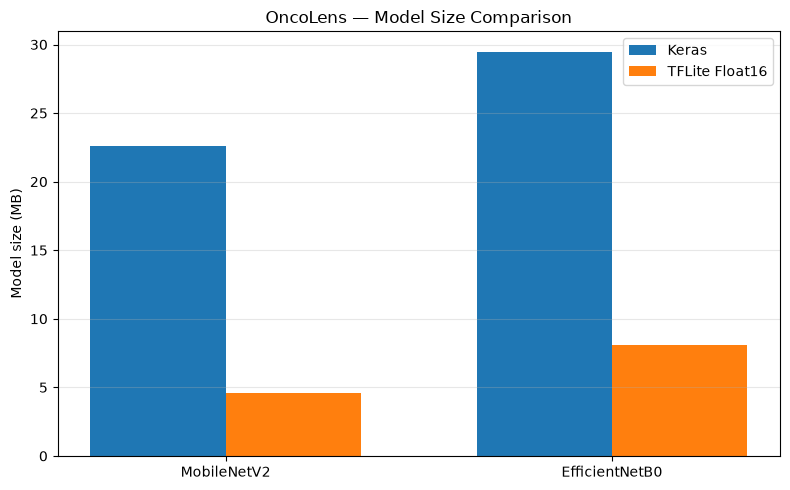

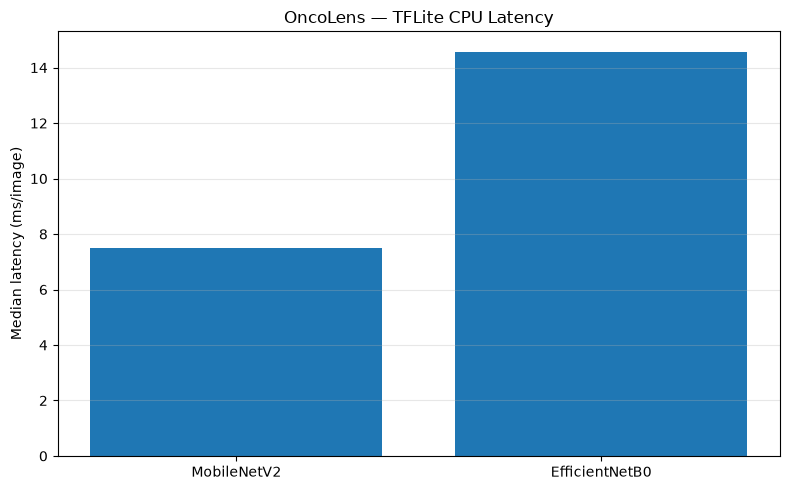

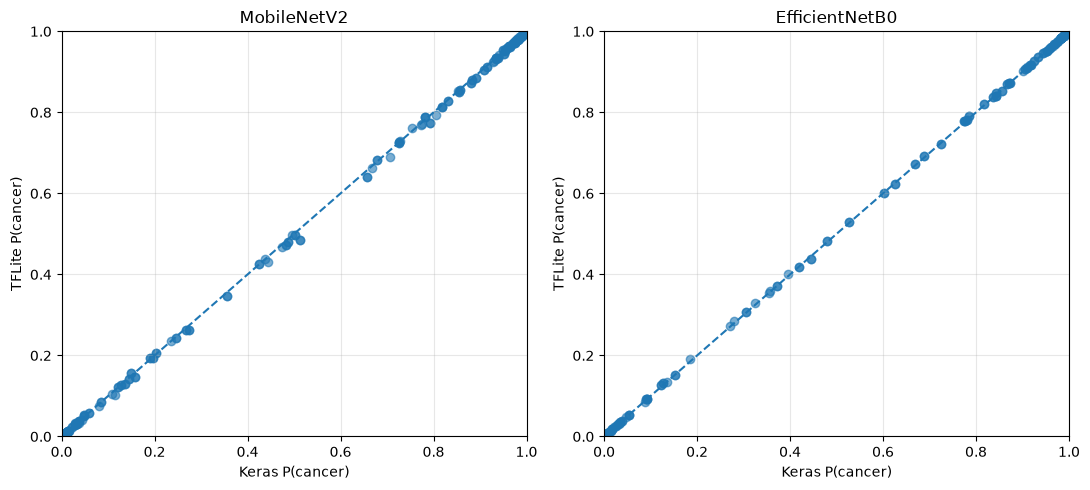


ONCOLENS STEP 11 COMPLETED
Output directory: C:\Users\Bhavana BV\Downloads\OncoLens\results\step11_tflite

Generated files:
  figures\agreement.png
  figures\latency.png
  figures\model_size.png
  models\efficientnetb0_float16.tflite
  models\mobilenetv2_float16.tflite
  predictions\efficientnetb0_keras_vs_tflite.csv
  predictions\mobilenetv2_keras_vs_tflite.csv
  tflite_accuracy_comparison.csv
  tflite_metadata.json
  tflite_size_latency.csv


,model,keras_size_MB,tflite_float16_size_MB,size_reduction_percent,median_latency_ms,p95_latency_ms,mean_latency_ms,threads
0,MobileNetV2,22.61182,4.60925,79.61576,7.4797,9.41210,7.86027,1
1,EfficientNetB0,29.48650,8.06089,72.66244,14.5798,16.54096,14.71220,1


,model,threshold,accuracy,precision,sensitivity_recall,specificity,f1_score,roc_auc,keras_accuracy,keras_roc_auc,prediction_agreement,probability_MAE,probability_max_difference,tn,fp,fn,tp
0,MobileNetV2,0.5,0.90462,0.91379,0.90857,0.90000,0.91117,0.95893,0.90462,0.95962,0.98769,0.00199,0.02834,135,15,16,159
1,EfficientNetB0,0.5,0.87692,0.87709,0.89714,0.85333,0.88701,0.96644,0.87692,0.96651,1.00000,0.00070,0.00721,128,22,18,157


In [23]:
# =====================================================================
# ONCOLENS STEP 11
# TFLITE FLOAT16 CONVERSION + CPU BENCHMARK
# MobileNetV2 vs EfficientNetB0
# =====================================================================

from pathlib import Path
import json
import time
import gc
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

warnings.filterwarnings("ignore", category=FutureWarning)

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")

WIN = "sharpen"
THRESHOLD = 0.5

WARMUP = 10
RUNS_LAT = 50
BATCH_SIZE = 32

MODEL_PATHS = {
    "MobileNetV2": ROOT / "checkpoints" / "mobilenetv2_sharpen.keras",
    "EfficientNetB0": ROOT / "checkpoints" / "efficientnetb0_sharpen.keras",
}

SPLIT_FILE = ROOT / "split.csv"
INDEX_FILE = ROOT / "results" / "preproc" / "index.csv"
CACHE_FILE = ROOT / "results" / "preproc" / f"{WIN}.npy"

OUT = ROOT / "results" / "step11_tflite"
MODEL_OUT = OUT / "models"
PRED_OUT = OUT / "predictions"
FIG_OUT = OUT / "figures"

for directory in [MODEL_OUT, PRED_OUT, FIG_OUT]:
    directory.mkdir(parents=True, exist_ok=True)

for path in [SPLIT_FILE, INDEX_FILE, CACHE_FILE, *MODEL_PATHS.values()]:
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

print("=" * 75)
print("ONCOLENS — STEP 11: TFLITE FLOAT16 BENCHMARK")
print("=" * 75)

# =====================================================================
# 2. LOAD TEST SET
# =====================================================================

split = pd.read_csv(SPLIT_FILE)
index = pd.read_csv(INDEX_FILE)

if "use" in split.columns:
    use_values = split["use"]

    if use_values.dtype == bool:
        split = split[use_values].copy()
    else:
        split = split[
            use_values.astype(str).str.lower().isin(["true", "1", "yes"])
        ].copy()

test_manifest = split.loc[
    split["split"].astype(str).str.lower().eq("test"),
    ["path", "label_id"],
].copy()

index["cache_index"] = np.arange(len(index))

test_df = test_manifest.merge(
    index[["path", "y", "cache_index"]],
    on="path",
    how="inner",
).reset_index(drop=True)

if len(test_df) != 325:
    raise ValueError(
        f"Expected 325 eligible test images, found {len(test_df)}."
    )

if not np.array_equal(
    test_df["label_id"].to_numpy(dtype=int),
    test_df["y"].to_numpy(dtype=int),
):
    raise ValueError("Test labels do not match between split.csv and index.csv.")

y_true = test_df["y"].to_numpy(dtype=int)

if not np.isin(y_true, [0, 1]).all():
    raise ValueError("Expected labels 0=non-cancer, 1=cancer.")

cache = np.load(CACHE_FILE, mmap_mode="r")

if len(cache) != len(index):
    raise ValueError("Image cache and index lengths do not match.")

X = np.stack([
    np.asarray(cache[int(i)], dtype=np.uint8)
    for i in test_df["cache_index"]
])

print("Test images:", len(X))
print("Non-cancer:", int(np.sum(y_true == 0)))
print("Cancer:", int(np.sum(y_true == 1)))
print("Input array:", X.shape, X.dtype)

# =====================================================================
# 3. LOAD MODELS AND GET REFERENCE PREDICTIONS
# =====================================================================

keras_models = {}
keras_probs = {}

for name, path in MODEL_PATHS.items():

    print(f"\nLoading {name}...")

    model = tf.keras.models.load_model(
        path,
        compile=False,
    )

    print("Input:", model.input_shape)
    print("Input dtype:", model.inputs[0].dtype)
    print("Output:", model.output_shape)

    # Inspect preprocessing layers.
    print("Preprocessing layers:")

    for layer in model.layers[:8]:
        print(" ", layer.name, type(layer).__name__)

    # Generate reference predictions using the original model.
    predictions = model.predict(
        X,
        batch_size=BATCH_SIZE,
        verbose=0,
    )

    if predictions.shape != (len(X), 2):
        raise ValueError(
            f"{name} produced unexpected output shape {predictions.shape}."
        )

    if not np.isfinite(predictions).all():
        raise ValueError(f"{name} produced non-finite predictions.")

    keras_probs[name] = predictions[:, 1]
    keras_models[name] = model

    print("Reference predictions generated.")

# =====================================================================
# 4. CONVERT MODELS TO TFLITE FLOAT16
# =====================================================================

tflite_paths = {}
conversion_metadata = {}


def convert_float16(model):
    """
    Convert the complete original model to float16-weight TFLite.
    The trained preprocessing layers remain in the conversion graph.
    """

    converter = tf.lite.TFLiteConverter.from_keras_model(model)

    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.target_spec.supported_types = [tf.float16]

    return converter.convert()


for name, model in keras_models.items():

    print(f"\nConverting {name}...")

    blob = convert_float16(model)

    path = MODEL_OUT / f"{name.lower()}_float16.tflite"
    path.write_bytes(blob)

    tflite_paths[name] = path

    conversion_metadata[name] = {
        "conversion": "float16 weight quantization",
        "converted_directly_from_original_model": True,
        "model_bytes": int(path.stat().st_size),
    }

    print("Saved:", path.name)
    print("Size:", round(path.stat().st_size / 1024**2, 3), "MB")

# =====================================================================
# 5. TFLITE INTERPRETER
# =====================================================================

def create_interpreter(path):

    interpreter = tf.lite.Interpreter(
        model_path=str(path),
        num_threads=1,
    )

    interpreter.allocate_tensors()

    inputs = interpreter.get_input_details()
    outputs = interpreter.get_output_details()

    if len(inputs) != 1 or len(outputs) != 1:
        raise ValueError("Unexpected number of model input/output tensors.")

    print("TFLite input dtype:", inputs[0]["dtype"])
    print("TFLite input shape:", inputs[0]["shape"])
    print("TFLite output dtype:", outputs[0]["dtype"])

    return interpreter, inputs[0], outputs[0]


def run_tflite(interpreter, input_detail, output_detail, image_batch):

    input_dtype = input_detail["dtype"]

    # The converted models are expected to accept uint8 pixel values,
    # preserving the original model's uint8 input signature.
    if np.issubdtype(input_dtype, np.integer):

        scale, zero_point = input_detail["quantization"]

        if scale > 0:
            input_data = np.round(
                image_batch.astype(np.float32) / scale + zero_point
            )

            limits = np.iinfo(input_dtype)

            input_data = np.clip(
                input_data,
                limits.min,
                limits.max,
            ).astype(input_dtype)

        elif input_dtype == np.uint8:
            input_data = image_batch.astype(np.uint8)

        else:
            raise ValueError(
                "Integer TFLite input has no valid quantization scale."
            )

    else:
        input_data = image_batch.astype(input_dtype)

    # Handle dynamic batch dimensions safely.
    current_shape = tuple(
        interpreter.get_input_details()[0]["shape"]
    )

    if current_shape != tuple(input_data.shape):

        interpreter.resize_tensor_input(
            input_detail["index"],
            input_data.shape,
            strict=False,
        )

        interpreter.allocate_tensors()

        input_detail = interpreter.get_input_details()[0]
        output_detail = interpreter.get_output_details()[0]

    interpreter.set_tensor(
        input_detail["index"],
        input_data,
    )

    interpreter.invoke()

    result = interpreter.get_tensor(
        output_detail["index"]
    )

    return result


# =====================================================================
# 6. TFLITE INFERENCE AND KERAS EQUIVALENCE CHECK
# =====================================================================

tflite_probs = {}
latency_rows = []
metric_rows = []

for name, path in tflite_paths.items():

    print("\n" + "=" * 75)
    print("BENCHMARKING:", name)
    print("=" * 75)

    interpreter, input_detail, output_detail = create_interpreter(path)

    # Warm-up.
    for _ in range(WARMUP):
        run_tflite(
            interpreter,
            input_detail,
            output_detail,
            X[:1],
        )

    probabilities = []
    single_image_latencies = []

    # Predict each test image individually.
    for image in X:

        start = time.perf_counter()

        output = run_tflite(
            interpreter,
            input_detail,
            output_detail,
            image[None, ...],
        )

        elapsed_ms = (time.perf_counter() - start) * 1000

        single_image_latencies.append(elapsed_ms)
        probabilities.append(float(output[0, 1]))

    probabilities = np.asarray(probabilities, dtype=float)
    tflite_probs[name] = probabilities

    if not np.isfinite(probabilities).all():
        raise ValueError(f"{name}: non-finite TFLite probabilities.")

    # -------------------------------------------------------------
    # Keras vs TFLite comparison
    # -------------------------------------------------------------

    original_probs = keras_probs[name]

    probability_mae = float(
        np.mean(np.abs(original_probs - probabilities))
    )

    probability_max_diff = float(
        np.max(np.abs(original_probs - probabilities))
    )

    keras_pred = (original_probs >= THRESHOLD).astype(int)
    tflite_pred = (probabilities >= THRESHOLD).astype(int)

    agreement = float(
        np.mean(keras_pred == tflite_pred)
    )

    # -------------------------------------------------------------
    # TFLite test metrics
    # -------------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        tflite_pred,
        labels=[0, 1],
    ).ravel()

    accuracy = accuracy_score(y_true, tflite_pred)

    precision = precision_score(
        y_true,
        tflite_pred,
        zero_division=0,
    )

    recall = recall_score(
        y_true,
        tflite_pred,
        zero_division=0,
    )

    specificity = tn / (tn + fp) if tn + fp else np.nan

    f1 = f1_score(
        y_true,
        tflite_pred,
        zero_division=0,
    )

    auc = roc_auc_score(
        y_true,
        probabilities,
    )

    # -------------------------------------------------------------
    # Size and latency
    # -------------------------------------------------------------

    keras_size = MODEL_PATHS[name].stat().st_size
    tflite_size = path.stat().st_size

    median_latency = float(np.median(single_image_latencies))
    p95_latency = float(np.percentile(single_image_latencies, 95))

    latency_rows.append({
        "model": name,
        "keras_size_MB": keras_size / 1024**2,
        "tflite_float16_size_MB": tflite_size / 1024**2,
        "size_reduction_percent": (
            (keras_size - tflite_size) / keras_size * 100
        ),
        "median_latency_ms": median_latency,
        "p95_latency_ms": p95_latency,
        "mean_latency_ms": float(np.mean(single_image_latencies)),
        "threads": 1,
    })

    metric_rows.append({
        "model": name,
        "threshold": THRESHOLD,
        "accuracy": accuracy,
        "precision": precision,
        "sensitivity_recall": recall,
        "specificity": specificity,
        "f1_score": f1,
        "roc_auc": auc,
        "keras_accuracy": accuracy_score(y_true, keras_pred),
        "keras_roc_auc": roc_auc_score(y_true, original_probs),
        "prediction_agreement": agreement,
        "probability_MAE": probability_mae,
        "probability_max_difference": probability_max_diff,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    })

    # Save per-image predictions.
    pd.DataFrame({
        "path": test_df["path"],
        "true_label": y_true,
        "keras_probability_cancer": original_probs,
        "tflite_probability_cancer": probabilities,
        "keras_prediction": keras_pred,
        "tflite_prediction": tflite_pred,
        "absolute_probability_difference": np.abs(
            original_probs - probabilities
        ),
    }).to_csv(
        PRED_OUT / f"{name.lower()}_keras_vs_tflite.csv",
        index=False,
    )

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Sensitivity: {recall:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"ROC-AUC: {auc:.4f}")
    print(f"Median latency: {median_latency:.3f} ms")
    print(f"P95 latency: {p95_latency:.3f} ms")
    print(f"Keras/TFLite prediction agreement: {agreement:.4f}")
    print(f"Probability MAE: {probability_mae:.8f}")
    print(f"Maximum probability difference: {probability_max_diff:.8f}")

    del interpreter
    gc.collect()

# =====================================================================
# 7. SAVE TABLES
# =====================================================================

size_df = pd.DataFrame(latency_rows)
metric_df = pd.DataFrame(metric_rows)

size_df.to_csv(
    OUT / "tflite_size_latency.csv",
    index=False,
)

metric_df.to_csv(
    OUT / "tflite_accuracy_comparison.csv",
    index=False,
)

print("\n" + "=" * 75)
print("MODEL SIZE AND LATENCY")
print("=" * 75)

print(size_df.round(5).to_string(index=False))

print("\n" + "=" * 75)
print("TEST METRICS AND PREDICTION AGREEMENT")
print("=" * 75)

print(metric_df.round(5).to_string(index=False))

# =====================================================================
# 8. MODEL SIZE FIGURE
# =====================================================================

positions = np.arange(len(size_df))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    positions - width / 2,
    size_df["keras_size_MB"],
    width,
    label="Keras",
)

ax.bar(
    positions + width / 2,
    size_df["tflite_float16_size_MB"],
    width,
    label="TFLite Float16",
)

ax.set_xticks(positions)
ax.set_xticklabels(size_df["model"])
ax.set_ylabel("Model size (MB)")
ax.set_title("OncoLens — Model Size Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(FIG_OUT / "model_size.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# =====================================================================
# 9. LATENCY FIGURE
# =====================================================================

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    size_df["model"],
    size_df["median_latency_ms"],
)

ax.set_ylabel("Median latency (ms/image)")
ax.set_title("OncoLens — TFLite CPU Latency")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(FIG_OUT / "latency.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# =====================================================================
# 10. KERAS VS TFLITE PROBABILITY AGREEMENT
# =====================================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, name in zip(axes, MODEL_PATHS):

    ax.scatter(
        keras_probs[name],
        tflite_probs[name],
        alpha=0.6,
    )

    ax.plot([0, 1], [0, 1], "--")

    ax.set_title(name)
    ax.set_xlabel("Keras P(cancer)")
    ax.set_ylabel("TFLite P(cancer)")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(FIG_OUT / "agreement.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# =====================================================================
# 11. SAVE METADATA
# =====================================================================

metadata = {
    "project": "OncoLens",
    "step": 11,
    "conversion": "TensorFlow Lite float16 weight quantization",
    "preprocessing": WIN,
    "threshold": THRESHOLD,
    "test_images": int(len(X)),
    "threads": 1,
    "warmup_runs": WARMUP,
    "latency_measurements_per_model": int(len(X)),
    "note": (
        "Latency depends on CPU, TensorFlow Lite runtime, and system load. "
        "Float16 weights do not guarantee faster CPU inference."
    ),
    "models": conversion_metadata,
}

with open(
    OUT / "tflite_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(metadata, file, indent=4)

# =====================================================================
# 12. COMPLETION
# =====================================================================

print("\n" + "=" * 75)
print("ONCOLENS STEP 11 COMPLETED")
print("=" * 75)
print("Output directory:", OUT)

print("\nGenerated files:")

for file in sorted(OUT.rglob("*")):
    if file.is_file():
        print(" ", file.relative_to(OUT))

display(size_df.round(5))
display(metric_df.round(5))

ONCOLENS — STEP 11.1: CONVERSION VERIFICATION

TEST SET
--------------------------------------------------
Images: 325
Non-cancer: 150
Cancer: 175
Image shape: (325, 224, 224, 3)

Loading original MobileNetV2...
Keras predictions generated.

Loading TFLite model...
Input shape: [  1 224 224   3]
Input dtype: <class 'numpy.uint8'>
Output shape: [1 2]
Output dtype: <class 'numpy.float32'>

Generating TFLite predictions...


c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite predictions generated.


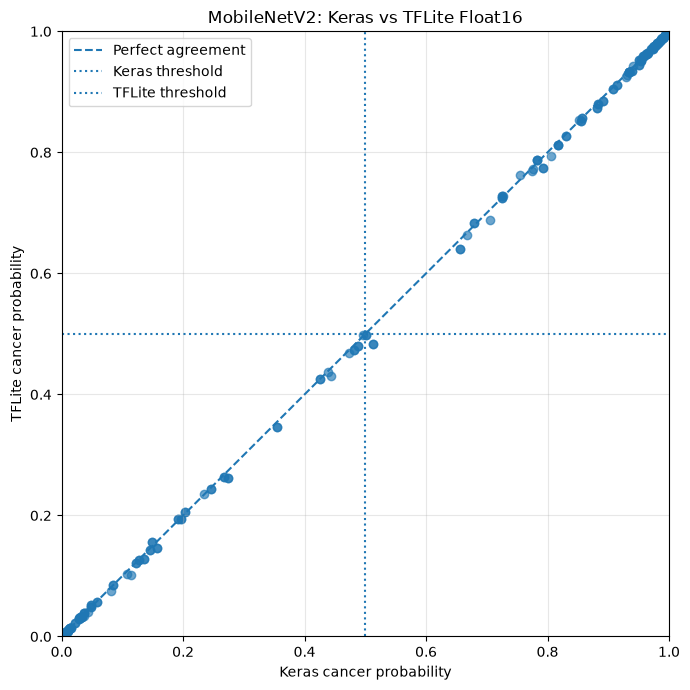

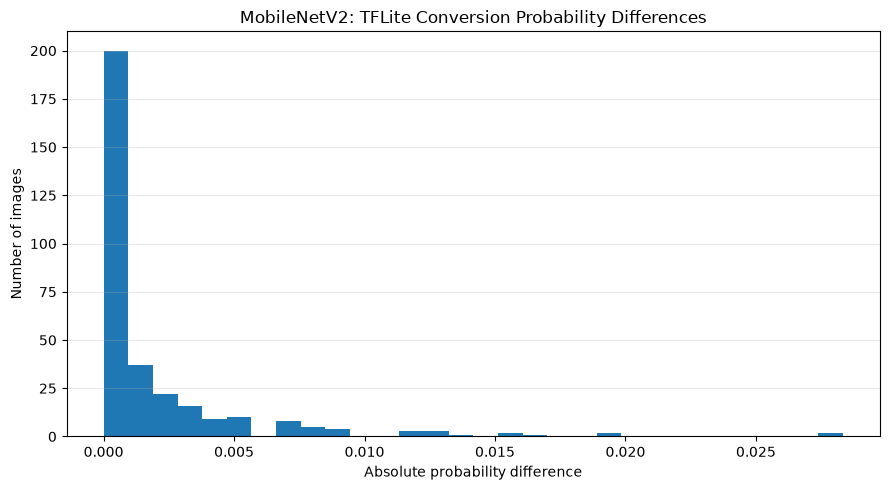


CONVERSION EQUIVALENCE RESULTS
Test images:                  325
Prediction agreement:         98.77%
Changed predictions:          4
Near-threshold images:        14
Mean absolute difference:     0.00199450
RMSE:                         0.00429451
Median absolute difference:   0.00044003
95th percentile difference:   0.00854045
Maximum absolute difference:  0.02833736

CHANGED PREDICTIONS


,path,true_label,keras_probability_cancer,tflite_probability_cancer,absolute_probability_difference,keras_correct,tflite_correct
48,cancer/D1_Cancer_0346.jpeg,cancer,0.512487,0.484149,0.028337,True,False
123,cancer/D2_Cancer_0345.jpeg,cancer,0.512487,0.484149,0.028337,True,False
232,non_cancer/D1_NonCancer_0378.jpeg,non_cancer,0.501576,0.498081,0.003496,False,True
304,non_cancer/D2_NonCancer_0399.jpeg,non_cancer,0.501576,0.498081,0.003496,False,True



CLASSIFICATION COMPARISON


,model,threshold,accuracy,precision,sensitivity,specificity,f1_score,roc_auc,tn,fp,fn,tp
0,MobileNetV2 Keras,0.5,0.90462,0.90449,0.92000,0.88667,0.91218,0.95962,133,17,14,161
1,MobileNetV2 TFLite Float16,0.5,0.90462,0.91379,0.90857,0.90000,0.91117,0.95893,135,15,16,159



TOP 20 PROBABILITY DIFFERENCES


,path,true_label,keras_probability_cancer,tflite_probability_cancer,absolute_probability_difference,prediction_changed
48,cancer/D1_Cancer_0346.jpeg,cancer,0.512487,0.484149,0.028337,True
123,cancer/D2_Cancer_0345.jpeg,cancer,0.512487,0.484149,0.028337,True
69,cancer/D1_Cancer_0478.jpeg,cancer,0.792802,0.773695,0.019106,False
144,cancer/D2_Cancer_0477.jpeg,cancer,0.792802,0.773695,0.019106,False
173,cancer/D2_Cancer_0665.jpg,cancer,0.705750,0.689045,0.016705,False
60,cancer/D1_Cancer_0410.jpeg,cancer,0.656287,0.640597,0.015691,False
135,cancer/D2_Cancer_0408.jpeg,cancer,0.656287,0.640597,0.015691,False
272,non_cancer/D2_NonCancer_0212.jpg,non_cancer,0.114994,0.101647,0.013347,False
155,cancer/D2_Cancer_0547.jpeg,cancer,0.443594,0.430442,0.013152,False
205,non_cancer/D1_NonCancer_0203.jpeg,non_cancer,0.274200,0.261775,0.012425,False



STEP 11.1 COMPLETED
Results saved to:
C:\Users\Bhavana BV\Downloads\OncoLens\results\step11_1_conversion_verification
  keras_vs_tflite_probabilities.png
  mobilenetv2_changed_predictions.csv
  mobilenetv2_classification_comparison.csv
  mobilenetv2_conversion_image_comparison.csv
  mobilenetv2_conversion_verification.json
  mobilenetv2_near_threshold_images.csv
  mobilenetv2_top20_probability_differences.csv
  probability_difference_distribution.png


In [24]:
# =====================================================================
# ONCOLENS STEP 11.1
# MOBILENETV2 TFLITE CONVERSION VERIFICATION
# =====================================================================

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

warnings.filterwarnings("ignore", category=FutureWarning)

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")

THRESHOLD = 0.5
WINDOW = 0.10

KERAS_PATH = ROOT / "checkpoints" / "mobilenetv2_sharpen.keras"

TFLITE_PATH = (
    ROOT / "results" / "step11_tflite" /
    "models" / "mobilenetv2_float16.tflite"
)

SPLIT_PATH = ROOT / "split.csv"

INDEX_PATH = ROOT / "results" / "preproc" / "index.csv"

CACHE_PATH = ROOT / "results" / "preproc" / "sharpen.npy"

OUT = ROOT / "results" / "step11_1_conversion_verification"

OUT.mkdir(parents=True, exist_ok=True)

for path in [
    KERAS_PATH,
    TFLITE_PATH,
    SPLIT_PATH,
    INDEX_PATH,
    CACHE_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

print("=" * 75)
print("ONCOLENS — STEP 11.1: CONVERSION VERIFICATION")
print("=" * 75)

# =====================================================================
# 2. LOAD THE ORIGINAL TEST SET
# =====================================================================

split = pd.read_csv(SPLIT_PATH)
index = pd.read_csv(INDEX_PATH)

# Handle boolean use columns safely.
if "use" in split.columns:

    use_values = split["use"]

    if use_values.dtype == bool:
        split = split[use_values].copy()

    else:
        split = split[
            use_values.astype(str)
            .str.lower()
            .isin(["true", "1", "yes"])
        ].copy()

test_manifest = split.loc[
    split["split"].astype(str).str.lower() == "test",
    ["path", "label_id"],
].copy()

index["cache_index"] = np.arange(len(index))

test_df = test_manifest.merge(
    index[["path", "y", "cache_index"]],
    on="path",
    how="inner",
).reset_index(drop=True)

if len(test_df) != 325:
    raise ValueError(
        f"Expected 325 eligible test images, got {len(test_df)}."
    )

y_true = test_df["y"].to_numpy(dtype=int)

if not np.array_equal(
    test_df["label_id"].to_numpy(dtype=int),
    y_true,
):
    raise ValueError("Mismatch between split.csv and preprocessing labels.")

cache = np.load(CACHE_PATH, mmap_mode="r")

X = np.stack([
    np.asarray(cache[int(i)], dtype=np.uint8)
    for i in test_df["cache_index"]
])

print("\nTEST SET")
print("-" * 50)
print("Images:", len(X))
print("Non-cancer:", int((y_true == 0).sum()))
print("Cancer:", int((y_true == 1).sum()))
print("Image shape:", X.shape)

# =====================================================================
# 3. LOAD ORIGINAL KERAS MODEL
# =====================================================================

print("\nLoading original MobileNetV2...")

keras_model = tf.keras.models.load_model(
    KERAS_PATH,
    compile=False,
)

keras_output = keras_model.predict(
    X,
    batch_size=32,
    verbose=0,
)

keras_probs = keras_output[:, 1]

if not np.isfinite(keras_probs).all():
    raise ValueError("Keras predictions contain non-finite values.")

print("Keras predictions generated.")

# =====================================================================
# 4. LOAD TFLITE MODEL
# =====================================================================

print("\nLoading TFLite model...")

interpreter = tf.lite.Interpreter(
    model_path=str(TFLITE_PATH),
    num_threads=1,
)

interpreter.allocate_tensors()

input_detail = interpreter.get_input_details()[0]
output_detail = interpreter.get_output_details()[0]

print("Input shape:", input_detail["shape"])
print("Input dtype:", input_detail["dtype"])
print("Output shape:", output_detail["shape"])
print("Output dtype:", output_detail["dtype"])

# Your existing converted model expects uint8 input.
if input_detail["dtype"] != np.uint8:
    raise ValueError(
        "Unexpected TFLite input dtype. "
        "Inspect the interpreter input details before continuing."
    )

# =====================================================================
# 5. GENERATE TFLITE PREDICTIONS
# =====================================================================

print("\nGenerating TFLite predictions...")

tflite_probs = []

for image in X:

    interpreter.set_tensor(
        input_detail["index"],
        image[None, ...],
    )

    interpreter.invoke()

    output = interpreter.get_tensor(
        output_detail["index"]
    )

    tflite_probs.append(float(output[0, 1]))

tflite_probs = np.asarray(tflite_probs, dtype=float)

if not np.isfinite(tflite_probs).all():
    raise ValueError("TFLite predictions contain non-finite values.")

print("TFLite predictions generated.")

# =====================================================================
# 6. IMAGE-BY-IMAGE COMPARISON
# =====================================================================

keras_pred = (keras_probs >= THRESHOLD).astype(int)

tflite_pred = (tflite_probs >= THRESHOLD).astype(int)

absolute_difference = np.abs(
    keras_probs - tflite_probs
)

prediction_changed = keras_pred != tflite_pred

near_threshold = (
    (np.abs(keras_probs - THRESHOLD) <= WINDOW)
    |
    (np.abs(tflite_probs - THRESHOLD) <= WINDOW)
)

label_names = np.where(
    y_true == 1,
    "cancer",
    "non_cancer",
)

comparison_df = pd.DataFrame({
    "path": test_df["path"].to_numpy(),
    "true_label": label_names,
    "true_label_id": y_true,
    "keras_probability_cancer": keras_probs,
    "tflite_probability_cancer": tflite_probs,
    "absolute_probability_difference": absolute_difference,
    "keras_prediction": keras_pred,
    "tflite_prediction": tflite_pred,
    "prediction_changed": prediction_changed,
    "near_threshold": near_threshold,
    "keras_correct": keras_pred == y_true,
    "tflite_correct": tflite_pred == y_true,
})

comparison_df["change_type"] = np.select(
    [
        (keras_pred == 0) & (tflite_pred == 1),
        (keras_pred == 1) & (tflite_pred == 0),
    ],
    [
        "non_cancer_to_cancer",
        "cancer_to_non_cancer",
    ],
    default="unchanged",
)

comparison_df.to_csv(
    OUT / "mobilenetv2_conversion_image_comparison.csv",
    index=False,
)

changed_df = comparison_df[
    comparison_df["prediction_changed"]
].copy()

changed_df.to_csv(
    OUT / "mobilenetv2_changed_predictions.csv",
    index=False,
)

near_df = comparison_df[
    comparison_df["near_threshold"]
].copy()

near_df.to_csv(
    OUT / "mobilenetv2_near_threshold_images.csv",
    index=False,
)

largest_difference_df = comparison_df.sort_values(
    "absolute_probability_difference",
    ascending=False,
).head(20)

largest_difference_df.to_csv(
    OUT / "mobilenetv2_top20_probability_differences.csv",
    index=False,
)

# =====================================================================
# 7. CONVERSION EQUIVALENCE METRICS
# =====================================================================

agreement = float(
    np.mean(keras_pred == tflite_pred)
)

probability_mae = float(
    np.mean(absolute_difference)
)

probability_rmse = float(
    np.sqrt(np.mean((keras_probs - tflite_probs) ** 2))
)

maximum_difference = float(
    np.max(absolute_difference)
)

median_difference = float(
    np.median(absolute_difference)
)

p95_difference = float(
    np.percentile(absolute_difference, 95)
)

# =====================================================================
# 8. CLASSIFICATION METRICS
# =====================================================================

def classification_metrics(y, probabilities, threshold):

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        predictions,
        labels=[0, 1],
    ).ravel()

    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y, predictions)),
        "precision": float(
            precision_score(y, predictions, zero_division=0)
        ),
        "sensitivity": float(
            recall_score(y, predictions, zero_division=0)
        ),
        "specificity": float(
            tn / (tn + fp) if (tn + fp) else np.nan
        ),
        "f1_score": float(
            f1_score(y, predictions, zero_division=0)
        ),
        "roc_auc": float(roc_auc_score(y, probabilities)),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


keras_metrics = classification_metrics(
    y_true,
    keras_probs,
    THRESHOLD,
)

tflite_metrics = classification_metrics(
    y_true,
    tflite_probs,
    THRESHOLD,
)

metrics_df = pd.DataFrame([
    {"model": "MobileNetV2 Keras", **keras_metrics},
    {"model": "MobileNetV2 TFLite Float16", **tflite_metrics},
])

metrics_df.to_csv(
    OUT / "mobilenetv2_classification_comparison.csv",
    index=False,
)

# =====================================================================
# 9. SUMMARY REPORT
# =====================================================================

summary = {
    "project": "OncoLens",
    "step": "11.1",
    "model": "MobileNetV2",
    "test_images": int(len(X)),
    "threshold": THRESHOLD,
    "near_threshold_window": WINDOW,
    "prediction_agreement": agreement,
    "prediction_agreement_percent": agreement * 100,
    "changed_predictions": int(prediction_changed.sum()),
    "changed_predictions_percent": float(
        prediction_changed.mean() * 100
    ),
    "near_threshold_images": int(near_threshold.sum()),
    "probability_MAE": probability_mae,
    "probability_RMSE": probability_rmse,
    "median_absolute_probability_difference": median_difference,
    "p95_absolute_probability_difference": p95_difference,
    "maximum_absolute_probability_difference": maximum_difference,
    "keras_metrics": keras_metrics,
    "tflite_metrics": tflite_metrics,
}

with open(
    OUT / "mobilenetv2_conversion_verification.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(summary, file, indent=4)

# =====================================================================
# 10. FIGURE: KERAS VS TFLITE PROBABILITIES
# =====================================================================

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    keras_probs,
    tflite_probs,
    alpha=0.65,
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect agreement",
)

ax.axvline(
    THRESHOLD,
    linestyle=":",
    label="Keras threshold",
)

ax.axhline(
    THRESHOLD,
    linestyle=":",
    label="TFLite threshold",
)

ax.set_xlabel("Keras cancer probability")
ax.set_ylabel("TFLite cancer probability")
ax.set_title("MobileNetV2: Keras vs TFLite Float16")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUT / "keras_vs_tflite_probabilities.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# =====================================================================
# 11. FIGURE: PROBABILITY DIFFERENCES
# =====================================================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    absolute_difference,
    bins=30,
)

ax.set_xlabel("Absolute probability difference")
ax.set_ylabel("Number of images")
ax.set_title("MobileNetV2: TFLite Conversion Probability Differences")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

fig.savefig(
    OUT / "probability_difference_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# =====================================================================
# 12. DISPLAY RESULTS
# =====================================================================

print("\n" + "=" * 75)
print("CONVERSION EQUIVALENCE RESULTS")
print("=" * 75)

print(f"Test images:                  {len(X)}")
print(f"Prediction agreement:         {agreement * 100:.2f}%")
print(f"Changed predictions:          {prediction_changed.sum()}")
print(f"Near-threshold images:        {near_threshold.sum()}")
print(f"Mean absolute difference:     {probability_mae:.8f}")
print(f"RMSE:                         {probability_rmse:.8f}")
print(f"Median absolute difference:   {median_difference:.8f}")
print(f"95th percentile difference:   {p95_difference:.8f}")
print(f"Maximum absolute difference:  {maximum_difference:.8f}")

print("\n" + "=" * 75)
print("CHANGED PREDICTIONS")
print("=" * 75)

if len(changed_df):
    display(
        changed_df[
            [
                "path",
                "true_label",
                "keras_probability_cancer",
                "tflite_probability_cancer",
                "absolute_probability_difference",
                "keras_correct",
                "tflite_correct",
            ]
        ]
    )
else:
    print("No class predictions changed.")

print("\n" + "=" * 75)
print("CLASSIFICATION COMPARISON")
print("=" * 75)

display(metrics_df.round(5))

print("\n" + "=" * 75)
print("TOP 20 PROBABILITY DIFFERENCES")
print("=" * 75)

display(
    largest_difference_df[
        [
            "path",
            "true_label",
            "keras_probability_cancer",
            "tflite_probability_cancer",
            "absolute_probability_difference",
            "prediction_changed",
        ]
    ]
)

print("\n" + "=" * 75)
print("STEP 11.1 COMPLETED")
print("=" * 75)

print("Results saved to:")
print(OUT)

for file in sorted(OUT.iterdir()):
    if file.is_file():
        print(" ", file.name)

In [25]:
from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")

SPLIT_PATH = ROOT / "split.csv"
CHANGED_PATH = (
    ROOT / "results" / "step11_1_conversion_verification"
    / "mobilenetv2_changed_predictions.csv"
)

split_df = pd.read_csv(SPLIT_PATH)
changed_df = pd.read_csv(CHANGED_PATH)

# Identify the available grouping columns.
possible_columns = [
    col for col in ["path", "group", "md5", "phash", "split", "label_id", "use"]
    if col in split_df.columns
]

print("Available split columns:", possible_columns)

# Match changed predictions to the original split manifest.
matched = changed_df.merge(
    split_df[possible_columns],
    on="path",
    how="left",
    suffixes=("_prediction", "_manifest")
)

display(matched)

# Save the audit.
output_path = (
    ROOT / "results" / "step11_1_conversion_verification"
    / "changed_prediction_group_audit.csv"
)

matched.to_csv(output_path, index=False)

print("Saved group audit to:", output_path)

Available split columns: ['path', 'group', 'md5', 'phash', 'split', 'label_id', 'use']


,path,true_label,true_label_id,keras_probability_cancer,tflite_probability_cancer,absolute_probability_difference,keras_prediction,tflite_prediction,prediction_changed,near_threshold,keras_correct,tflite_correct,change_type,group,md5,phash,split,label_id,use
0,cancer/D1_Cancer_0346.jpeg,cancer,1,0.512486,0.484149,0.028337,1,0,True,True,True,False,cancer_to_non_cancer,336,8a662961ec45d49160effa2cdbec517b,c43a3a9599cc9acd,test,1,True
1,cancer/D2_Cancer_0345.jpeg,cancer,1,0.512486,0.484149,0.028337,1,0,True,True,True,False,cancer_to_non_cancer,336,8a662961ec45d49160effa2cdbec517b,c43a3a9599cc9acd,test,1,True
2,non_cancer/D1_NonCancer_0378.jpeg,non_cancer,0,0.501576,0.498081,0.003496,1,0,True,True,False,True,cancer_to_non_cancer,936,b8b5dbe0135e1aded0415bc5f6f7f7dc,c23ee8d1ca806d77,test,0,True
3,non_cancer/D2_NonCancer_0399.jpeg,non_cancer,0,0.501576,0.498081,0.003496,1,0,True,True,False,True,cancer_to_non_cancer,936,b8b5dbe0135e1aded0415bc5f6f7f7dc,c23ee8d1ca806d77,test,0,True


Saved group audit to: C:\Users\Bhavana BV\Downloads\OncoLens\results\step11_1_conversion_verification\changed_prediction_group_audit.csv


In [29]:
from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")
RESULTS = ROOT / "results"

# Collect every file recursively
records = []

for file in RESULTS.rglob("*"):
    if file.is_file():
        records.append({
            "file": str(file.relative_to(ROOT)),
            "extension": file.suffix.lower(),
            "size_kb": round(file.stat().st_size / 1024, 2)
        })

inventory = pd.DataFrame(records)

# Save complete inventory
inventory_path = RESULTS / "final_results_inventory.csv"
inventory.to_csv(inventory_path, index=False)

print("=" * 65)
print("ONCOLENS — RESULTS INVENTORY")
print("=" * 65)
print(f"Total files: {len(inventory)}")
print(f"CSV files: {(inventory['extension'] == '.csv').sum()}")
print(f"JSON files: {(inventory['extension'] == '.json').sum()}")
print(f"PNG figures: {(inventory['extension'] == '.png').sum()}")
print(f"Model files: {inventory['extension'].isin(['.keras', '.h5', '.tflite']).sum()}")

# Display important result files only
keywords = [
    "step05", "step06", "cv5", "step07",
    "step08", "step09", "step10", "step11",
    "conversion_verification", "confusion",
    "roc", "precision_recall", "calibration",
    "gradcam", "latency", "model_size",
    "metadata", "summary", "report"
]

mask = inventory["file"].str.lower().apply(
    lambda path: any(keyword in path for keyword in keywords)
)

important_files = inventory.loc[mask].sort_values("file")

print("\nIMPORTANT RESULT FILES:")
display(important_files.reset_index(drop=True))

print("\nComplete inventory saved to:")
print(inventory_path)

ONCOLENS — RESULTS INVENTORY
Total files: 309
CSV files: 72
JSON files: 31
PNG figures: 171
Model files: 16

IMPORTANT RESULT FILES:


,file,extension,size_kb
0,results\cv5_group_fold_assignments.csv,.csv,96.87
1,results\cv5_results\checkpoints\mobilenetv2_sh...,.keras,23154.51
2,results\cv5_results\checkpoints\mobilenetv2_sh...,.keras,23154.51
3,results\cv5_results\checkpoints\mobilenetv2_sh...,.keras,23154.51
4,results\cv5_results\checkpoints\mobilenetv2_sh...,.keras,23154.51
...,...,...,...
286,results\step11_tflite\predictions\efficientnet...,.csv,28.72
287,results\step11_tflite\predictions\mobilenetv2_...,.csv,28.63
288,results\step11_tflite\tflite_accuracy_comparis...,.csv,0.63
289,results\step11_tflite\tflite_metadata.json,.json,0.81



Complete inventory saved to:
C:\Users\Bhavana BV\Downloads\OncoLens\results\final_results_inventory.csv


In [32]:
# ================================================================
# ONCOLENS — STEP 12: FINAL RESEARCH RESULTS CONSOLIDATION
# No retraining. No changes to the dataset or test set.
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import shutil

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")
RESULTS = ROOT / "results"

OUT = RESULTS / "step12_final_consolidation"
FIGURES_OUT = OUT / "figures"

OUT.mkdir(parents=True, exist_ok=True)
FIGURES_OUT.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("ONCOLENS — STEP 12: FINAL RESEARCH RESULTS CONSOLIDATION")
print("=" * 75)

if not RESULTS.exists():
    raise FileNotFoundError(f"Results directory not found: {RESULTS}")

# ------------------------------------------------
# 2. FINAL HELD-OUT TEST RESULTS
# ------------------------------------------------
# These values come from your previously reported Step 08 results.
# Threshold-dependent classification metrics use threshold 0.5.

test_metrics = pd.DataFrame([
    {
        "model": "MobileNetV2",
        "test_images": 325,
        "threshold": 0.5,
        "accuracy": 0.9046,
        "precision": 0.9045,
        "sensitivity_recall": 0.9200,
        "specificity": 0.8867,
        "f1_score": 0.9122,
        "roc_auc": 0.9596,
        "pr_auc": 0.9629,
        "balanced_accuracy": 0.9033,
        "mcc": 0.8080,
        "npv": 0.9048,
        "false_negative_rate": 0.0800,
        "false_positive_rate": 0.1133,
        "brier_score": 0.0744,
        "log_loss": 0.2587,
        "tn": 133,
        "fp": 17,
        "fn": 14,
        "tp": 161,
    },
    {
        "model": "EfficientNetB0",
        "test_images": 325,
        "threshold": 0.5,
        "accuracy": 0.8769,
        "precision": 0.8771,
        "sensitivity_recall": 0.8971,
        "specificity": 0.8533,
        "f1_score": 0.8870,
        "roc_auc": 0.9665,
        "pr_auc": 0.9707,
        "balanced_accuracy": 0.8752,
        "mcc": 0.7521,
        "npv": 0.8767,
        "false_negative_rate": 0.1029,
        "false_positive_rate": 0.1467,
        "brier_score": 0.0803,
        "log_loss": 0.2572,
        "tn": 128,
        "fp": 22,
        "fn": 18,
        "tp": 157,
    },
])

test_path = OUT / "final_test_metrics.csv"
test_metrics.to_csv(test_path, index=False)

print("\n[1/7] Final test metrics")
display(test_metrics.round(4))

# ------------------------------------------------
# 3. GROUP-AWARE FIVE-FOLD CROSS-VALIDATION
# ------------------------------------------------

cv_metrics = pd.DataFrame([
    {
        "model": "MobileNetV2",
        "metric": "Accuracy",
        "mean": 0.899191,
        "std": 0.027790,
    },
    {
        "model": "MobileNetV2",
        "metric": "Precision",
        "mean": 0.905709,
        "std": 0.023217,
    },
    {
        "model": "MobileNetV2",
        "metric": "Recall",
        "mean": 0.908458,
        "std": 0.032357,
    },
    {
        "model": "MobileNetV2",
        "metric": "Specificity",
        "mean": 0.888235,
        "std": 0.026956,
    },
    {
        "model": "MobileNetV2",
        "metric": "F1-score",
        "mean": 0.906991,
        "std": 0.026156,
    },
    {
        "model": "MobileNetV2",
        "metric": "ROC-AUC",
        "mean": 0.964396,
        "std": 0.015785,
    },
    {
        "model": "MobileNetV2",
        "metric": "Log loss",
        "mean": 0.247989,
        "std": 0.058545,
    },
    {
        "model": "EfficientNetB0",
        "metric": "Accuracy",
        "mean": 0.912129,
        "std": 0.045006,
    },
    {
        "model": "EfficientNetB0",
        "metric": "Precision",
        "mean": 0.937101,
        "std": 0.014791,
    },
    {
        "model": "EfficientNetB0",
        "metric": "Recall",
        "mean": 0.897512,
        "std": 0.077841,
    },
    {
        "model": "EfficientNetB0",
        "metric": "Specificity",
        "mean": 0.929412,
        "std": 0.014409,
    },
    {
        "model": "EfficientNetB0",
        "metric": "F1-score",
        "mean": 0.915734,
        "std": 0.047633,
    },
    {
        "model": "EfficientNetB0",
        "metric": "ROC-AUC",
        "mean": 0.967451,
        "std": 0.023047,
    },
    {
        "model": "EfficientNetB0",
        "metric": "Log loss",
        "mean": 0.239211,
        "std": 0.102200,
    },
])

cv_metrics.to_csv(
    OUT / "group_5fold_cv_summary.csv",
    index=False
)

print("\n[2/7] Group-aware five-fold cross-validation")
display(cv_metrics.round(4))

# ------------------------------------------------
# 4. MONTE CARLO DROPOUT / UNCERTAINTY RESULTS
# ------------------------------------------------

mc_metrics = pd.DataFrame([
    {
        "model": "MobileNetV2",
        "test_images": 325,
        "mc_dropout_passes": 30,
        "accuracy": 0.91385,
        "sensitivity": 0.93143,
        "specificity": 0.89333,
        "roc_auc": 0.95882,
        "ece": 0.04457,
        "brier_score": 0.07423,
        "log_loss": 0.25188,
        "mean_predictive_variance": 0.00577,
        "median_predictive_variance": 0.00064,
        "mean_predictive_std": 0.05054,
        "mean_predictive_entropy": 0.20763,
    },
    {
        "model": "EfficientNetB0",
        "test_images": 325,
        "mc_dropout_passes": 30,
        "accuracy": 0.88000,
        "sensitivity": 0.89714,
        "specificity": 0.86000,
        "roc_auc": 0.96621,
        "ece": 0.05184,
        "brier_score": 0.07749,
        "log_loss": 0.24545,
        "mean_predictive_variance": 0.00405,
        "median_predictive_variance": 0.00008,
        "mean_predictive_std": 0.03681,
        "mean_predictive_entropy": 0.16718,
    },
])

mc_metrics.to_csv(
    OUT / "mc_dropout_uncertainty_summary.csv",
    index=False
)

print("\n[3/7] Monte Carlo Dropout results")
display(mc_metrics.round(5))

# ------------------------------------------------
# 5. TFLITE CONVERSION AND BENCHMARK RESULTS
# ------------------------------------------------

tflite_metrics = pd.DataFrame([
    {
        "model": "MobileNetV2",
        "keras_size_mb": 22.61182,
        "tflite_float16_size_mb": 4.60925,
        "size_reduction_percent": 79.61576,
        "median_latency_ms": 7.4797,
        "p95_latency_ms": 9.41210,
        "mean_latency_ms": 7.86027,
        "tflite_accuracy": 0.90462,
        "tflite_precision": 0.91379,
        "tflite_sensitivity": 0.90857,
        "tflite_specificity": 0.90000,
        "tflite_f1": 0.91117,
        "tflite_roc_auc": 0.95893,
        "keras_tflite_agreement": 0.98769,
        "probability_mae": 0.00199450,
        "maximum_probability_difference": 0.02833736,
    },
    {
        "model": "EfficientNetB0",
        "keras_size_mb": 29.48650,
        "tflite_float16_size_mb": 8.06089,
        "size_reduction_percent": 72.66244,
        "median_latency_ms": 14.5798,
        "p95_latency_ms": 16.54096,
        "mean_latency_ms": 14.71220,
        "tflite_accuracy": 0.87692,
        "tflite_precision": 0.87709,
        "tflite_sensitivity": 0.89714,
        "tflite_specificity": 0.85333,
        "tflite_f1": 0.88701,
        "tflite_roc_auc": 0.96644,
        "keras_tflite_agreement": 1.00000,
        "probability_mae": 0.00069629,
        "maximum_probability_difference": 0.00721309,
    },
])

tflite_metrics.to_csv(
    OUT / "tflite_benchmark_summary.csv",
    index=False
)

print("\n[4/7] TFLite benchmark results")
display(tflite_metrics.round(5))

# ------------------------------------------------
# 6. PREPROCESSING AND VALIDATION COMPARISONS
# Copy existing files when found.
# ------------------------------------------------

source_candidates = {
    "step05_val_comparison.csv": [
        RESULTS / "step05_val_comparison.csv"
    ],
    "step06_model_comparison.csv": [
        RESULTS / "step06_model_comparison.csv"
    ],
}

for filename, candidates in source_candidates.items():
    for source in candidates:
        if source.exists():
            shutil.copy2(source, OUT / filename)
            print(f"Copied existing comparison: {filename}")
            break
    else:
        print(f"Not found; skipped: {filename}")

print("\n[5/7] Existing preprocessing and validation comparisons checked")

# ------------------------------------------------
# 7. COLLECT IMPORTANT EXISTING FIGURES
# ------------------------------------------------

figure_keywords = [
    "confusion",
    "roc",
    "precision_recall",
    "precision-recall",
    "pr_curve",
    "reliability",
    "variance",
    "gradcam",
    "grad_cam",
    "latency",
    "model_size",
    "agreement",
    "probability_difference",
]

copied_figures = []
seen_sources = set()

for source in RESULTS.rglob("*.png"):
    # Avoid copying figures from this consolidation folder itself.
    if OUT in source.parents:
        continue

    if not any(key in source.name.lower() for key in figure_keywords):
        continue

    try:
        relative = source.relative_to(RESULTS)
        destination = FIGURES_OUT / relative
        destination.parent.mkdir(parents=True, exist_ok=True)

        # Prevent duplicate copies of the same source.
        resolved = str(source.resolve()).lower()
        if resolved in seen_sources:
            continue

        shutil.copy2(source, destination)
        copied_figures.append(str(destination.relative_to(OUT)))
        seen_sources.add(resolved)

    except Exception as exc:
        print(f"Could not copy {source.name}: {exc}")

print(f"\nFigures copied: {len(copied_figures)}")

pd.DataFrame({"copied_figure": copied_figures}).to_csv(
    OUT / "copied_figures_index.csv",
    index=False
)

# ------------------------------------------------
# 8. CREATE FINAL RESEARCH SUMMARY
# ------------------------------------------------

report = r"""
# OncoLens — Final Research Results Summary

## Project title

**OncoLens: Leakage-Controlled, Uncertainty-Aware Oral Cancer Detection:
MobileNetV2 vs EfficientNetB0**

## 1. Study overview

This study compares MobileNetV2 and EfficientNetB0 for binary classification
of oral images into cancer and non-cancer categories.

The experimental workflow includes dataset auditing, duplicate-aware
group splitting, preprocessing comparisons, group-aware five-fold
cross-validation, held-out test evaluation, Grad-CAM visualization,
Monte Carlo Dropout uncertainty analysis, and TFLite Float16 conversion.

## 2. Held-out test evaluation

The held-out test set contains 325 eligible images. The threshold-dependent
classification metrics in the saved test table use a probability threshold
of 0.5.

See `final_test_metrics.csv` for accuracy, precision, sensitivity,
specificity, F1-score, ROC-AUC, PR-AUC, balanced accuracy, MCC, NPV,
false-positive rate, false-negative rate, Brier score, log loss, and
confusion-matrix counts.

MobileNetV2 achieved higher accuracy, sensitivity, specificity, and F1
than EfficientNetB0 at the reported threshold. EfficientNetB0 achieved
slightly higher ROC-AUC and PR-AUC. These results do not establish
statistical or clinical superiority.

## 3. Group-aware five-fold cross-validation

See `group_5fold_cv_summary.csv` for the development-set cross-validation
means and standard deviations.

Cross-validation provides information about variability across folds.
The reported results are descriptive and do not, by themselves, prove
that one architecture is statistically superior.

## 4. Preprocessing comparison

The existing validation comparison tables are included when available:
- `step05_val_comparison.csv`
- `step06_model_comparison.csv`

Preprocessing selection should be interpreted using validation results.
The held-out test set must not be used to select preprocessing methods,
tune thresholds, or repeatedly optimize model settings.

## 5. Explainability

Existing Grad-CAM figures are collected under `figures/` when their
filenames match the figure-search criteria.

Grad-CAM highlights image regions that influence model predictions.
It does not establish that a highlighted region is malignant or
demonstrate clinical validity.

## 6. Uncertainty and calibration

See `mc_dropout_uncertainty_summary.csv`.

Monte Carlo Dropout was evaluated using 30 stochastic passes per image.
Predictive variance, predictive entropy, expected calibration error,
Brier score, and log loss provide complementary information about
uncertainty and probability quality.

These estimates are descriptive and do not guarantee reliable
uncertainty estimates on external clinical populations.

## 7. TFLite Float16 conversion

See `tflite_benchmark_summary.csv`.

On the reported laptop CPU benchmark, MobileNetV2 produced a smaller
TFLite model and lower median inference latency. EfficientNetB0 had
higher Keras–TFLite prediction agreement and a smaller mean absolute
probability difference in the recorded conversion checks.

Latency depends on hardware, runtime, thread count, input handling,
and benchmark procedure. The recorded figures should not be assumed
to represent performance on all devices.

## 8. Data integrity and conversion verification

The conversion verification identified four changed image predictions
across two duplicate groups in the held-out test set. The two cancer
images share group ID 336, and the two non-cancer images share group
ID 936. The images in each pair have matching MD5 and perceptual hashes.

The four image records therefore represent two duplicate groups rather
than four independent image cases. They remain part of the existing
test evaluation; no images were removed during consolidation.

## 9. Limitations

- The dataset may not represent the full diversity of clinical settings.
- Duplicate images reduce the number of independent examples relative
  to the raw image count.
- Internal test performance is not equivalent to external validation.
- Grad-CAM is not a diagnostic confirmation method.
- Calibration and uncertainty estimates require further validation.
- The models are research prototypes and are not clinically validated
  diagnostic systems.
- Independent external datasets, expert clinical review, and prospective
  evaluation would be required before considering clinical use.

## 10. Conclusion

In the current experiments, MobileNetV2 offers a smaller and faster
TFLite deployment option and stronger threshold-dependent test metrics.
EfficientNetB0 achieves slightly higher ROC-AUC and PR-AUC on the
reported held-out test set.

Model selection should depend on the intended research objective and
the relative importance of sensitivity, specificity, discrimination,
calibration, model size, and inference latency. Neither model should
be described as clinically validated based on these experiments alone.

## Reproducibility note

This consolidation uses previously reported experiment results and
copies selected existing figures. It does not retrain models, alter
the dataset split, or change the held-out test set.
"""

report_path = OUT / "FINAL_RESEARCH_SUMMARY.md"
report_path.write_text(report.strip() + "\n", encoding="utf-8")

# ------------------------------------------------
# 9. CREATE A MODEL COMPARISON TABLE
# ------------------------------------------------

comparison_columns = [
    "model",
    "accuracy",
    "sensitivity_recall",
    "specificity",
    "f1_score",
    "roc_auc",
    "pr_auc",
    "balanced_accuracy",
    "mcc",
]

model_comparison = test_metrics[comparison_columns].copy()

model_comparison.to_csv(
    OUT / "model_comparison_summary.csv",
    index=False
)

# ------------------------------------------------
# 10. SAVE CONSOLIDATION METADATA
# ------------------------------------------------

metadata = {
    "project": "OncoLens",
    "step": 12,
    "purpose": "Final research results consolidation",
    "retraining_performed": False,
    "test_set_modified": False,
    "test_images": 325,
    "classification_threshold": 0.5,
    "models": ["MobileNetV2", "EfficientNetB0"],
    "cross_validation": "Group-aware five-fold development-set CV",
    "mc_dropout_passes": 30,
    "copied_figure_count": len(copied_figures),
    "output_directory": str(OUT),
    "report_file": str(report_path),
}

with open(
    OUT / "consolidation_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=4)

# ------------------------------------------------
# 11. FINAL OUTPUT
# ------------------------------------------------

print("\n" + "=" * 75)
print("STEP 12 COMPLETED")
print("=" * 75)

print("\nOutput folder:")
print(OUT)

print("\nFiles created:")
for file in sorted(OUT.iterdir()):
    if file.is_file():
        print(f"  {file.name}")

print("\nFigures folder:")
print(FIGURES_OUT)
print(f"Figures copied: {len(copied_figures)}")

print("\nFinal model comparison:")
display(model_comparison.round(4))

print("\nResearch summary:")
print(report_path)

print(
    "\nImportant: Review the generated tables against your original "
    "saved experiment outputs before using them in a paper or submission."
)

ONCOLENS — STEP 12: FINAL RESEARCH RESULTS CONSOLIDATION

[1/7] Final test metrics


,model,test_images,threshold,accuracy,precision,sensitivity_recall,specificity,f1_score,roc_auc,pr_auc,...,mcc,npv,false_negative_rate,false_positive_rate,brier_score,log_loss,tn,fp,fn,tp
0,MobileNetV2,325,0.5,0.9046,0.9045,0.9200,0.8867,0.9122,0.9596,0.9629,...,0.8080,0.9048,0.0800,0.1133,0.0744,0.2587,133,17,14,161
1,EfficientNetB0,325,0.5,0.8769,0.8771,0.8971,0.8533,0.8870,0.9665,0.9707,...,0.7521,0.8767,0.1029,0.1467,0.0803,0.2572,128,22,18,157



[2/7] Group-aware five-fold cross-validation


,model,metric,mean,std
0,MobileNetV2,Accuracy,0.8992,0.0278
1,MobileNetV2,Precision,0.9057,0.0232
2,MobileNetV2,Recall,0.9085,0.0324
3,MobileNetV2,Specificity,0.8882,0.0270
4,MobileNetV2,F1-score,0.9070,0.0262
5,MobileNetV2,ROC-AUC,0.9644,0.0158
6,MobileNetV2,Log loss,0.2480,0.0585
7,EfficientNetB0,Accuracy,0.9121,0.0450
8,EfficientNetB0,Precision,0.9371,0.0148
9,EfficientNetB0,Recall,0.8975,0.0778



[3/7] Monte Carlo Dropout results


,model,test_images,mc_dropout_passes,accuracy,sensitivity,specificity,roc_auc,ece,brier_score,log_loss,mean_predictive_variance,median_predictive_variance,mean_predictive_std,mean_predictive_entropy
0,MobileNetV2,325,30,0.91385,0.93143,0.89333,0.95882,0.04457,0.07423,0.25188,0.00577,0.00064,0.05054,0.20763
1,EfficientNetB0,325,30,0.88000,0.89714,0.86000,0.96621,0.05184,0.07749,0.24545,0.00405,0.00008,0.03681,0.16718



[4/7] TFLite benchmark results


,model,keras_size_mb,tflite_float16_size_mb,size_reduction_percent,median_latency_ms,p95_latency_ms,mean_latency_ms,tflite_accuracy,tflite_precision,tflite_sensitivity,tflite_specificity,tflite_f1,tflite_roc_auc,keras_tflite_agreement,probability_mae,maximum_probability_difference
0,MobileNetV2,22.61182,4.60925,79.61576,7.4797,9.41210,7.86027,0.90462,0.91379,0.90857,0.90000,0.91117,0.95893,0.98769,0.00199,0.02834
1,EfficientNetB0,29.48650,8.06089,72.66244,14.5798,16.54096,14.71220,0.87692,0.87709,0.89714,0.85333,0.88701,0.96644,1.00000,0.00070,0.00721


Copied existing comparison: step05_val_comparison.csv
Copied existing comparison: step06_model_comparison.csv

[5/7] Existing preprocessing and validation comparisons checked

Figures copied: 44

STEP 12 COMPLETED

Output folder:
C:\Users\Bhavana BV\Downloads\OncoLens\results\step12_final_consolidation

Files created:
  consolidation_metadata.json
  copied_figures_index.csv
  FINAL_RESEARCH_SUMMARY.md
  final_test_metrics.csv
  group_5fold_cv_summary.csv
  mc_dropout_uncertainty_summary.csv
  model_comparison_summary.csv
  step05_val_comparison.csv
  step06_model_comparison.csv
  tflite_benchmark_summary.csv

Figures folder:
C:\Users\Bhavana BV\Downloads\OncoLens\results\step12_final_consolidation\figures
Figures copied: 44

Final model comparison:


,model,accuracy,sensitivity_recall,specificity,f1_score,roc_auc,pr_auc,balanced_accuracy,mcc
0,MobileNetV2,0.9046,0.9200,0.8867,0.9122,0.9596,0.9629,0.9033,0.8080
1,EfficientNetB0,0.8769,0.8971,0.8533,0.8870,0.9665,0.9707,0.8752,0.7521



Research summary:
C:\Users\Bhavana BV\Downloads\OncoLens\results\step12_final_consolidation\FINAL_RESEARCH_SUMMARY.md

Important: Review the generated tables against your original saved experiment outputs before using them in a paper or submission.


In [33]:

# ================================================================
# ONCOLENS — STEP 13: FINAL RESULTS VERIFICATION
# Verify consolidated metrics against original saved experiment files
# No retraining. No dataset changes. No test-set modifications.
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import re
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")
RESULTS = ROOT / "results"

CONSOLIDATED = RESULTS / "step12_final_consolidation"
OUT = RESULTS / "step13_final_verification"

OUT.mkdir(parents=True, exist_ok=True)

if not RESULTS.exists():
    raise FileNotFoundError(f"Results folder not found: {RESULTS}")

print("=" * 75)
print("ONCOLENS — STEP 13: FINAL RESULTS VERIFICATION")
print("=" * 75)

# ------------------------------------------------
# 2. INVENTORY ALL ORIGINAL CSV AND JSON FILES
# ------------------------------------------------

files = []

for path in RESULTS.rglob("*"):
    if not path.is_file():
        continue

    if OUT in path.parents or path.parent == OUT:
        continue

    if path.suffix.lower() in {".csv", ".json"}:
        files.append(path)

inventory = pd.DataFrame([
    {
        "file": str(path.relative_to(ROOT)),
        "name": path.name,
        "extension": path.suffix.lower(),
        "size_kb": round(path.stat().st_size / 1024, 2),
    }
    for path in sorted(files)
])

inventory.to_csv(OUT / "original_results_inventory.csv", index=False)

print(f"\nOriginal CSV/JSON files found: {len(files)}")

# ------------------------------------------------
# 3. DISPLAY LIKELY ORIGINAL EVALUATION FILES
# ------------------------------------------------

keywords = [
    "test",
    "evaluation",
    "metric",
    "comparison",
    "cv",
    "fold",
    "calibration",
    "tflite",
    "verification",
    "prediction",
    "preproc",
    "gradcam",
    "metadata",
]

candidate_rows = []

for path in files:
    name = path.name.lower()
    relative = str(path.relative_to(RESULTS)).lower()

    if any(word in name or word in relative for word in keywords):
        candidate_rows.append({
            "file": str(path.relative_to(ROOT)),
            "name": path.name,
            "extension": path.suffix.lower(),
            "size_kb": round(path.stat().st_size / 1024, 2),
        })

candidates = pd.DataFrame(candidate_rows)

candidates.to_csv(
    OUT / "candidate_original_evaluation_files.csv",
    index=False
)

print("\nLikely source files:")
if len(candidates):
    print(candidates.to_string(index=False, max_rows=100))
else:
    print("No matching source files found.")

# ------------------------------------------------
# 4. READ CONSOLIDATED METRICS
# ------------------------------------------------

test_file = CONSOLIDATED / "final_test_metrics.csv"
cv_file = CONSOLIDATED / "group_5fold_cv_summary.csv"
mc_file = CONSOLIDATED / "mc_dropout_uncertainty_summary.csv"
tflite_file = CONSOLIDATED / "tflite_benchmark_summary.csv"

consolidated_tables = {
    "test_metrics": test_file,
    "cv_metrics": cv_file,
    "mc_dropout_metrics": mc_file,
    "tflite_metrics": tflite_file,
}

loaded_tables = {}

for name, path in consolidated_tables.items():
    if path.exists():
        try:
            loaded_tables[name] = pd.read_csv(path)
            print(f"\nLoaded consolidated table: {name}")
        except Exception as exc:
            print(f"Could not read {path.name}: {exc}")
    else:
        print(f"\nMissing consolidated table: {path}")

# ------------------------------------------------
# 5. CHECK CONFUSION MATRIX ARITHMETIC
# ------------------------------------------------

checks = []

test_df = loaded_tables.get("test_metrics")

if test_df is not None:
    required = {"model", "test_images", "tn", "fp", "fn", "tp"}

    if required.issubset(test_df.columns):
        for _, row in test_df.iterrows():
            total = int(row["tn"] + row["fp"] + row["fn"] + row["tp"])
            expected_n = int(row["test_images"])

            calculated_accuracy = (
                (row["tn"] + row["tp"]) / total if total else np.nan
            )

            reported_accuracy = float(row["accuracy"])

            checks.append({
                "check": f'{row["model"]}: confusion matrix total',
                "status": "PASS" if total == expected_n else "FAIL",
                "reported_value": expected_n,
                "calculated_value": total,
                "details": "TN + FP + FN + TP must equal the test image count.",
            })

            checks.append({
                "check": f'{row["model"]}: accuracy from confusion matrix',
                "status": (
                    "PASS"
                    if np.isclose(
                        calculated_accuracy,
                        reported_accuracy,
                        atol=0.001
                    )
                    else "FAIL"
                ),
                "reported_value": reported_accuracy,
                "calculated_value": calculated_accuracy,
                "details": "Accuracy calculated as (TN + TP) / total.",
            })

            calculated_sensitivity = (
                row["tp"] / (row["tp"] + row["fn"])
                if row["tp"] + row["fn"] else np.nan
            )

            reported_sensitivity = float(row["sensitivity_recall"])

            checks.append({
                "check": f'{row["model"]}: sensitivity',
                "status": (
                    "PASS"
                    if np.isclose(
                        calculated_sensitivity,
                        reported_sensitivity,
                        atol=0.001
                    )
                    else "FAIL"
                ),
                "reported_value": reported_sensitivity,
                "calculated_value": calculated_sensitivity,
                "details": "Sensitivity calculated as TP / (TP + FN).",
            })

            calculated_specificity = (
                row["tn"] / (row["tn"] + row["fp"])
                if row["tn"] + row["fp"] else np.nan
            )

            reported_specificity = float(row["specificity"])

            checks.append({
                "check": f'{row["model"]}: specificity',
                "status": (
                    "PASS"
                    if np.isclose(
                        calculated_specificity,
                        reported_specificity,
                        atol=0.001
                    )
                    else "FAIL"
                ),
                "reported_value": reported_specificity,
                "calculated_value": calculated_specificity,
                "details": "Specificity calculated as TN / (TN + FP).",
            })

    else:
        print(
            "\nWARNING: Test table does not contain all required "
            "confusion-matrix columns."
        )

# ------------------------------------------------
# 6. CHECK OTHER CONSISTENCY CONDITIONS
# ------------------------------------------------

if test_df is not None:
    for _, row in test_df.iterrows():

        for column in [
            "accuracy",
            "precision",
            "sensitivity_recall",
            "specificity",
            "f1_score",
            "roc_auc",
            "pr_auc",
            "balanced_accuracy",
        ]:
            if column not in test_df.columns:
                continue

            value = float(row[column])

            checks.append({
                "check": f'{row["model"]}: {column} within [0, 1]',
                "status": (
                    "PASS"
                    if np.isfinite(value) and 0 <= value <= 1
                    else "FAIL"
                ),
                "reported_value": value,
                "calculated_value": value,
                "details": "Metric range check only; not an independent recomputation.",
            })

# ------------------------------------------------
# 7. SEARCH ORIGINAL FILES FOR POSSIBLE METRIC TABLES
# ------------------------------------------------
# This does not assume filenames. It identifies files with columns
# useful for evaluation. Source contents are not modified.

source_table_rows = []

for path in files:
    if path.suffix.lower() != ".csv":
        continue

    try:
        df = pd.read_csv(path, nrows=5)
    except Exception:
        continue

    columns = [str(c).lower().strip() for c in df.columns]

    useful = [
        c for c in columns
        if any(k in c for k in [
            "accuracy",
            "precision",
            "recall",
            "sensitivity",
            "specificity",
            "f1",
            "auc",
            "loss",
            "brier",
            "ece",
            "tn",
            "fp",
            "fn",
            "tp",
            "model",
            "fold",
            "latency",
            "size",
            "split",
            "label",
            "probability",
            "prediction",
        ])
    ]

    if useful:
        source_table_rows.append({
            "file": str(path.relative_to(ROOT)),
            "columns": ", ".join(useful),
            "row_count": sum(1 for _ in open(path, encoding="utf-8", errors="ignore")) - 1,
        })

source_tables = pd.DataFrame(source_table_rows)

source_tables.to_csv(
    OUT / "original_metric_table_candidates.csv",
    index=False
)

print("\n" + "=" * 75)
print("ORIGINAL FILES WITH POTENTIALLY USEFUL METRIC COLUMNS")
print("=" * 75)

if len(source_tables):
    print(source_tables.to_string(index=False, max_rows=100))
else:
    print("No metric-style CSV files identified.")

# ------------------------------------------------
# 8. SAVE CONSISTENCY CHECK RESULTS
# ------------------------------------------------

checks_df = pd.DataFrame(checks)

if len(checks_df):
    checks_df.to_csv(
        OUT / "internal_consistency_checks.csv",
        index=False
    )

    print("\n" + "=" * 75)
    print("INTERNAL CONSISTENCY CHECKS")
    print("=" * 75)
    print(checks_df.to_string(index=False, max_rows=100))

    print("\nCheck summary:")
    print(checks_df["status"].value_counts(dropna=False).to_string())
else:
    print("\nNo consistency checks could be performed.")

# ------------------------------------------------
# 9. CREATE VERIFICATION STATUS
# ------------------------------------------------

failed_checks = (
    int((checks_df["status"] == "FAIL").sum())
    if len(checks_df) else None
)

verification = {
    "project": "OncoLens",
    "step": 13,
    "purpose": "Final results verification",
    "original_csv_json_files_found": len(files),
    "consolidated_test_metrics_loaded": test_file.exists(),
    "consolidated_cv_metrics_loaded": cv_file.exists(),
    "consolidated_mc_dropout_metrics_loaded": mc_file.exists(),
    "consolidated_tflite_metrics_loaded": tflite_file.exists(),
    "internal_checks_performed": len(checks_df),
    "failed_internal_checks": failed_checks,
    "original_metric_candidates_found": len(source_tables),
    "independent_source_metric_recomputation": False,
    "test_set_modified": False,
    "models_retrained": False,
    "note": (
        "This cell checks internal arithmetic and inventories original files. "
        "It does not independently reproduce all model metrics unless the "
        "original prediction files are subsequently matched and evaluated."
    ),
    "output_directory": str(OUT),
}

with open(
    OUT / "verification_status.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(verification, f, indent=4)

# ------------------------------------------------
# 10. FINISH
# ------------------------------------------------

print("\n" + "=" * 75)
print("STEP 13 INVENTORY AND CONSISTENCY CHECK COMPLETED")
print("=" * 75)

print("\nOutput folder:")
print(OUT)

print("\nGenerated files:")
for path in sorted(OUT.iterdir()):
    if path.is_file():
        print(" -", path.name)

print(
    "\nIMPORTANT: A PASS means an internal consistency check passed. "
    "It does not prove the original model predictions or reported metrics "
    "are independently verified."
)

print(
    "\nNEXT: Share the output under 'ORIGINAL FILES WITH POTENTIALLY "
    "USEFUL METRIC COLUMNS' and 'INTERNAL CONSISTENCY CHECKS'."
)

ONCOLENS — STEP 13: FINAL RESULTS VERIFICATION

Original CSV/JSON files found: 113

Likely source files:
                                                                                  file                                          name extension  size_kb
                                                results\cv5_group_fold_assignments.csv                cv5_group_fold_assignments.csv      .csv    96.87
                                                     results\step05_val_comparison.csv                     step05_val_comparison.csv      .csv     0.45
                                                   results\step06_model_comparison.csv                   step06_model_comparison.csv      .csv     0.42
                       results\cv5_results\fold_metrics\mobilenetv2_sharpen_fold1.json                mobilenetv2_sharpen_fold1.json     .json     0.47
                       results\cv5_results\fold_metrics\mobilenetv2_sharpen_fold2.json                mobilenetv2_sharpen_fold2.json   

In [34]:
# ================================================================
# ONCOLENS — FINAL PROJECT CLEANUP AND SUBMISSION PREPARATION
# ================================================================
# Creates a clean submission folder without modifying originals.
# ================================================================

from pathlib import Path
import shutil
import json
import pandas as pd
from datetime import datetime

# ------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")
RESULTS = ROOT / "results"

SUBMISSION = ROOT / "OncoLens_Final_Submission"

SOURCE_OUT = SUBMISSION / "source_code"
RESULTS_OUT = SUBMISSION / "results"
FIGURES_OUT = SUBMISSION / "figures"
MODELS_OUT = SUBMISSION / "models"

# Set True if you want to copy trained models into the submission.
# This can increase the folder size considerably.
INCLUDE_MODELS = False

if not ROOT.exists():
    raise FileNotFoundError(f"Project folder not found: {ROOT}")

if not RESULTS.exists():
    raise FileNotFoundError(f"Results folder not found: {RESULTS}")

for folder in [SOURCE_OUT, RESULTS_OUT, FIGURES_OUT]:
    folder.mkdir(parents=True, exist_ok=True)

if INCLUDE_MODELS:
    MODELS_OUT.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("ONCOLENS — FINAL SUBMISSION PREPARATION")
print("=" * 70)

# ------------------------------------------------
# 2. COPY SOURCE CODE FILES
# ------------------------------------------------

source_extensions = {".py", ".ipynb"}
excluded_directories = {
    ".venv",
    "venv",
    "__pycache__",
    ".git",
    "dataset",
    "results",
    "OncoLens_Final_Submission",
}

copied_source = []

for path in ROOT.iterdir():
    if not path.is_file():
        continue

    if path.suffix.lower() not in source_extensions:
        continue

    destination = SOURCE_OUT / path.name
    shutil.copy2(path, destination)
    copied_source.append(destination.name)

print(f"\n[1] Source code files copied: {len(copied_source)}")

for name in copied_source:
    print("  ", name)

# ------------------------------------------------
# 3. COPY FINAL CONSOLIDATED RESULTS
# ------------------------------------------------

CONSOLIDATED = RESULTS / "step12_final_consolidation"

copied_results = []

if CONSOLIDATED.exists():

    for path in CONSOLIDATED.rglob("*"):
        if not path.is_file():
            continue

        relative = path.relative_to(CONSOLIDATED)
        destination = RESULTS_OUT / relative

        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, destination)

        copied_results.append(str(relative))

    print(f"\n[2] Consolidated result files copied: {len(copied_results)}")

else:
    print("\n[2] WARNING: Step 12 consolidation folder was not found.")

# ------------------------------------------------
# 4. COPY IMPORTANT RESEARCH FIGURES
# ------------------------------------------------

figure_extensions = {".png", ".jpg", ".jpeg", ".svg", ".pdf"}

figure_keywords = [
    "confusion",
    "roc",
    "precision_recall",
    "precision-recall",
    "pr_curve",
    "reliability",
    "variance",
    "gradcam",
    "grad_cam",
    "latency",
    "model_size",
    "agreement",
    "probability_difference",
]

copied_figures = []

# First, copy figures already selected in Step 12.
if CONSOLIDATED.exists():

    for path in (CONSOLIDATED / "figures").rglob("*") if (
        CONSOLIDATED / "figures"
    ).exists() else []:

        if not path.is_file():
            continue

        if path.suffix.lower() not in figure_extensions:
            continue

        relative = path.relative_to(CONSOLIDATED / "figures")
        destination = FIGURES_OUT / relative

        destination.parent.mkdir(parents=True, exist_ok=True)

        if not destination.exists():
            shutil.copy2(path, destination)

        copied_figures.append(str(relative))

# If no selected figures were copied, search original results.
if not copied_figures:

    for path in RESULTS.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in figure_extensions:
            continue

        if "step12_final_consolidation" in str(path).lower():
            continue

        if any(keyword in path.name.lower() for keyword in figure_keywords):

            destination = FIGURES_OUT / path.name

            if not destination.exists():
                shutil.copy2(path, destination)

            copied_figures.append(destination.name)

print(f"\n[3] Research figures copied: {len(copied_figures)}")

# ------------------------------------------------
# 5. OPTIONAL: COPY TRAINED MODEL FILES
# ------------------------------------------------

copied_models = []

if INCLUDE_MODELS:

    checkpoint_dir = ROOT / "checkpoints"

    if checkpoint_dir.exists():

        for path in checkpoint_dir.glob("*.keras"):

            destination = MODELS_OUT / path.name
            shutil.copy2(path, destination)
            copied_models.append(path.name)

    # Include TFLite models if present.
    tflite_dir = RESULTS / "step11_tflite" / "models"

    if tflite_dir.exists():

        for path in tflite_dir.glob("*.tflite"):

            destination = MODELS_OUT / path.name
            shutil.copy2(path, destination)
            copied_models.append(path.name)

    print(f"\n[4] Model files copied: {len(copied_models)}")

else:
    print("\n[4] Model copying skipped. Original models remain untouched.")

# ------------------------------------------------
# 6. CREATE README
# ------------------------------------------------

readme = """
# OncoLens

## Project Title

OncoLens: Leakage-Controlled, Uncertainty-Aware Oral Cancer Detection:
MobileNetV2 vs EfficientNetB0

## Project Overview

OncoLens is a research project comparing MobileNetV2 and EfficientNetB0
for binary classification of oral images into cancer and non-cancer
categories.

The research workflow includes:

- Dataset auditing and duplicate-aware group splitting
- Image preprocessing comparisons
- Group-aware five-fold cross-validation
- Held-out test evaluation
- Grad-CAM explainability
- Monte Carlo Dropout uncertainty analysis
- TensorFlow Lite Float16 conversion
- Model size and inference latency benchmarking
- Keras-to-TFLite conversion verification

## Folder Structure

- source_code/ : Python scripts and Jupyter notebooks copied from
  the project root.
- results/ : Consolidated experiment tables, report, and metadata.
- figures/ : Selected research figures.
- models/ : Optional trained model files, if included.

## Models

- MobileNetV2
- EfficientNetB0

## Important Evaluation Note

Reported metrics describe experiments on the current dataset.
They do not establish clinical validity or suitability for diagnosis.
External validation and clinical evaluation would be required before
any real-world medical use.

## Reproducibility

The original project directory and dataset are not modified by the
submission-preparation script.

Review the copied source files, experiment settings, dependency
versions, and results before submitting or publishing the project.
"""

(SUBMISSION / "README.md").write_text(
    readme.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------
# 7. CREATE FILE INVENTORY
# ------------------------------------------------

inventory = []

for path in SUBMISSION.rglob("*"):

    if not path.is_file():
        continue

    inventory.append({
        "relative_path": str(path.relative_to(SUBMISSION)),
        "extension": path.suffix.lower(),
        "size_kb": round(path.stat().st_size / 1024, 2),
    })

inventory_df = pd.DataFrame(inventory)

inventory_path = SUBMISSION / "submission_inventory.csv"
inventory_df.to_csv(inventory_path, index=False)

# ------------------------------------------------
# 8. CREATE MANIFEST
# ------------------------------------------------

manifest = {
    "project": "OncoLens",
    "project_title": (
        "Leakage-Controlled, Uncertainty-Aware Oral Cancer Detection: "
        "MobileNetV2 vs EfficientNetB0"
    ),
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "source_files_copied": len(copied_source),
    "consolidated_result_files_copied": len(copied_results),
    "figures_copied": len(copied_figures),
    "models_included": INCLUDE_MODELS,
    "model_files_copied": len(copied_models),
    "original_project_modified": False,
    "dataset_copied": False,
    "retraining_performed": False,
    "submission_directory": str(SUBMISSION),
}

with open(
    SUBMISSION / "submission_manifest.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(manifest, file, indent=4)

# ------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 70)
print("FINAL SUBMISSION FOLDER CREATED")
print("=" * 70)

print("\nLocation:")
print(SUBMISSION)

print("\nSummary:")
print("Source files:", len(copied_source))
print("Consolidated results:", len(copied_results))
print("Figures:", len(copied_figures))
print("Models:", len(copied_models))
print("Total files:", len(inventory_df))

print("\nTop-level contents:")

for path in sorted(SUBMISSION.iterdir()):
    if path.is_dir():
        print(f"  [FOLDER] {path.name}")
    else:
        print(f"  [FILE]   {path.name}")

print("\n" + "=" * 70)
print("CLEANUP COMPLETED")
print("=" * 70)

print("\nNext steps:")
print("1. Open the submission folder.")
print("2. Check that your notebook or Python scripts are included.")
print("3. Review the research report and figures.")
print("4. Keep your original dataset and checkpoints backed up.")

ONCOLENS — FINAL SUBMISSION PREPARATION

[1] Source code files copied: 2
   backup_data_audit.ipynb
   dataset_audit.ipynb

[2] Consolidated result files copied: 54

[3] Research figures copied: 44

[4] Model copying skipped. Original models remain untouched.

FINAL SUBMISSION FOLDER CREATED

Location:
C:\Users\Bhavana BV\Downloads\OncoLens\OncoLens_Final_Submission

Summary:
Source files: 2
Consolidated results: 54
Figures: 44
Models: 0
Total files: 101

Top-level contents:
  [FOLDER] figures
  [FILE]   README.md
  [FOLDER] results
  [FOLDER] source_code
  [FILE]   submission_inventory.csv
  [FILE]   submission_manifest.json

CLEANUP COMPLETED

Next steps:
1. Open the submission folder.
2. Check that your notebook or Python scripts are included.
3. Review the research report and figures.
4. Keep your original dataset and checkpoints backed up.


In [35]:
from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")

SKIP_DIRS = {
    ".venv",
    "venv",
    "__pycache__",
    ".git",
    "OncoLens_Final_Submission",
}

records = []

for path in ROOT.rglob("*"):
    if not path.is_file():
        continue

    # Skip files inside irrelevant directories
    relative_parts = path.relative_to(ROOT).parts

    if any(part in SKIP_DIRS for part in relative_parts):
        continue

    if path.suffix.lower() in {".ipynb", ".py"}:
        records.append({
            "file_name": path.name,
            "file_type": path.suffix.lower(),
            "relative_path": str(path.relative_to(ROOT)),
            "size_kb": round(path.stat().st_size / 1024, 2),
        })

df = pd.DataFrame(records)

print("=" * 70)
print("ONCOLENS — SOURCE CODE DISCOVERY")
print("=" * 70)

if df.empty:
    print("No notebooks or Python files found.")
else:
    print(df.to_string(index=False))

    output = ROOT / "source_code_inventory.csv"
    df.to_csv(output, index=False)

    print(f"\nInventory saved to: {output}")
    print(f"Total source files found: {len(df)}")

ONCOLENS — SOURCE CODE DISCOVERY
              file_name file_type           relative_path  size_kb
backup_data_audit.ipynb    .ipynb backup_data_audit.ipynb   994.74
    dataset_audit.ipynb    .ipynb     dataset_audit.ipynb  2027.43

Inventory saved to: C:\Users\Bhavana BV\Downloads\OncoLens\source_code_inventory.csv
Total source files found: 2


In [36]:
# ================================================================
# ONCOLENS — STEP 15: LOCATE TRAINING CODE AND MODEL CHECKPOINTS
# ================================================================

from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")

# Search the project and its parent Downloads directory.
SEARCH_ROOTS = [
    ROOT,
    ROOT.parent,
]

SKIP_DIRS = {
    ".venv",
    "venv",
    "__pycache__",
    ".git",
    "node_modules",
}

records = []
seen = set()

for search_root in SEARCH_ROOTS:
    if not search_root.exists():
        continue

    for path in search_root.rglob("*"):

        if not path.is_file():
            continue

        if any(part in SKIP_DIRS for part in path.parts):
            continue

        # Avoid scanning unrelated project subtrees indefinitely.
        if search_root == ROOT.parent and ROOT in path.parents:
            continue

        ext = path.suffix.lower()
        name = path.name.lower()

        is_source = ext in {".ipynb", ".py"}
        is_model = ext in {".keras", ".h5", ".tflite"}
        is_experiment_output = (
            ext in {".csv", ".json"}
            and any(word in name for word in [
                "metric", "prediction", "comparison",
                "summary", "metadata", "evaluation"
            ])
        )

        if not (is_source or is_model or is_experiment_output):
            continue

        key = str(path.resolve()).lower()

        if key in seen:
            continue

        seen.add(key)

        records.append({
            "category": (
                "Notebook" if ext == ".ipynb"
                else "Python script" if ext == ".py"
                else "Model checkpoint" if is_model
                else "Experiment output"
            ),
            "file_name": path.name,
            "location": str(path),
            "size_mb": round(path.stat().st_size / (1024 ** 2), 3),
        })

df = pd.DataFrame(records)

print("=" * 75)
print("ONCOLENS — TRAINING CODE AND CHECKPOINT SEARCH")
print("=" * 75)

if df.empty:
    print("No matching files found.")
else:
    for category, group in df.groupby("category", sort=False):
        print(f"\n{'-' * 65}")
        print(f"{category.upper()}S ({len(group)})")
        print("-" * 65)

        for _, row in group.iterrows():
            print(f"{row['file_name']} | {row['size_mb']} MB")
            print(f"  {row['location']}")

    inventory_path = ROOT / "step15_file_inventory.csv"
    df.to_csv(inventory_path, index=False)

    print(f"\nFull inventory saved to: {inventory_path}")
    print(f"Total matching files: {len(df)}")

print("\nSearch completed. No files were modified or deleted.")

ONCOLENS — TRAINING CODE AND CHECKPOINT SEARCH

-----------------------------------------------------------------
NOTEBOOKS (7)
-----------------------------------------------------------------
backup_data_audit.ipynb | 0.971 MB
  C:\Users\Bhavana BV\Downloads\OncoLens\backup_data_audit.ipynb
dataset_audit.ipynb | 1.98 MB
  C:\Users\Bhavana BV\Downloads\OncoLens\dataset_audit.ipynb
backup_data_audit.ipynb | 0.971 MB
  C:\Users\Bhavana BV\Downloads\OncoLens\OncoLens_Final_Submission\source_code\backup_data_audit.ipynb
dataset_audit.ipynb | 1.98 MB
  C:\Users\Bhavana BV\Downloads\OncoLens\OncoLens_Final_Submission\source_code\dataset_audit.ipynb
DA0101EN-2-Review-Data-Wrangling.ipynb | 0.039 MB
  C:\Users\Bhavana BV\Downloads\DA0101EN-2-Review-Data-Wrangling.ipynb
House_Sales_in_King_Count_USA-20231003-1696291200.jupyterlite.ipynb | 0.024 MB
  C:\Users\Bhavana BV\Downloads\House_Sales_in_King_Count_USA-20231003-1696291200.jupyterlite.ipynb
Sentiment_Analysis_NaiveBayes.ipynb | 0.012 MB
 

In [37]:

# ================================================================
# ONCOLENS — STEP 16: FILTER THE FILE INVENTORY
# ================================================================

from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")
inventory_file = ROOT / "step15_file_inventory.csv"

df = pd.read_csv(inventory_file)

# Keep only files belonging to the actual project.
project_files = df[
    df["location"].astype(str).str.contains(
        r"\\OncoLens\\",
        case=False,
        regex=True
    )
].copy()

# Exclude the generated submission copy to avoid duplicates.
project_files = project_files[
    ~project_files["location"].astype(str).str.contains(
        r"\\OncoLens_Final_Submission\\",
        case=False,
        regex=True
    )
]

print("=" * 75)
print("ONCOLENS — IMPORTANT FILES")
print("=" * 75)

# 1. Model checkpoints
models = project_files[
    project_files["category"].astype(str).str.contains(
        "Model checkpoint", case=False
    )
]

print(f"\nMODEL CHECKPOINTS: {len(models)}")
for _, row in models.iterrows():
    print(f"  {row['file_name']} ({row['size_mb']} MB)")

# 2. Source code
source = project_files[
    project_files["category"].astype(str).isin(
        ["Notebook", "Python script"]
    )
]

print(f"\nSOURCE CODE FILES: {len(source)}")
for _, row in source.iterrows():
    print(f"  {row['file_name']}")
    print(f"    {row['location']}")

# 3. Evaluation and experiment outputs
outputs = project_files[
    project_files["category"].astype(str).str.contains(
        "Experiment output", case=False
    )
]

print(f"\nEXPERIMENT OUTPUT FILES: {len(outputs)}")
for _, row in outputs.iterrows():
    print(f"  {row['file_name']}")

# Save the filtered inventory.
filtered_path = ROOT / "step16_important_files.csv"
project_files.to_csv(filtered_path, index=False)

print(f"\nFiltered inventory saved to: {filtered_path}")



ONCOLENS — IMPORTANT FILES

MODEL CHECKPOINTS: 24
  efficientnetb0_sharpen.keras (29.486 MB)
  mobilenetv2_adaptive.keras (22.612 MB)
  mobilenetv2_adaptive_shuffled.keras (22.612 MB)
  mobilenetv2_blur.keras (22.612 MB)
  mobilenetv2_clahe.keras (22.612 MB)
  mobilenetv2_hist_eq.keras (22.612 MB)
  mobilenetv2_raw.keras (22.612 MB)
  mobilenetv2_sharpen.keras (22.612 MB)
  mobilenetv2_sharpen_fold1.keras (22.612 MB)
  mobilenetv2_sharpen_fold2.keras (22.612 MB)
  mobilenetv2_sharpen_fold3.keras (22.612 MB)
  mobilenetv2_sharpen_fold4.keras (22.612 MB)
  efficientnetb0_fold0.keras (29.486 MB)
  efficientnetb0_fold1.keras (29.486 MB)
  efficientnetb0_fold2.keras (29.486 MB)
  efficientnetb0_fold3.keras (29.486 MB)
  efficientnetb0_fold4.keras (29.486 MB)
  mobilenetv2_fold0.keras (22.612 MB)
  mobilenetv2_fold1.keras (22.612 MB)
  mobilenetv2_fold2.keras (22.612 MB)
  mobilenetv2_fold3.keras (22.612 MB)
  mobilenetv2_fold4.keras (22.612 MB)
  efficientnetb0_float16.tflite (8.061 MB)
  m

In [38]:

# ================================================================
# ONCOLENS — STEP 17: FINAL SUBMISSION AUDIT
# ================================================================

from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")
SUBMISSION = ROOT / "OncoLens_Final_Submission"

checks = []

def check_item(name, path, required=True):
    exists = path.exists()

    if path.is_dir():
        details = f"{sum(1 for p in path.rglob('*') if p.is_file())} files"
    elif path.is_file():
        details = f"{path.stat().st_size / (1024 * 1024):.2f} MB"
    else:
        details = "Not found"

    checks.append({
        "component": name,
        "status": "FOUND" if exists else "MISSING",
        "required": required,
        "details": details,
        "path": str(path)
    })

# Submission structure
check_item("Submission folder", SUBMISSION)
check_item("README", SUBMISSION / "README.md")
check_item("Consolidated research summary",
           SUBMISSION / "results" / "FINAL_RESEARCH_SUMMARY.md")
check_item("Final test metrics",
           SUBMISSION / "results" / "final_test_metrics.csv")
check_item("Cross-validation summary",
           SUBMISSION / "results" / "group_5fold_cv_summary.csv")
check_item("Figures folder",
           SUBMISSION / "results" / "figures")

# Source code
check_item("Source code folder", SUBMISSION / "source_code")
check_item("Dataset audit notebook", ROOT / "dataset_audit.ipynb")
check_item("Data backup audit notebook", ROOT / "backup_data_audit.ipynb")

# Main models
check_item("MobileNetV2 main checkpoint",
           ROOT / "checkpoints" / "mobilenetv2_sharpen.keras")
check_item("EfficientNetB0 main checkpoint",
           ROOT / "checkpoints" / "efficientnetb0_sharpen.keras")

# Deployment artifacts, if created
check_item("MobileNetV2 TFLite model",
           ROOT / "results" / "step11_tflite" /
           "models" / "mobilenetv2_float16.tflite",
           required=False)

check_item("EfficientNetB0 TFLite model",
           ROOT / "results" / "step11_tflite" /
           "models" / "efficientnetb0_float16.tflite",
           required=False)

audit = pd.DataFrame(checks)

print("=" * 75)
print("ONCOLENS — FINAL SUBMISSION AUDIT")
print("=" * 75)

print(audit[["component", "status", "required", "details"]]
      .to_string(index=False))

print("\nMissing required components:")
missing = audit[
    (audit["status"] == "MISSING") &
    (audit["required"])
]

if missing.empty:
    print("None detected by this checklist.")
else:
    print(missing[["component", "path"]].to_string(index=False))

output_file = ROOT / "step17_submission_audit.csv"
audit.to_csv(output_file, index=False)

print(f"\nAudit saved to: {output_file}")
print("\nNote: This checks file presence, not scientific correctness.")


ONCOLENS — FINAL SUBMISSION AUDIT
                     component status  required   details
             Submission folder  FOUND      True 103 files
                        README  FOUND      True   0.00 MB
 Consolidated research summary  FOUND      True   0.01 MB
            Final test metrics  FOUND      True   0.00 MB
      Cross-validation summary  FOUND      True   0.00 MB
                Figures folder  FOUND      True  44 files
            Source code folder  FOUND      True   2 files
        Dataset audit notebook  FOUND      True   1.98 MB
    Data backup audit notebook  FOUND      True   0.97 MB
   MobileNetV2 main checkpoint  FOUND      True  22.61 MB
EfficientNetB0 main checkpoint  FOUND      True  29.49 MB
      MobileNetV2 TFLite model  FOUND     False   4.61 MB
   EfficientNetB0 TFLite model  FOUND     False   8.06 MB

Missing required components:
None detected by this checklist.

Audit saved to: C:\Users\Bhavana BV\Downloads\OncoLens\step17_submission_audit.csv

Note: 